# Notebook 10 — Research Visualization and Results Presentation

## 1. Mục tiêu

Notebook này tổng hợp, trực quan hóa và trình bày các kết quả nghiên cứu được tạo ra trong Notebook 05 đến Notebook 09 của đề tài:

**Xây dựng mô hình học sâu phát hiện và định vị tổn thương có chọn lọc lành tính và ác tính trên ảnh X-quang tuyến vú.**

Các kết quả được tổ chức thành bảng thống kê, biểu đồ so sánh và hình ảnh minh họa nhằm hỗ trợ việc phân tích, đánh giá và trình bày kết quả trong khóa luận tốt nghiệp.

Notebook tập trung vào hai thành phần chính của kiến trúc Two-stage Pipeline:

- **Stage 1 — Mass Detection:** Sử dụng YOLOv5n để phát hiện và định vị tổn thương Mass.
- **Stage 2 — Pathology Classification:** So sánh ba mô hình CNN gồm VGG16, ResNet50 và InceptionV3 để phân loại tổn thương thành BENIGN và MALIGNANT.

## 2. Phạm vi thực hiện

Notebook gồm các nội dung:

| Mục | Nội dung |
|:---|:---|
| 10.1 | Khởi tạo môi trường và cấu hình |
| 10.2 | Kiểm tra, truy xuất nguồn kết quả từ Notebook 05–09 |
| 10.3 | Trực quan hóa dữ liệu và quá trình xây dựng tập dữ liệu |
| 10.4 | Trực quan hóa kết quả huấn luyện YOLO và CNN |
| 10.5 | So sánh hiệu quả phát hiện YOLO |
| 10.6 | So sánh hiệu quả phân loại CNN |
| 10.7 | Trực quan hóa và so sánh Two-stage Pipeline |
| 10.8 | Tổng hợp phân tích lỗi và hình ảnh minh họa |
| 10.9 | Xuất bảng, biểu đồ và kiểm tra tính toàn vẹn |

## 3. Nguyên tắc thực hiện

1. Sử dụng kết quả và tệp đầu ra đã được lưu từ Notebook 05–09.
2. Giữ nguyên các kết quả đánh giá trên tập Test đã được xác lập trong Notebook 09.
3. Không huấn luyện lại YOLOv5n hoặc các mô hình CNN.
4. Không lựa chọn lại mô hình, điều chỉnh siêu tham số hoặc ngưỡng phân loại dựa trên tập Test.
5. Phân biệt rõ kết quả đánh giá trên Ground Truth Crops, Predicted Crops và Two-stage Pipeline.
6. Không diễn giải kết quả phân loại trên các detection đã ghép khớp như hiệu suất của toàn bộ hệ thống.
7. Mọi bảng và biểu đồ phải truy xuất được nguồn dữ liệu, có đơn vị, nhãn và chú thích rõ ràng.
8. Không tự suy diễn các thông tin không có trong kết quả thực nghiệm.

## 4. Nguyên tắc lưu trữ

Các bảng, biểu đồ, báo cáo và tệp tổng hợp được lưu riêng trong:

`Data/processed/nb10_research_visualization/`

Cấu trúc đầu ra dự kiến:

- `tables/`: Bảng kết quả tổng hợp.
- `figures/`: Biểu đồ và hình ảnh minh họa.
- `reports/`: Báo cáo kiểm tra và thông tin tổng hợp.
- `nb10_summary.json`: Tóm tắt trạng thái thực hiện Notebook 10.

## 5. Kết quả mong đợi

Hoàn thành Notebook 10 sẽ tạo ra bộ bảng biểu và hình ảnh trực quan thống nhất, có thể sử dụng trong báo cáo khóa luận, slide thuyết trình và làm cơ sở xây dựng Web Demo ở Notebook 11.

**Lưu ý:** Notebook 10 chỉ phục vụ tổng hợp và trình bày kết quả nghiên cứu. Việc xây dựng và triển khai Web Demo được thực hiện riêng trong Notebook 11.


In [1]:
# 10.1 — KHỞI TẠO MÔI TRƯỜNG VÀ CẤU HÌNH

from pathlib import Path
import json
import sys
import platform
import importlib.util
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager


# ============================================================
# 1. CẤU HÌNH ĐƯỜNG DẪN DỰ ÁN
# ============================================================

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

DATA_DIR = PROJECT_ROOT / "Data"
METADATA_DIR = DATA_DIR / "metadata"
RAWDATA_DIR = DATA_DIR / "rawdata"
PROCESSED_DIR = DATA_DIR / "processed"

# Thư mục đầu ra riêng của Notebook 10
NB10_DIR = PROCESSED_DIR / "nb10_research_visualization"

TABLES_DIR = NB10_DIR / "tables"
FIGURES_DIR = NB10_DIR / "figures"
REPORTS_DIR = NB10_DIR / "reports"


# ============================================================
# 2. KIỂM TRA THƯ MỤC DỰ ÁN
# ============================================================

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"Không tìm thấy thư mục dự án:\n{PROJECT_ROOT}\n"
        "Hãy kiểm tra lại đường dẫn PROJECT_ROOT."
    )

if not PROCESSED_DIR.exists():
    raise FileNotFoundError(
        f"Không tìm thấy thư mục dữ liệu đã xử lý:\n{PROCESSED_DIR}"
    )

# Kiểm tra các thư mục dữ liệu chính
PROJECT_PATH_STATUS = {
    "PROJECT_ROOT": PROJECT_ROOT.exists(),
    "Data": DATA_DIR.exists(),
    "metadata": METADATA_DIR.exists(),
    "rawdata": RAWDATA_DIR.exists(),
    "processed": PROCESSED_DIR.exists()
}

# Tạo thư mục đầu ra Notebook 10
for directory in [
    NB10_DIR,
    TABLES_DIR,
    FIGURES_DIR,
    REPORTS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)


# ============================================================
# 3. TỰ ĐỘNG NHẬN DIỆN THƯ MỤC NGUỒN NOTEBOOK 05–09
# ============================================================

SOURCE_NOTEBOOKS = {}

for notebook_number in range(5, 10):
    prefix = f"nb{notebook_number:02d}_"

    matched_directories = sorted(
        [
            path for path in PROCESSED_DIR.iterdir()
            if path.is_dir() and path.name.lower().startswith(prefix)
        ],
        key=lambda path: path.name.lower()
    )

    SOURCE_NOTEBOOKS[f"Notebook {notebook_number:02d}"] = (
        matched_directories
    )

# Danh sách tất cả thư mục nguồn đã nhận diện
SOURCE_DIRS = [
    directory
    for directories in SOURCE_NOTEBOOKS.values()
    for directory in directories
]


# ============================================================
# 4. KIỂM TRA THƯ VIỆN CẦN THIẾT
# ============================================================

REQUIRED_PACKAGES = {
    "numpy": "NumPy",
    "pandas": "Pandas",
    "matplotlib": "Matplotlib",
    "PIL": "Pillow"
}

PACKAGE_STATUS = {}

for module_name, display_name in REQUIRED_PACKAGES.items():
    PACKAGE_STATUS[display_name] = (
        importlib.util.find_spec(module_name) is not None
    )

missing_packages = [
    name
    for name, available in PACKAGE_STATUS.items()
    if not available
]

if missing_packages:
    raise ImportError(
        "Thiếu thư viện cần thiết: "
        + ", ".join(missing_packages)
        + "\nHãy cài đặt các thư viện còn thiếu trong môi trường hiện tại."
    )


# ============================================================
# 5. CẤU HÌNH HIỂN THỊ VÀ TRỰC QUAN HÓA
# ============================================================

# Tìm font hỗ trợ tiếng Việt
FONT_CANDIDATES = [
    "Arial",
    "Segoe UI",
    "DejaVu Sans",
    "Liberation Sans"
]

AVAILABLE_FONTS = {
    font.name for font in font_manager.fontManager.ttflist
}

SELECTED_FONT = next(
    (
        font_name
        for font_name in FONT_CANDIDATES
        if font_name in AVAILABLE_FONTS
    ),
    "DejaVu Sans"
)

plt.rcParams.update({
    "font.family": SELECTED_FONT,
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.titlesize": 15,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "axes.unicode_minus": False
})

# Định dạng số liệu
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 100)

# Quy ước màu dùng thống nhất trong Notebook 10
COLOR_CONFIG = {
    "YOLO_Baseline": "#4472C4",
    "YOLO_1024": "#ED7D31",
    "YOLO_Finetuned": "#70AD47",
    "VGG16": "#4472C4",
    "ResNet50": "#ED7D31",
    "InceptionV3": "#70AD47",
    "BENIGN": "#5B9BD5",
    "MALIGNANT": "#C00000",
    "TP": "#70AD47",
    "FP": "#ED7D31",
    "FN": "#C00000",
    "TN": "#4472C4"
}


# ============================================================
# 6. THIẾT LẬP THÔNG TIN NOTEBOOK 10
# ============================================================

NOTEBOOK_CONFIG = {
    "notebook": "Notebook 10",
    "title": "Research Visualization and Results Presentation",
    "thesis_title": (
        "Xây dựng mô hình học sâu phát hiện và định vị "
        "tổn thương có chọn lọc lành tính và ác tính "
        "trên ảnh X-quang tuyến vú"
    ),
    "dataset": "CBIS-DDSM",
    "project_root": str(PROJECT_ROOT),
    "processed_dir": str(PROCESSED_DIR),
    "output_dir": str(NB10_DIR),
    "tables_dir": str(TABLES_DIR),
    "figures_dir": str(FIGURES_DIR),
    "reports_dir": str(REPORTS_DIR),
    "source_notebooks": {
        notebook: [
            str(path) for path in directories
        ]
        for notebook, directories in SOURCE_NOTEBOOKS.items()
    },
    "test_set_policy": (
        "Chỉ sử dụng kết quả Test đã được đánh giá và khóa "
        "trong Notebook 09; không huấn luyện hoặc điều chỉnh "
        "mô hình, siêu tham số hay ngưỡng dựa trên Test."
    ),
    "created_at": datetime.now().isoformat(timespec="seconds")
}


# ============================================================
# 7. HÀM HỖ TRỢ DÙNG CHUNG CHO CÁC MỤC 10.2–10.9
# ============================================================

def save_figure(
    figure,
    filename,
    dpi=300,
    close=False
):
    """
    Lưu biểu đồ vào thư mục figures của Notebook 10.
    """
    filename = Path(filename)

    if filename.suffix.lower() not in [".png", ".jpg", ".jpeg", ".svg", ".pdf"]:
        raise ValueError(
            "Định dạng biểu đồ phải là PNG, JPG, JPEG, SVG hoặc PDF."
        )

    output_path = FIGURES_DIR / filename.name

    figure.savefig(
        output_path,
        dpi=dpi,
        bbox_inches="tight",
        facecolor="white"
    )

    if close:
        plt.close(figure)

    return output_path


def save_table(
    dataframe,
    filename,
    index=False,
    encoding="utf-8-sig"
):
    """
    Lưu bảng dữ liệu vào thư mục tables của Notebook 10.
    """
    filename = Path(filename)

    if filename.suffix.lower() != ".csv":
        raise ValueError("Hàm save_table hiện chỉ hỗ trợ định dạng CSV.")

    output_path = TABLES_DIR / filename.name

    dataframe.to_csv(
        output_path,
        index=index,
        encoding=encoding
    )

    return output_path


def save_report(
    content,
    filename
):
    """
    Lưu nội dung báo cáo JSON vào thư mục reports.
    """
    filename = Path(filename)

    if filename.suffix.lower() != ".json":
        raise ValueError("Báo cáo phải có định dạng JSON.")

    output_path = REPORTS_DIR / filename.name

    with open(output_path, "w", encoding="utf-8") as file:
        json.dump(
            content,
            file,
            ensure_ascii=False,
            indent=4,
            default=str
        )

    return output_path


# ============================================================
# 8. HIỂN THỊ KẾT QUẢ KHỞI TẠO
# ============================================================

print("10.1 — KHỞI TẠO MÔI TRƯỜNG VÀ CẤU HÌNH")
print()

print("1. THÔNG TIN MÔI TRƯỜNG")
print(f"Python       : {sys.version.split()[0]}")
print(f"Platform     : {platform.platform()}")
print(f"NumPy        : {np.__version__}")
print(f"Pandas       : {pd.__version__}")
print(f"Matplotlib   : {plt.matplotlib.__version__}")
print(f"Font         : {SELECTED_FONT}")

print("\n2. KIỂM TRA THƯ MỤC DỰ ÁN")

for name, status in PROJECT_PATH_STATUS.items():
    print(f"{name:<15}: {'PASS' if status else 'MISSING'}")

print("\n3. THƯ MỤC NGUỒN NOTEBOOK 05–09")

for notebook, directories in SOURCE_NOTEBOOKS.items():
    if directories:
        print(f"{notebook}:")
        for directory in directories:
            print(f"  - {directory}")
    else:
        print(f"{notebook}: CHƯA TÌM THẤY THƯ MỤC NGUỒN")

print("\n4. THƯ MỤC ĐẦU RA NOTEBOOK 10")

print(f"Notebook 10 : {NB10_DIR}")
print(f"Tables      : {TABLES_DIR}")
print(f"Figures     : {FIGURES_DIR}")
print(f"Reports     : {REPORTS_DIR}")

print("\n5. KIỂM TRA THƯ VIỆN")

for name, status in PACKAGE_STATUS.items():
    print(f"{name:<15}: {'PASS' if status else 'MISSING'}")

print("\n6. KIỂM TRA THƯ MỤC ĐẦU RA")

OUTPUT_DIR_STATUS = {
    "Notebook 10": NB10_DIR.exists(),
    "Tables": TABLES_DIR.exists(),
    "Figures": FIGURES_DIR.exists(),
    "Reports": REPORTS_DIR.exists()
}

for name, status in OUTPUT_DIR_STATUS.items():
    print(f"{name:<15}: {'PASS' if status else 'FAIL'}")

# Lưu cấu hình ban đầu
CONFIG_PATH = REPORTS_DIR / "nb10_initial_configuration.json"

with open(CONFIG_PATH, "w", encoding="utf-8") as file:
    json.dump(
        NOTEBOOK_CONFIG,
        file,
        ensure_ascii=False,
        indent=4
    )

# Kiểm tra điều kiện hoàn thành
INITIALIZATION_PASS = (
    all(PROJECT_PATH_STATUS.values())
    and all(PACKAGE_STATUS.values())
    and all(OUTPUT_DIR_STATUS.values())
    and CONFIG_PATH.exists()
)

print("\nKẾT LUẬN 10.1")
print(f"Trạng thái khởi tạo: {'PASS' if INITIALIZATION_PASS else 'FAIL'}")
print(f"Tệp cấu hình       : {CONFIG_PATH}")

if not INITIALIZATION_PASS:
    raise RuntimeError(
        "Khởi tạo Notebook 10 chưa hoàn tất. "
        "Vui lòng kiểm tra các trạng thái FAIL hoặc MISSING ở trên."
    )


10.1 — KHỞI TẠO MÔI TRƯỜNG VÀ CẤU HÌNH

1. THÔNG TIN MÔI TRƯỜNG
Python       : 3.11.18
Platform     : Windows-10-10.0.26300-SP0
NumPy        : 2.4.6
Pandas       : 3.1.0
Matplotlib   : 3.11.2
Font         : Arial

2. KIỂM TRA THƯ MỤC DỰ ÁN
PROJECT_ROOT   : PASS
Data           : PASS
metadata       : PASS
rawdata        : PASS
processed      : PASS

3. THƯ MỤC NGUỒN NOTEBOOK 05–09
Notebook 05:
  - C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset
Notebook 06:
  - C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset
Notebook 07:
  - C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb07_model_design
Notebook 08:
  - C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training
Notebook 09:
  - C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation

4. THƯ MỤC ĐẦU RA NOTEBOOK 10
Notebook 10 : C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb10_research_visualization
Tables      : C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb10_research_visualization\tables
Figu

In [3]:
# 10.2 — KIỂM TRA, TRUY XUẤT NGUỒN KẾT QUẢ TỪ NOTEBOOK 05–09

import os

# ============================================================
# 1. KIỂM TRA CẤU HÌNH NGUỒN
# ============================================================

if "SOURCE_NOTEBOOKS" not in globals():
    raise RuntimeError(
        "Không tìm thấy SOURCE_NOTEBOOKS. "
        "Hãy chạy lại cell 10.1 trước khi thực hiện 10.2."
    )

if "NB10_DIR" not in globals():
    raise RuntimeError(
        "Không tìm thấy cấu hình NB10_DIR. "
        "Hãy chạy lại cell 10.1."
    )

if "TABLES_DIR" not in globals() or "REPORTS_DIR" not in globals():
    raise RuntimeError(
        "Thiếu cấu hình thư mục đầu ra. Hãy chạy lại cell 10.1."
    )


# ============================================================
# 2. QUY ƯỚC PHÂN LOẠI TỆP
# ============================================================

IMAGE_EXTENSIONS = {
    ".png", ".jpg", ".jpeg", ".bmp",
    ".tif", ".tiff", ".webp"
}

TABLE_EXTENSIONS = {
    ".csv", ".xlsx", ".xls", ".parquet"
}

STRUCTURED_EXTENSIONS = {
    ".json", ".jsonl", ".yaml", ".yml"
}

MODEL_EXTENSIONS = {
    ".pt", ".pth", ".onnx", ".weights",
    ".pkl", ".pickle", ".joblib"
}

DOCUMENT_EXTENSIONS = {
    ".pdf", ".txt", ".md", ".docx",
    ".doc", ".pptx", ".ppt"
}

ARRAY_EXTENSIONS = {
    ".npy", ".npz"
}


def classify_file(path):
    """
    Phân loại tệp theo phần mở rộng.
    """
    suffix = path.suffix.lower()

    if suffix in IMAGE_EXTENSIONS:
        return "Image"

    if suffix in TABLE_EXTENSIONS:
        return "Table"

    if suffix in STRUCTURED_EXTENSIONS:
        return "Structured data"

    if suffix in MODEL_EXTENSIONS:
        return "Model / Checkpoint"

    if suffix in DOCUMENT_EXTENSIONS:
        return "Document / Log"

    if suffix in ARRAY_EXTENSIONS:
        return "Array data"

    return "Other"


# ============================================================
# 3. KIỂM KÊ TỆP TRONG CÁC THƯ MỤC NOTEBOOK 05–09
# ============================================================

inventory_records = []
scan_errors = []

for notebook_name, directories in SOURCE_NOTEBOOKS.items():

    for source_dir in directories:

        if not source_dir.exists():
            scan_errors.append({
                "notebook": notebook_name,
                "path": str(source_dir),
                "error": "Thư mục nguồn không tồn tại"
            })
            continue

        def handle_walk_error(error):
            scan_errors.append({
                "notebook": notebook_name,
                "path": getattr(error, "filename", str(source_dir)),
                "error": str(error)
            })

        for current_root, subdirs, filenames in os.walk(
            source_dir,
            onerror=handle_walk_error
        ):
            current_root = Path(current_root)

            # Không đi vào thư mục symbolic link
            subdirs[:] = [
                name
                for name in subdirs
                if not (current_root / name).is_symlink()
            ]

            for filename in filenames:
                file_path = current_root / filename

                try:
                    if not file_path.is_file():
                        continue

                    file_stat = file_path.stat()
                    relative_path = file_path.relative_to(source_dir)

                    inventory_records.append({
                        "notebook": notebook_name,
                        "source_directory": source_dir.name,
                        "file_name": file_path.name,
                        "relative_path": str(relative_path),
                        "full_path": str(file_path),
                        "extension": file_path.suffix.lower(),
                        "category": classify_file(file_path),
                        "size_bytes": file_stat.st_size,
                        "size_mb": round(
                            file_stat.st_size / (1024 ** 2), 4
                        ),
                        "modified_time": datetime.fromtimestamp(
                            file_stat.st_mtime
                        ).isoformat(timespec="seconds")
                    })

                except (OSError, ValueError) as error:
                    scan_errors.append({
                        "notebook": notebook_name,
                        "path": str(file_path),
                        "error": str(error)
                    })


# ============================================================
# 4. TẠO BẢNG KIỂM KÊ TỔNG HỢP
# ============================================================

INVENTORY_COLUMNS = [
    "notebook",
    "source_directory",
    "file_name",
    "relative_path",
    "full_path",
    "extension",
    "category",
    "size_bytes",
    "size_mb",
    "modified_time"
]

inventory_df = pd.DataFrame(
    inventory_records,
    columns=INVENTORY_COLUMNS
)

if not inventory_df.empty:
    inventory_df = inventory_df.sort_values(
        by=["notebook", "category", "relative_path"],
        ascending=True
    ).reset_index(drop=True)

# Tách danh mục ảnh, bảng và dữ liệu cấu trúc
image_inventory_df = inventory_df[
    inventory_df["category"] == "Image"
].copy()

table_inventory_df = inventory_df[
    inventory_df["category"] == "Table"
].copy()

structured_inventory_df = inventory_df[
    inventory_df["category"] == "Structured data"
].copy()

model_inventory_df = inventory_df[
    inventory_df["category"] == "Model / Checkpoint"
].copy()

document_inventory_df = inventory_df[
    inventory_df["category"] == "Document / Log"
].copy()


# ============================================================
# 5. THỐNG KÊ THEO NOTEBOOK
# ============================================================

if not inventory_df.empty:
    notebook_summary_df = (
        inventory_df
        .groupby("notebook", as_index=False)
        .agg(
            total_files=("file_name", "count"),
            total_size_mb=("size_mb", "sum"),
            image_count=(
                "category",
                lambda values: (values == "Image").sum()
            ),
            table_count=(
                "category",
                lambda values: (values == "Table").sum()
            ),
            json_count=(
                "extension",
                lambda values: (values == ".json").sum()
            ),
            model_count=(
                "category",
                lambda values: (values == "Model / Checkpoint").sum()
            )
        )
    )

    notebook_summary_df["total_size_mb"] = (
        notebook_summary_df["total_size_mb"].round(2)
    )

else:
    notebook_summary_df = pd.DataFrame(
        columns=[
            "notebook",
            "total_files",
            "total_size_mb",
            "image_count",
            "table_count",
            "json_count",
            "model_count"
        ]
    )


# ============================================================
# 6. THỐNG KÊ THEO LOẠI TỆP
# ============================================================

if not inventory_df.empty:
    category_summary_df = (
        inventory_df
        .groupby("category", as_index=False)
        .agg(
            file_count=("file_name", "count"),
            total_size_mb=("size_mb", "sum")
        )
        .sort_values(
            "file_count",
            ascending=False
        )
        .reset_index(drop=True)
    )

    category_summary_df["total_size_mb"] = (
        category_summary_df["total_size_mb"].round(2)
    )

else:
    category_summary_df = pd.DataFrame(
        columns=["category", "file_count", "total_size_mb"]
    )


# ============================================================
# 7. KIỂM TRA THƯ MỤC NGUỒN VÀ TỆP QUAN TRỌNG
# ============================================================

source_directory_status = []

for notebook_name, directories in SOURCE_NOTEBOOKS.items():

    if not directories:
        source_directory_status.append({
            "notebook": notebook_name,
            "directory": None,
            "status": "NOT FOUND",
            "file_count": 0
        })
        continue

    for source_dir in directories:

        matched_files = inventory_df[
            inventory_df["source_directory"] == source_dir.name
        ] if not inventory_df.empty else pd.DataFrame()

        source_directory_status.append({
            "notebook": notebook_name,
            "directory": str(source_dir),
            "status": (
                "PASS"
                if source_dir.exists()
                else "MISSING"
            ),
            "file_count": len(matched_files)
        })

source_directory_status_df = pd.DataFrame(
    source_directory_status
)

# Kiểm tra số lượng nguồn Notebook đã nhận diện
notebook_detection_status = {
    f"Notebook {number:02d}": bool(
        SOURCE_NOTEBOOKS.get(f"Notebook {number:02d}", [])
    )
    for number in range(5, 10)
}

# Kiểm tra dữ liệu kiểm kê
INVENTORY_CHECKS = {
    "Có thư mục nguồn Notebook 05": notebook_detection_status["Notebook 05"],
    "Có thư mục nguồn Notebook 06": notebook_detection_status["Notebook 06"],
    "Có thư mục nguồn Notebook 07": notebook_detection_status["Notebook 07"],
    "Có thư mục nguồn Notebook 08": notebook_detection_status["Notebook 08"],
    "Có thư mục nguồn Notebook 09": notebook_detection_status["Notebook 09"],
    "Đã kiểm kê tệp": len(inventory_df) > 0,
    "Không có lỗi truy cập tệp": len(scan_errors) == 0
}


# ============================================================
# 8. LƯU CÁC BẢNG KIỂM KÊ VÀ BÁO CÁO
# ============================================================

inventory_path = TABLES_DIR / "nb10_2_source_file_inventory.csv"
notebook_summary_path = TABLES_DIR / "nb10_2_notebook_summary.csv"
category_summary_path = TABLES_DIR / "nb10_2_file_category_summary.csv"
image_inventory_path = TABLES_DIR / "nb10_2_image_inventory.csv"
table_inventory_path = TABLES_DIR / "nb10_2_table_inventory.csv"
structured_inventory_path = TABLES_DIR / "nb10_2_structured_data_inventory.csv"
model_inventory_path = TABLES_DIR / "nb10_2_model_inventory.csv"
directory_status_path = TABLES_DIR / "nb10_2_source_directory_status.csv"

inventory_df.to_csv(
    inventory_path,
    index=False,
    encoding="utf-8-sig"
)

notebook_summary_df.to_csv(
    notebook_summary_path,
    index=False,
    encoding="utf-8-sig"
)

category_summary_df.to_csv(
    category_summary_path,
    index=False,
    encoding="utf-8-sig"
)

image_inventory_df.to_csv(
    image_inventory_path,
    index=False,
    encoding="utf-8-sig"
)

table_inventory_df.to_csv(
    table_inventory_path,
    index=False,
    encoding="utf-8-sig"
)

structured_inventory_df.to_csv(
    structured_inventory_path,
    index=False,
    encoding="utf-8-sig"
)

model_inventory_df.to_csv(
    model_inventory_path,
    index=False,
    encoding="utf-8-sig"
)

source_directory_status_df.to_csv(
    directory_status_path,
    index=False,
    encoding="utf-8-sig"
)

# Báo cáo JSON
NB10_2_REPORT = {
    "section": "10.2",
    "title": "Kiểm tra, truy xuất nguồn kết quả từ Notebook 05–09",
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "total_files": int(len(inventory_df)),
    "total_images": int(len(image_inventory_df)),
    "total_tables": int(len(table_inventory_df)),
    "total_structured_files": int(len(structured_inventory_df)),
    "total_model_files": int(len(model_inventory_df)),
    "total_documents": int(len(document_inventory_df)),
    "total_size_mb": round(
        float(inventory_df["size_mb"].sum()), 2
    ) if not inventory_df.empty else 0,
    "notebook_detection": notebook_detection_status,
    "checks": INVENTORY_CHECKS,
    "scan_error_count": len(scan_errors),
    "scan_errors": scan_errors,
    "output_files": [
        str(inventory_path),
        str(notebook_summary_path),
        str(category_summary_path),
        str(image_inventory_path),
        str(table_inventory_path),
        str(structured_inventory_path),
        str(model_inventory_path),
        str(directory_status_path)
    ]
}

REPORT_PATH = REPORTS_DIR / "nb10_2_source_inventory_report.json"

with open(REPORT_PATH, "w", encoding="utf-8") as file:
    json.dump(
        NB10_2_REPORT,
        file,
        ensure_ascii=False,
        indent=4
    )


# ============================================================
# 9. HIỂN THỊ KẾT QUẢ KIỂM KÊ
# ============================================================

from IPython.display import display

print("10.2 — KIỂM TRA, TRUY XUẤT NGUỒN KẾT QUẢ TỪ NOTEBOOK 05–09")
print()

print("1. TÌNH TRẠNG THƯ MỤC NGUỒN")
display(source_directory_status_df)

print("\n2. THỐNG KÊ THEO NOTEBOOK")
display(notebook_summary_df)

print("\n3. THỐNG KÊ THEO LOẠI TỆP")
display(category_summary_df)

print("\n4. TỔNG QUAN TỆP ĐÃ KIỂM KÊ")

print(f"Tổng số tệp             : {len(inventory_df):,}")
print(f"Tổng số hình ảnh         : {len(image_inventory_df):,}")
print(f"Tổng số bảng             : {len(table_inventory_df):,}")
print(f"Tổng số tệp JSON/YAML    : {len(structured_inventory_df):,}")
print(f"Tổng số checkpoint       : {len(model_inventory_df):,}")
print(f"Tổng số tài liệu/log     : {len(document_inventory_df):,}")

total_size_mb = (
    inventory_df["size_mb"].sum()
    if not inventory_df.empty
    else 0
)

print(f"Tổng dung lượng kiểm kê  : {total_size_mb:,.2f} MB")

print("\n5. DANH SÁCH HÌNH ẢNH TÌM ĐƯỢC")

if not image_inventory_df.empty:
    image_preview_columns = [
        "notebook",
        "source_directory",
        "file_name",
        "relative_path",
        "size_mb"
    ]

    display(
        image_inventory_df[image_preview_columns]
        .head(30)
        .reset_index(drop=True)
    )

    if len(image_inventory_df) > 30:
        print(
            f"Đang hiển thị 30/{len(image_inventory_df):,} hình ảnh. "
            "Danh sách đầy đủ đã được lưu trong image_inventory.csv."
        )
else:
    print("Chưa tìm thấy hình ảnh trong các thư mục nguồn.")

print("\n6. KIỂM TRA TÍNH TOÀN VẸN NGUỒN")

for check_name, check_status in INVENTORY_CHECKS.items():
    print(
        f"{check_name:<38}: "
        f"{'PASS' if check_status else 'FAIL'}"
    )

print(f"{'Lỗi khi quét tệp':<38}: {len(scan_errors)}")

print("\n7. CÁC TỆP KIỂM KÊ ĐÃ LƯU")

for output_path in NB10_2_REPORT["output_files"]:
    print(f"- {output_path}")

print(f"- {REPORT_PATH}")

# Trạng thái hoàn thành:
# Các nguồn phải được nhận diện và quá trình quét không có lỗi.
# Việc không có một loại tệp cụ thể (ví dụ checkpoint) không tự động
# được xem là lỗi vì một số kết quả có thể chỉ lưu bảng và biểu đồ.

NB10_2_PASS = (
    all(notebook_detection_status.values())
    and len(inventory_df) > 0
    and len(scan_errors) == 0
)

print("\nKẾT LUẬN 10.2")
print(f"Tổng số tệp đã kiểm kê: {len(inventory_df):,}")
print(f"Số hình ảnh tìm thấy  : {len(image_inventory_df):,}")
print(f"Số bảng tìm thấy      : {len(table_inventory_df):,}")
print(f"Trạng thái            : {'PASS' if NB10_2_PASS else 'CHECK'}")

if not NB10_2_PASS:
    print(
        "Cần kiểm tra các thư mục chưa nhận diện hoặc lỗi quét "
        "trước khi chuyển sang 10.3."
    )


10.2 — KIỂM TRA, TRUY XUẤT NGUỒN KẾT QUẢ TỪ NOTEBOOK 05–09

1. TÌNH TRẠNG THƯ MỤC NGUỒN


,notebook,directory,status,file_count
0,Notebook 05,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset,PASS,1795
1,Notebook 06,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb06_detection_dataset,PASS,1868
2,Notebook 07,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb07_model_design,PASS,49
3,Notebook 08,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb08_model_training,PASS,7835
4,Notebook 09,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation,PASS,2014



2. THỐNG KÊ THEO NOTEBOOK


,notebook,total_files,total_size_mb,image_count,table_count,json_count,model_count
0,Notebook 05,1795,51.82,1716,79,0,0
1,Notebook 06,1868,7056.50,1825,43,0,0
2,Notebook 07,49,0.73,0,49,0,0
3,Notebook 08,7835,6437.28,3341,90,10,14
4,Notebook 09,2014,54.67,479,70,17,0



3. THỐNG KÊ THEO LOẠI TỆP


,category,file_count,total_size_mb
0,Image,7361,12767.52
1,Document / Log,5779,10.79
2,Table,331,31.32
3,Structured data,42,0.10
4,Other,34,24.70
5,Model / Checkpoint,14,766.57



4. TỔNG QUAN TỆP ĐÃ KIỂM KÊ
Tổng số tệp             : 13,561
Tổng số hình ảnh         : 7,361
Tổng số bảng             : 331
Tổng số tệp JSON/YAML    : 42
Tổng số checkpoint       : 14
Tổng số tài liệu/log     : 5,779
Tổng dung lượng kiểm kê  : 13,601.00 MB

5. DANH SÁCH HÌNH ẢNH TÌM ĐƯỢC


,notebook,source_directory,file_name,relative_path,size_mb
0,Notebook 05,nb05_mass_annotation_dataset,mass_test__00001_normalized.png,nb05_7_10_normalized_roi_masks\mass_test__00001_normalized.png,0.0090
1,Notebook 05,nb05_mass_annotation_dataset,mass_test__00002_normalized.png,nb05_7_10_normalized_roi_masks\mass_test__00002_normalized.png,0.0126
2,Notebook 05,nb05_mass_annotation_dataset,mass_test__00003_normalized.png,nb05_7_10_normalized_roi_masks\mass_test__00003_normalized.png,0.0188
3,Notebook 05,nb05_mass_annotation_dataset,mass_test__00004_normalized.png,nb05_7_10_normalized_roi_masks\mass_test__00004_normalized.png,0.0199
4,Notebook 05,nb05_mass_annotation_dataset,mass_test__00005_normalized.png,nb05_7_10_normalized_roi_masks\mass_test__00005_normalized.png,0.0153
5,Notebook 05,nb05_mass_annotation_dataset,mass_test__00006_normalized.png,nb05_7_10_normalized_roi_masks\mass_test__00006_normalized.png,0.0159
6,Notebook 05,nb05_mass_annotation_dataset,mass_test__00007_normalized.png,nb05_7_10_normalized_roi_masks\mass_test__00007_normalized.png,0.0155
7,Notebook 05,nb05_mass_annotation_dataset,mass_test__00008_normalized.png,nb05_7_10_normalized_roi_masks\mass_test__00008_normalized.png,0.0160
8,Notebook 05,nb05_mass_annotation_dataset,mass_test__00009_normalized.png,nb05_7_10_normalized_roi_masks\mass_test__00009_normalized.png,0.0136
9,Notebook 05,nb05_mass_annotation_dataset,mass_test__00010_normalized.png,nb05_7_10_normalized_roi_masks\mass_test__00010_normalized.png,0.0103


Đang hiển thị 30/7,361 hình ảnh. Danh sách đầy đủ đã được lưu trong image_inventory.csv.

6. KIỂM TRA TÍNH TOÀN VẸN NGUỒN
Có thư mục nguồn Notebook 05          : PASS
Có thư mục nguồn Notebook 06          : PASS
Có thư mục nguồn Notebook 07          : PASS
Có thư mục nguồn Notebook 08          : PASS
Có thư mục nguồn Notebook 09          : PASS
Đã kiểm kê tệp                        : PASS
Không có lỗi truy cập tệp             : PASS
Lỗi khi quét tệp                      : 0

7. CÁC TỆP KIỂM KÊ ĐÃ LƯU
- C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb10_research_visualization\tables\nb10_2_source_file_inventory.csv
- C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb10_research_visualization\tables\nb10_2_notebook_summary.csv
- C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb10_research_visualization\tables\nb10_2_file_category_summary.csv
- C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb10_research_visualization\tables\nb10_2_image_inventory.csv
- C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb10_research

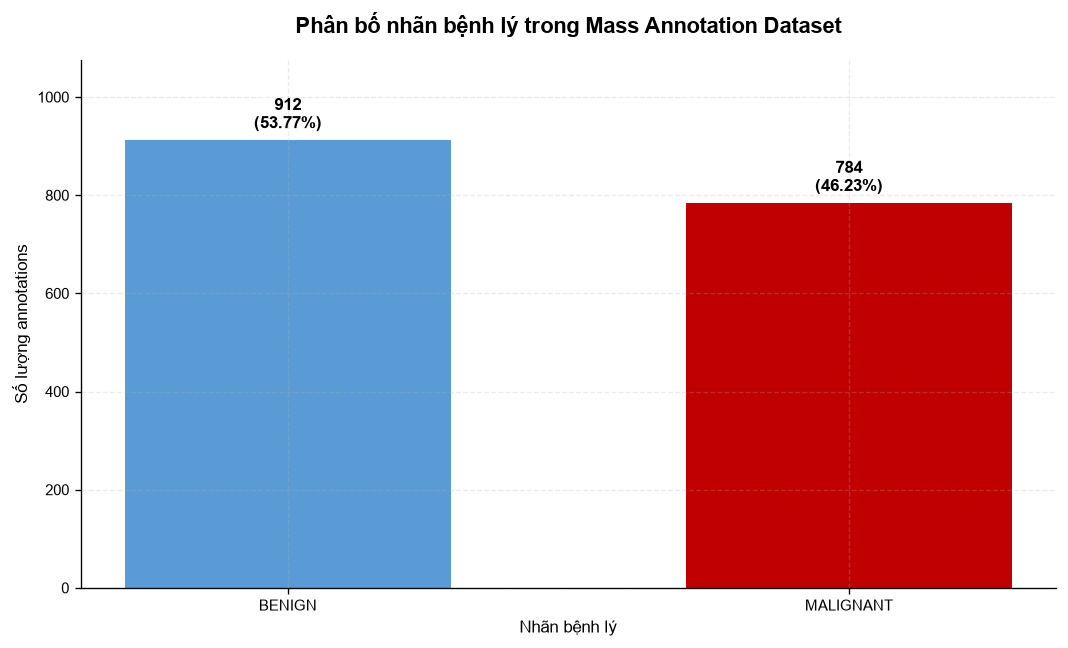

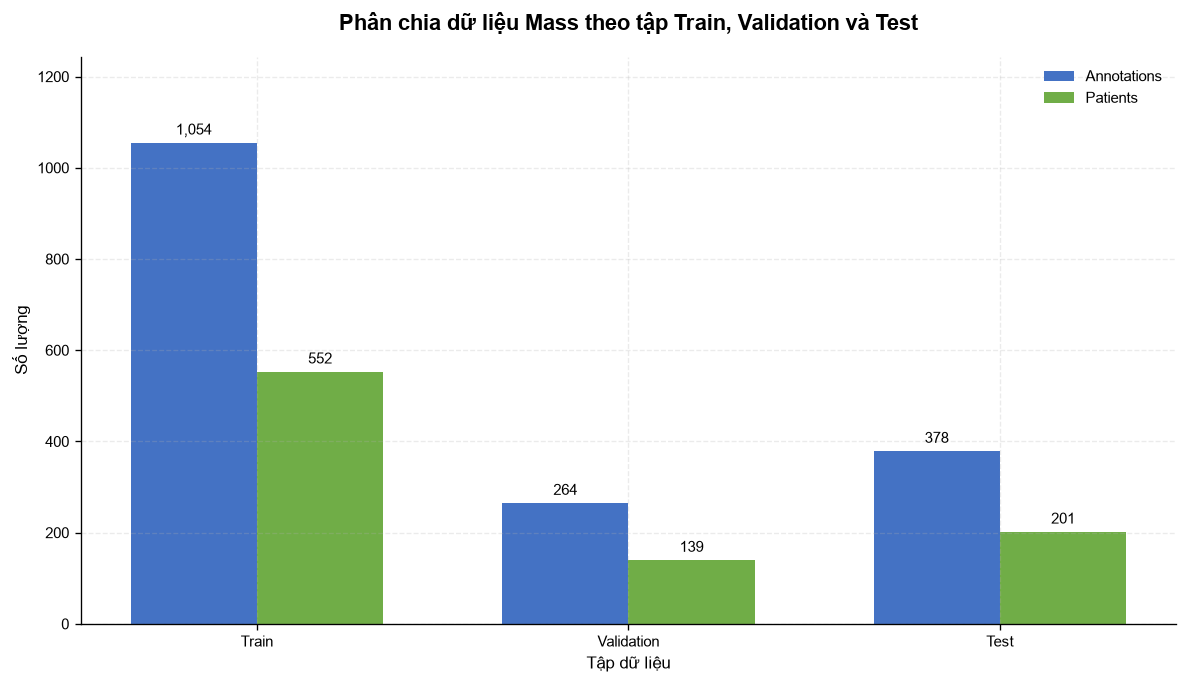

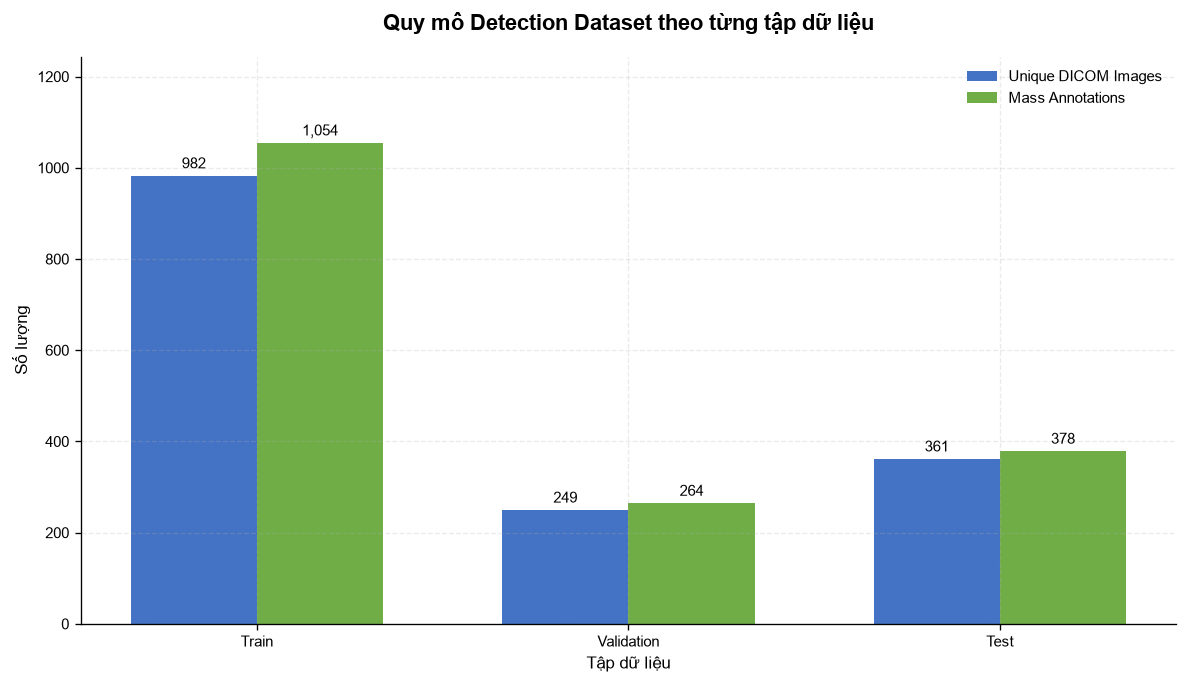

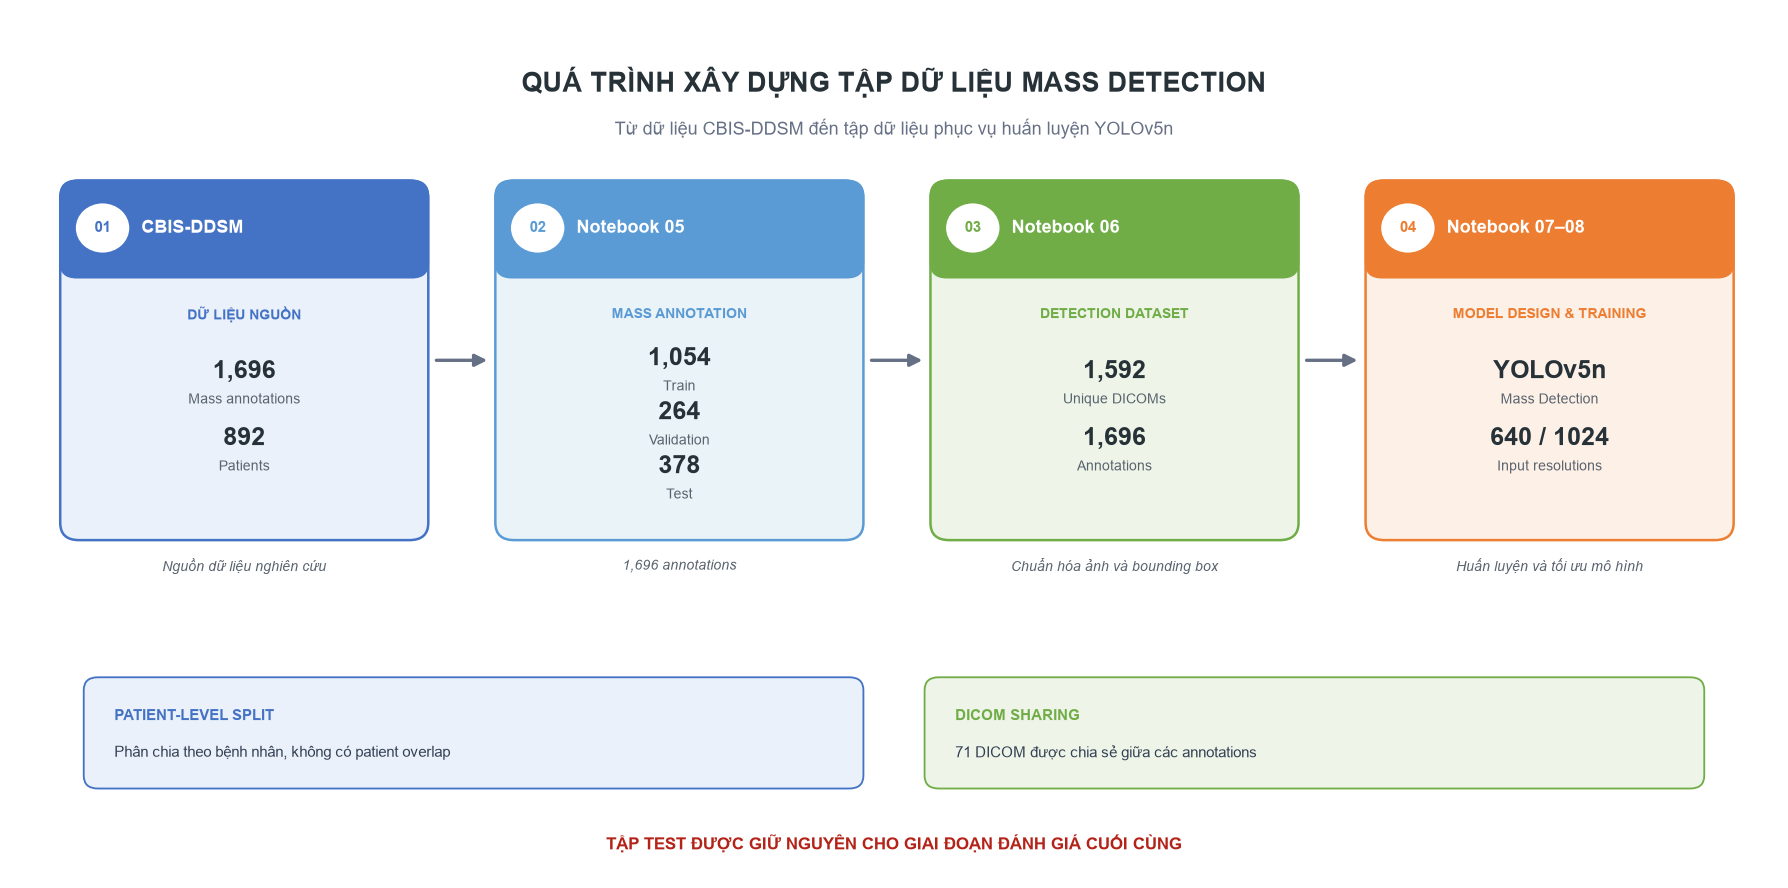

10.3 — TRỰC QUAN HÓA DỮ LIỆU VÀ QUÁ TRÌNH XÂY DỰNG TẬP DỮ LIỆU

1. TỔNG QUAN DATASET


,Chỉ tiêu,Giá trị,Nguồn
0,Tổng số Mass annotations,1696,Notebook 05
1,Tổng số bệnh nhân,892,Notebook 05
2,Số ảnh DICOM duy nhất,1592,Notebook 06
3,Số DICOM được chia sẻ giữa các annotations,71,Notebook 06
4,Tổng số annotations trong Detection Dataset,1696,Notebook 06



2. PHÂN CHIA ANNOTATIONS VÀ PATIENTS


,Split,Annotations,Patients,Annotation_Ratio_Percent,Patient_Ratio_Percent
0,Train,1054,552,62.15,61.88
1,Validation,264,139,15.57,15.58
2,Test,378,201,22.29,22.53



3. PHÂN BỐ NHÃN BỆNH LÝ


,Pathology,Count,Percentage
0,BENIGN,912,53.77
1,MALIGNANT,784,46.23



4. QUY MÔ DETECTION DATASET


,Split,Unique_DICOM_Images,Annotations,Annotations_Per_Image
0,Train,982,1054,1.073
1,Validation,249,264,1.060
2,Test,361,378,1.047



5. KIỂM TRA TÍNH TOÀN VẸN
Số liệu: Tổng annotation Notebook 05                             : PASS
Số liệu: Tổng bệnh nhân theo split                               : PASS
Số liệu: Tổng nhãn bệnh lý                                       : PASS
Số liệu: Tổng annotation Notebook 06                             : PASS
Số liệu: Tổng ảnh DICOM theo split                               : PASS
Số liệu: Số annotation Train nhất quán                           : PASS
Số liệu: Số annotation Validation nhất quán                      : PASS
Số liệu: Số annotation Test nhất quán                            : PASS
Biểu đồ: nb10_3_figure_01_pathology_distribution.png             : PASS
Biểu đồ: nb10_3_figure_02_dataset_split.png                      : PASS
Biểu đồ: nb10_3_figure_03_detection_dataset_scale.png            : PASS
Biểu đồ: nb10_3_figure_04_dataset_construction_pipeline.png      : PASS
Bảng: nb10_3_dataset_overview.csv                                : PASS
Bảng: nb10_3_annotation_split_summary

In [5]:
# 10.3 — TRỰC QUAN HÓA DỮ LIỆU VÀ QUÁ TRÌNH XÂY DỰNG TẬP DỮ LIỆU

import numpy as np
import pandas as pd
from IPython.display import display

# ============================================================
# 1. KIỂM TRA ĐIỀU KIỆN VÀ CẤU HÌNH
# ============================================================

required_variables = [
    "FIGURES_DIR",
    "TABLES_DIR",
    "REPORTS_DIR",
    "COLOR_CONFIG"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Thiếu cấu hình từ 10.1: "
        + ", ".join(missing_variables)
        + ". Hãy chạy lại Notebook 10 từ đầu."
    )

if "NB10_2_PASS" not in globals() or not NB10_2_PASS:
    raise RuntimeError(
        "Mục 10.2 chưa PASS. Hãy hoàn thành kiểm kê nguồn trước."
    )


# ============================================================
# 2. TỔNG HỢP SỐ LIỆU ĐÃ XÁC LẬP TỪ NOTEBOOK 05–06
# ============================================================

# Notebook 05 — Mass Annotation Dataset
annotation_total = 1696
patient_total = 892

annotation_split = {
    "Train": 1054,
    "Validation": 264,
    "Test": 378
}

patient_split = {
    "Train": 552,
    "Validation": 139,
    "Test": 201
}

pathology_distribution = {
    "BENIGN": 912,
    "MALIGNANT": 784
}

original_split = {
    "Train": 1318,
    "Test": 378
}

# Notebook 06 — Detection Dataset
unique_dicom_total = 1592
shared_dicom_count = 71

detection_image_split = {
    "Train": 982,
    "Validation": 249,
    "Test": 361
}

detection_annotation_split = {
    "Train": 1054,
    "Validation": 264,
    "Test": 378
}

detection_annotation_total = sum(
    detection_annotation_split.values()
)

detection_image_total = sum(
    detection_image_split.values()
)

# Kiểm tra tính nhất quán của các số liệu
DATASET_CHECKS = {
    "Tổng annotation Notebook 05": (
        sum(annotation_split.values()) == annotation_total
    ),
    "Tổng bệnh nhân theo split": (
        sum(patient_split.values()) == patient_total
    ),
    "Tổng nhãn bệnh lý": (
        sum(pathology_distribution.values()) == annotation_total
    ),
    "Tổng annotation Notebook 06": (
        detection_annotation_total == annotation_total
    ),
    "Tổng ảnh DICOM theo split": (
        detection_image_total == unique_dicom_total
    ),
    "Số annotation Train nhất quán": (
        annotation_split["Train"]
        == detection_annotation_split["Train"]
    ),
    "Số annotation Validation nhất quán": (
        annotation_split["Validation"]
        == detection_annotation_split["Validation"]
    ),
    "Số annotation Test nhất quán": (
        annotation_split["Test"]
        == detection_annotation_split["Test"]
    )
}

if not all(DATASET_CHECKS.values()):
    raise RuntimeError(
        "Số liệu tổng hợp không nhất quán. "
        "Không tiếp tục tạo biểu đồ."
    )


# ============================================================
# 3. TẠO CÁC BẢNG TỔNG HỢP
# ============================================================

# 3.1. Tổng quan dữ liệu Mass
dataset_overview_df = pd.DataFrame([
    {
        "Chỉ tiêu": "Tổng số Mass annotations",
        "Giá trị": annotation_total,
        "Nguồn": "Notebook 05"
    },
    {
        "Chỉ tiêu": "Tổng số bệnh nhân",
        "Giá trị": patient_total,
        "Nguồn": "Notebook 05"
    },
    {
        "Chỉ tiêu": "Số ảnh DICOM duy nhất",
        "Giá trị": unique_dicom_total,
        "Nguồn": "Notebook 06"
    },
    {
        "Chỉ tiêu": "Số DICOM được chia sẻ giữa các annotations",
        "Giá trị": shared_dicom_count,
        "Nguồn": "Notebook 06"
    },
    {
        "Chỉ tiêu": "Tổng số annotations trong Detection Dataset",
        "Giá trị": detection_annotation_total,
        "Nguồn": "Notebook 06"
    }
])

# 3.2. Phân chia annotations và bệnh nhân
split_summary_df = pd.DataFrame({
    "Split": list(annotation_split.keys()),
    "Annotations": list(annotation_split.values()),
    "Patients": list(patient_split.values())
})

split_summary_df["Annotation_Ratio_Percent"] = (
    split_summary_df["Annotations"]
    / annotation_total * 100
).round(2)

split_summary_df["Patient_Ratio_Percent"] = (
    split_summary_df["Patients"]
    / patient_total * 100
).round(2)

# 3.3. Phân bố nhãn
pathology_df = pd.DataFrame({
    "Pathology": list(pathology_distribution.keys()),
    "Count": list(pathology_distribution.values())
})

pathology_df["Percentage"] = (
    pathology_df["Count"]
    / annotation_total * 100
).round(2)

# 3.4. Detection Dataset theo split
detection_split_df = pd.DataFrame({
    "Split": list(detection_image_split.keys()),
    "Unique_DICOM_Images": list(detection_image_split.values()),
    "Annotations": list(detection_annotation_split.values())
})

detection_split_df["Annotations_Per_Image"] = (
    detection_split_df["Annotations"]
    / detection_split_df["Unique_DICOM_Images"]
).round(3)

# 3.5. Original split và final split
original_split_df = pd.DataFrame({
    "Original_Split": list(original_split.keys()),
    "Annotations": list(original_split.values())
})

original_split_df["Percentage"] = (
    original_split_df["Annotations"]
    / annotation_total * 100
).round(2)


# ============================================================
# 4. BIỂU ĐỒ 1 — PHÂN BỐ NHÃN BỆNH LÝ
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5.5))

labels = pathology_df["Pathology"].tolist()
values = pathology_df["Count"].tolist()

colors = [
    COLOR_CONFIG["BENIGN"],
    COLOR_CONFIG["MALIGNANT"]
]

bars = ax.bar(
    labels,
    values,
    color=colors,
    width=0.58
)

ax.set_title(
    "Phân bố nhãn bệnh lý trong Mass Annotation Dataset",
    pad=16,
    fontweight="bold"
)

ax.set_xlabel("Nhãn bệnh lý")
ax.set_ylabel("Số lượng annotations")
ax.set_ylim(0, max(values) * 1.18)

for bar, value, percentage in zip(
    bars,
    values,
    pathology_df["Percentage"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 15,
        f"{value:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

fig.tight_layout()

figure_01_path = FIGURES_DIR / "nb10_3_figure_01_pathology_distribution.png"

save_figure(
    fig,
    figure_01_path.name,
    close=False
)

plt.show()


# ============================================================
# 5. BIỂU ĐỒ 2 — PHÂN CHIA ANNOTATIONS VÀ BỆNH NHÂN
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5.8))

x = np.arange(len(split_summary_df))
width = 0.34

bars_annotations = ax.bar(
    x - width / 2,
    split_summary_df["Annotations"],
    width,
    label="Annotations",
    color=COLOR_CONFIG["YOLO_Baseline"]
)

bars_patients = ax.bar(
    x + width / 2,
    split_summary_df["Patients"],
    width,
    label="Patients",
    color=COLOR_CONFIG["YOLO_Finetuned"]
)

ax.set_title(
    "Phân chia dữ liệu Mass theo tập Train, Validation và Test",
    pad=16,
    fontweight="bold"
)

ax.set_xlabel("Tập dữ liệu")
ax.set_ylabel("Số lượng")
ax.set_xticks(x)
ax.set_xticklabels(split_summary_df["Split"])
ax.legend(frameon=False)

ax.set_ylim(
    0,
    split_summary_df["Annotations"].max() * 1.18
)

for bars in [bars_annotations, bars_patients]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 12,
            f"{int(bar.get_height()):,}",
            ha="center",
            va="bottom",
            fontsize=9
        )

fig.tight_layout()

figure_02_path = FIGURES_DIR / "nb10_3_figure_02_dataset_split.png"

save_figure(
    fig,
    figure_02_path.name,
    close=False
)

plt.show()


# ============================================================
# 6. BIỂU ĐỒ 3 — ẢNH DICOM VÀ ANNOTATIONS TRONG DETECTION DATASET
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5.8))

x = np.arange(len(detection_split_df))
width = 0.34

bars_images = ax.bar(
    x - width / 2,
    detection_split_df["Unique_DICOM_Images"],
    width,
    label="Unique DICOM Images",
    color=COLOR_CONFIG["YOLO_Baseline"]
)

bars_annotations = ax.bar(
    x + width / 2,
    detection_split_df["Annotations"],
    width,
    label="Mass Annotations",
    color=COLOR_CONFIG["YOLO_Finetuned"]
)

ax.set_title(
    "Quy mô Detection Dataset theo từng tập dữ liệu",
    pad=16,
    fontweight="bold"
)

ax.set_xlabel("Tập dữ liệu")
ax.set_ylabel("Số lượng")
ax.set_xticks(x)
ax.set_xticklabels(detection_split_df["Split"])
ax.legend(frameon=False)

ax.set_ylim(
    0,
    detection_split_df["Annotations"].max() * 1.18
)

for bars in [bars_images, bars_annotations]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 10,
            f"{int(bar.get_height()):,}",
            ha="center",
            va="bottom",
            fontsize=9
        )

fig.tight_layout()

figure_03_path = FIGURES_DIR / "nb10_3_figure_03_detection_dataset_scale.png"

save_figure(
    fig,
    figure_03_path.name,
    close=False
)

plt.show()


# ============================================================
# 7. BIỂU ĐỒ 4 — QUÁ TRÌNH XÂY DỰNG DATASET (PHIÊN BẢN CẢI TIẾN)
# ============================================================

from matplotlib.patches import FancyBboxPatch, Circle

fig, ax = plt.subplots(figsize=(15, 7.5))

ax.set_xlim(0, 15)
ax.set_ylim(0, 8)
ax.axis("off")

# Màu sắc các giai đoạn
PIPELINE_COLORS = [
    {
        "main": "#4472C4",
        "light": "#EAF1FB",
        "border": "#4472C4"
    },
    {
        "main": "#5B9BD5",
        "light": "#EAF3F8",
        "border": "#5B9BD5"
    },
    {
        "main": "#70AD47",
        "light": "#EEF5E8",
        "border": "#70AD47"
    },
    {
        "main": "#ED7D31",
        "light": "#FDF0E7",
        "border": "#ED7D31"
    }
]

# Thông tin từng giai đoạn
pipeline_steps = [
    {
        "number": "01",
        "title": "CBIS-DDSM",
        "subtitle": "DỮ LIỆU NGUỒN",
        "metrics": [
            ("1,696", "Mass annotations"),
            ("892", "Patients")
        ],
        "note": "Nguồn dữ liệu nghiên cứu"
    },
    {
        "number": "02",
        "title": "Notebook 05",
        "subtitle": "MASS ANNOTATION",
        "metrics": [
            ("1,054", "Train"),
            ("264", "Validation"),
            ("378", "Test")
        ],
        "note": "1,696 annotations"
    },
    {
        "number": "03",
        "title": "Notebook 06",
        "subtitle": "DETECTION DATASET",
        "metrics": [
            ("1,592", "Unique DICOMs"),
            ("1,696", "Annotations")
        ],
        "note": "Chuẩn hóa ảnh và bounding box"
    },
    {
        "number": "04",
        "title": "Notebook 07–08",
        "subtitle": "MODEL DESIGN & TRAINING",
        "metrics": [
            ("YOLOv5n", "Mass Detection"),
            ("640 / 1024", "Input resolutions")
        ],
        "note": "Huấn luyện và tối ưu mô hình"
    }
]

# Vị trí và kích thước thẻ
card_width = 3.05
card_height = 3.25
card_y = 3.15

card_positions = [0.45, 4.15, 7.85, 11.55]

# Tiêu đề chính
ax.text(
    7.5,
    7.35,
    "QUÁ TRÌNH XÂY DỰNG TẬP DỮ LIỆU MASS DETECTION",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold",
    color="#263238"
)

ax.text(
    7.5,
    6.92,
    "Từ dữ liệu CBIS-DDSM đến tập dữ liệu phục vụ huấn luyện YOLOv5n",
    ha="center",
    va="center",
    fontsize=10.5,
    color="#667085"
)

# Vẽ các thẻ
for index, (step, x, colors) in enumerate(
    zip(pipeline_steps, card_positions, PIPELINE_COLORS)
):

    # Khung thẻ
    card = FancyBboxPatch(
        (x, card_y),
        card_width,
        card_height,
        boxstyle="round,pad=0.04,rounding_size=0.16",
        facecolor=colors["light"],
        edgecolor=colors["border"],
        linewidth=1.5,
        zorder=1
    )

    ax.add_patch(card)

    # Thanh tiêu đề
    header = FancyBboxPatch(
        (x, card_y + card_height - 0.82),
        card_width,
        0.82,
        boxstyle="round,pad=0.04,rounding_size=0.14",
        facecolor=colors["main"],
        edgecolor=colors["main"],
        linewidth=1,
        zorder=2
    )

    ax.add_patch(header)

    # Số thứ tự
    circle = Circle(
        (x + 0.32, card_y + card_height - 0.40),
        0.22,
        facecolor="white",
        edgecolor="white",
        linewidth=1,
        zorder=3
    )

    ax.add_patch(circle)

    ax.text(
        x + 0.32,
        card_y + card_height - 0.40,
        step["number"],
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        color=colors["main"],
        zorder=4
    )

    # Tên giai đoạn
    ax.text(
        x + 0.65,
        card_y + card_height - 0.40,
        step["title"],
        ha="left",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="white",
        zorder=4
    )

    # Nhãn phụ
    ax.text(
        x + card_width / 2,
        card_y + 2.05,
        step["subtitle"],
        ha="center",
        va="center",
        fontsize=8.5,
        fontweight="bold",
        color=colors["main"]
    )

    # Các thông số
    metric_y_positions = (
        [card_y + 1.52, card_y + 1.02, card_y + 0.52]
        if len(step["metrics"]) == 3
        else [card_y + 1.40, card_y + 0.78]
    )

    for (value, label), metric_y in zip(
        step["metrics"],
        metric_y_positions
    ):

        ax.text(
            x + card_width / 2,
            metric_y + 0.12,
            value,
            ha="center",
            va="center",
            fontsize=15 if len(value) < 12 else 12,
            fontweight="bold",
            color="#263238"
        )

        ax.text(
            x + card_width / 2,
            metric_y - 0.14,
            label,
            ha="center",
            va="center",
            fontsize=8.5,
            color="#59636E"
        )

    # Ghi chú dưới thẻ
    ax.text(
        x + card_width / 2,
        card_y - 0.28,
        step["note"],
        ha="center",
        va="center",
        fontsize=8.5,
        color="#59636E",
        style="italic"
    )


# Mũi tên kết nối giữa các giai đoạn
for index in range(3):
    start_x = card_positions[index] + card_width + 0.08
    end_x = card_positions[index + 1] - 0.08

    ax.annotate(
        "",
        xy=(end_x, card_y + card_height / 2),
        xytext=(start_x, card_y + card_height / 2),
        arrowprops={
            "arrowstyle": "-|>",
            "color": "#667085",
            "linewidth": 2,
            "mutation_scale": 15
        },
        zorder=5
    )


# Ghi chú phương pháp luận phía dưới
callout_y = 0.85
callout_height = 0.95

callouts = [
    {
        "x": 0.65,
        "width": 6.55,
        "title": "PATIENT-LEVEL SPLIT",
        "description": "Phân chia theo bệnh nhân, không có patient overlap",
        "color": "#4472C4",
        "background": "#EAF1FB"
    },
    {
        "x": 7.8,
        "width": 6.55,
        "title": "DICOM SHARING",
        "description": "71 DICOM được chia sẻ giữa các annotations",
        "color": "#70AD47",
        "background": "#EEF5E8"
    }
]

for item in callouts:

    box = FancyBboxPatch(
        (item["x"], callout_y),
        item["width"],
        callout_height,
        boxstyle="round,pad=0.04,rounding_size=0.12",
        facecolor=item["background"],
        edgecolor=item["color"],
        linewidth=1.1
    )

    ax.add_patch(box)

    ax.text(
        item["x"] + 0.22,
        callout_y + 0.63,
        item["title"],
        ha="left",
        va="center",
        fontsize=9,
        fontweight="bold",
        color=item["color"]
    )

    ax.text(
        item["x"] + 0.22,
        callout_y + 0.29,
        item["description"],
        ha="left",
        va="center",
        fontsize=9,
        color="#344054"
    )


# Nhấn mạnh nguyên tắc giữ nguyên Test
ax.text(
    7.5,
    0.30,
    "TẬP TEST ĐƯỢC GIỮ NGUYÊN CHO GIAI ĐOẠN ĐÁNH GIÁ CUỐI CÙNG",
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    color="#B42318"
)

fig.tight_layout()

figure_04_path = (
    FIGURES_DIR /
    "nb10_3_figure_04_dataset_construction_pipeline.png"
)

save_figure(
    fig,
    figure_04_path.name,
    dpi=300,
    close=False
)

plt.show()

# ============================================================
# 8. LƯU CÁC BẢNG SỐ LIỆU
# ============================================================

tables_to_save = {
    "nb10_3_dataset_overview.csv": dataset_overview_df,
    "nb10_3_annotation_split_summary.csv": split_summary_df,
    "nb10_3_pathology_distribution.csv": pathology_df,
    "nb10_3_detection_split_summary.csv": detection_split_df,
    "nb10_3_original_split_summary.csv": original_split_df
}

saved_table_paths = []

for filename, dataframe in tables_to_save.items():
    output_path = TABLES_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    saved_table_paths.append(str(output_path))


# ============================================================
# 9. KIỂM TRA TÍNH TOÀN VẸN KẾT QUẢ 10.3
# ============================================================

figure_paths = [
    figure_01_path,
    figure_02_path,
    figure_03_path,
    figure_04_path
]

figure_checks = {
    path.name: (
        path.exists() and path.stat().st_size > 0
    )
    for path in figure_paths
}

table_checks = {
    Path(path).name: (
        Path(path).exists() and Path(path).stat().st_size > 0
    )
    for path in saved_table_paths
}

NB10_3_CHECKS = {
    **{
        f"Số liệu: {name}": status
        for name, status in DATASET_CHECKS.items()
    },
    **{
        f"Biểu đồ: {name}": status
        for name, status in figure_checks.items()
    },
    **{
        f"Bảng: {name}": status
        for name, status in table_checks.items()
    }
}

NB10_3_PASS = all(NB10_3_CHECKS.values())

NB10_3_REPORT = {
    "section": "10.3",
    "title": "Trực quan hóa dữ liệu và quá trình xây dựng tập dữ liệu",
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "dataset": {
        "annotation_total": annotation_total,
        "patient_total": patient_total,
        "pathology_distribution": pathology_distribution,
        "annotation_split": annotation_split,
        "patient_split": patient_split,
        "unique_dicom_total": unique_dicom_total,
        "shared_dicom_count": shared_dicom_count,
        "detection_image_split": detection_image_split,
        "detection_annotation_split": detection_annotation_split
    },
    "figure_files": [
        str(path) for path in figure_paths
    ],
    "table_files": saved_table_paths,
    "checks": NB10_3_CHECKS,
    "status": "PASS" if NB10_3_PASS else "FAIL"
}

NB10_3_REPORT_PATH = (
    REPORTS_DIR / "nb10_3_dataset_visualization_report.json"
)

with open(NB10_3_REPORT_PATH, "w", encoding="utf-8") as file:
    json.dump(
        NB10_3_REPORT,
        file,
        ensure_ascii=False,
        indent=4
    )


# ============================================================
# 10. HIỂN THỊ BẢNG TỔNG HỢP VÀ KẾT LUẬN
# ============================================================

print("10.3 — TRỰC QUAN HÓA DỮ LIỆU VÀ QUÁ TRÌNH XÂY DỰNG TẬP DỮ LIỆU")

print("\n1. TỔNG QUAN DATASET")
display(dataset_overview_df)

print("\n2. PHÂN CHIA ANNOTATIONS VÀ PATIENTS")
display(split_summary_df)

print("\n3. PHÂN BỐ NHÃN BỆNH LÝ")
display(pathology_df)

print("\n4. QUY MÔ DETECTION DATASET")
display(detection_split_df)

print("\n5. KIỂM TRA TÍNH TOÀN VẸN")

for check_name, check_status in NB10_3_CHECKS.items():
    print(
        f"{check_name:<65}: "
        f"{'PASS' if check_status else 'FAIL'}"
    )

print("\n6. TỆP ĐẦU RA")

for path in figure_paths:
    print(f"Biểu đồ: {path}")

for path in saved_table_paths:
    print(f"Bảng: {path}")

print(f"Báo cáo: {NB10_3_REPORT_PATH}")

print("\nKẾT LUẬN 10.3")
print(f"Số biểu đồ đã tạo: {len(figure_paths)}")
print(f"Số bảng đã xuất  : {len(saved_table_paths)}")
print(f"Trạng thái       : {'PASS' if NB10_3_PASS else 'FAIL'}")

if not NB10_3_PASS:
    raise RuntimeError(
        "10.3 chưa hoàn thành. "
        "Vui lòng kiểm tra các mục FAIL."
    )


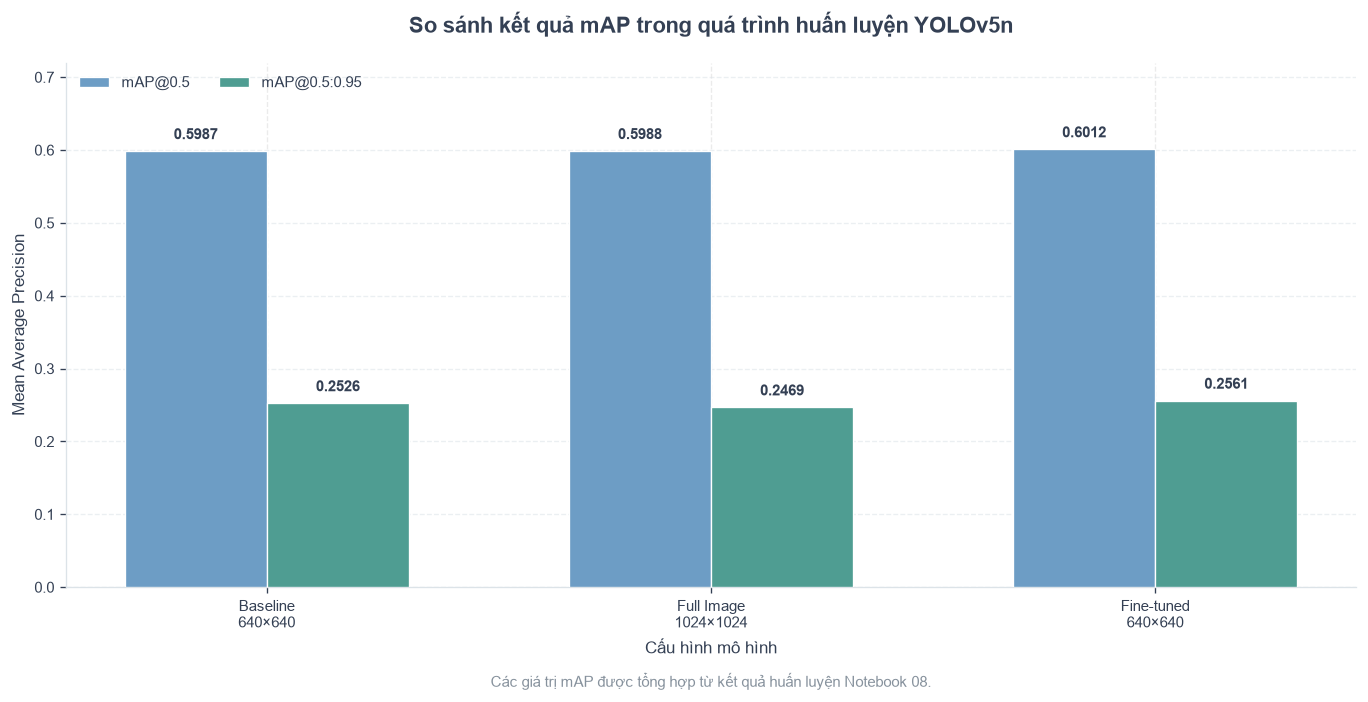

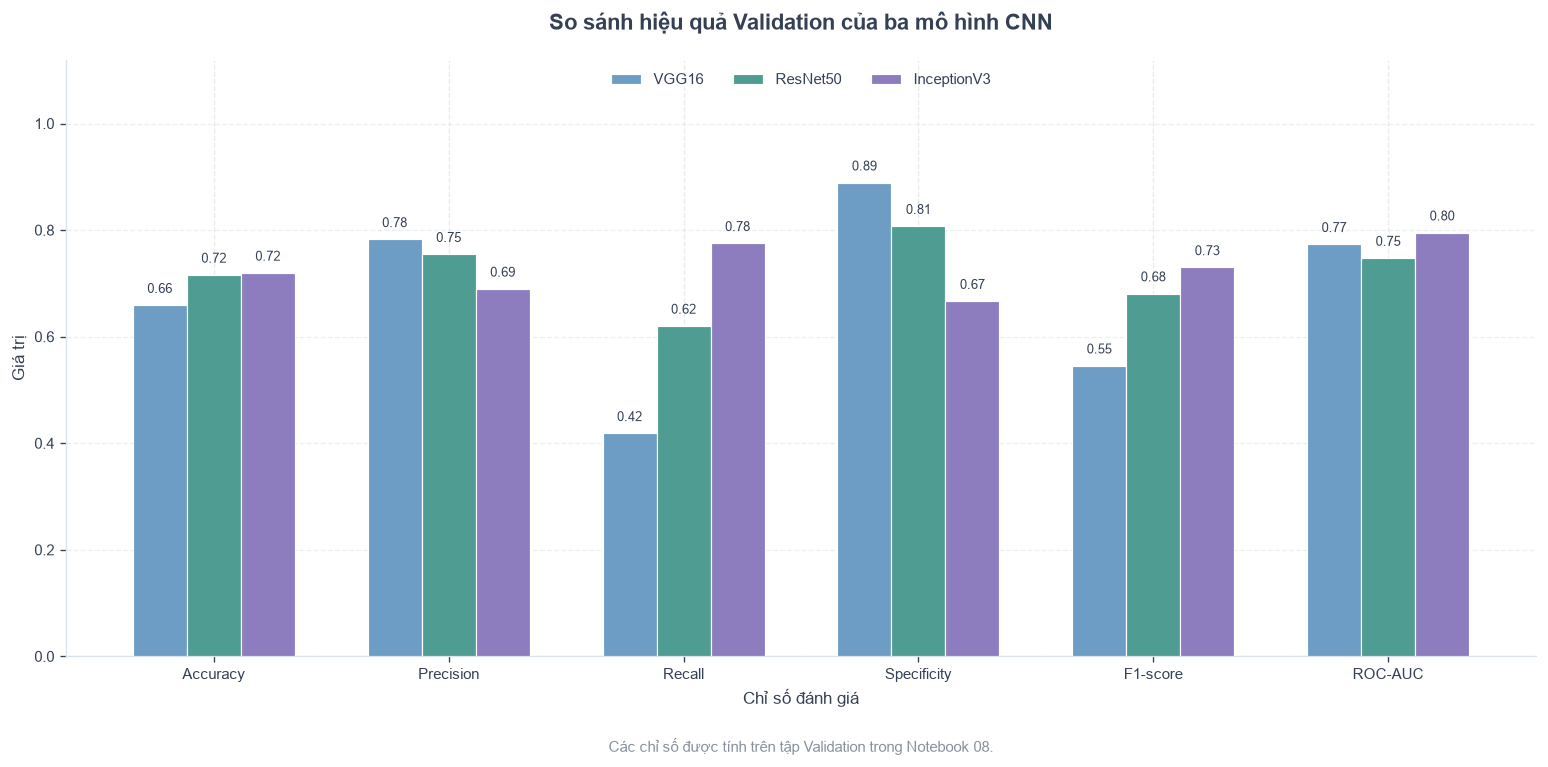

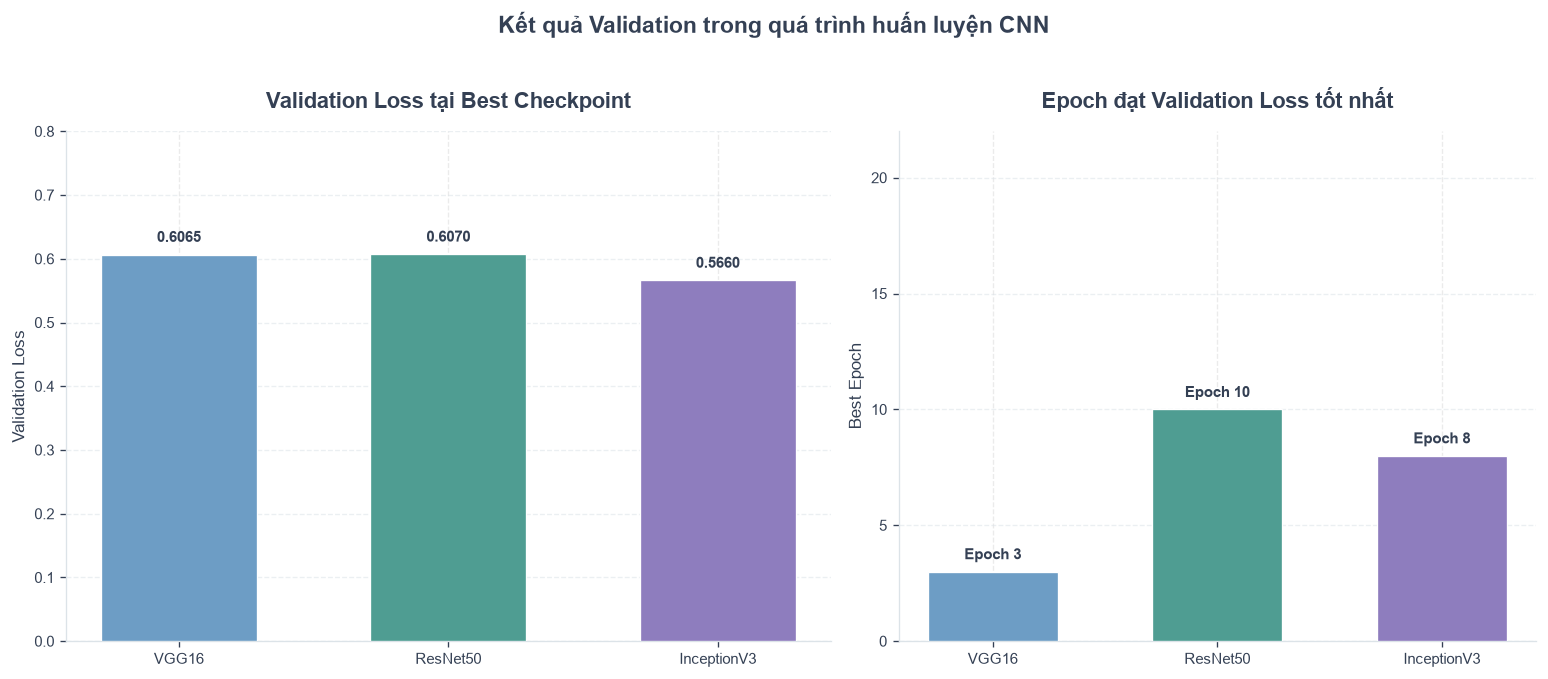

10.4 — TRỰC QUAN HÓA KẾT QUẢ HUẤN LUYỆN YOLO VÀ CNN

1. KẾT QUẢ HUẤN LUYỆN YOLO


,Model,Configuration,Epochs,Best_Precision,Precision_Epoch,Best_Recall,Recall_Epoch,mAP50,mAP50_95,Training_Time_Minutes,Metric_Note
0,YOLOv5n Baseline 640,Full Image 640×640,30,0.73111,14.0,0.86742,1.0,0.59867,0.25263,431.36,Precision epoch 14; Recall epoch 1; mAP tại epoch 29
1,YOLOv5n Full 1024,Full Image 1024×1024,30,NaN,NaN,NaN,NaN,0.59878,0.24694,595.84,Giá trị mAP được ghi nhận trong kết quả huấn luyện
2,YOLOv5n Fine-tuned 640,Fine-tuned 640×640,12,0.56632,NaN,0.60985,NaN,0.60121,0.25610,NaN,Các giá trị tốt nhất được ghi nhận trong quá trình fine-tuning



2. KẾT QUẢ VALIDATION CỦA CNN


,Model,Epochs_Trained,Best_Epoch,Validation_Loss,Accuracy,Precision,Recall,Specificity,F1_Score,ROC_AUC
0,VGG16,10,3,0.606518,0.659091,0.782609,0.418605,0.888889,0.545455,0.773356
1,ResNet50,17,10,0.607034,0.715909,0.754717,0.620155,0.807407,0.680851,0.747545
2,InceptionV3,15,8,0.565994,0.719697,0.689655,0.775194,0.666667,0.729927,0.795177



3. KIỂM TRA TÍNH TOÀN VẸN
YOLO: Có đủ 3 cấu hình YOLO                                      : PASS
YOLO: Có đủ mAP50                                                : PASS
YOLO: Có đủ mAP50-95                                             : PASS
YOLO: mAP50 trong khoảng 0–1                                     : PASS
YOLO: mAP50-95 trong khoảng 0–1                                  : PASS
CNN: Có đủ 3 mô hình CNN                                         : PASS
CNN: Không thiếu Validation Loss                                 : PASS
CNN: Không thiếu Best Epoch                                      : PASS
CNN: Các chỉ số Validation trong khoảng 0–1                      : PASS
CNN: Best Epoch không vượt số Epoch đã huấn luyện                : PASS
Biểu đồ: nb10_4_figure_01_yolo_map_comparison.png                : PASS
Biểu đồ: nb10_4_figure_02_cnn_validation_metrics.png             : PASS
Biểu đồ: nb10_4_figure_03_cnn_validation_loss_best_epoch.png     : PASS
Bảng: nb10_4_yolo_training_summary.cs

In [8]:
# 10.4 — TRỰC QUAN HÓA KẾT QUẢ HUẤN LUYỆN YOLO VÀ CNN

from pathlib import Path
from datetime import datetime
import json
from IPython.display import display

# ============================================================
# 1. KIỂM TRA MÔI TRƯỜNG VÀ CẤU HÌNH
# ============================================================

required_variables = [
    "FIGURES_DIR",
    "TABLES_DIR",
    "REPORTS_DIR",
    "save_figure",
    "NB10_3_PASS"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Thiếu cấu hình từ các mục trước: "
        + ", ".join(missing_variables)
    )

if not NB10_3_PASS:
    raise RuntimeError(
        "Notebook 10.3 chưa PASS. Không thể tiếp tục 10.4."
    )

FIGURES_DIR = Path(FIGURES_DIR)
TABLES_DIR = Path(TABLES_DIR)
REPORTS_DIR = Path(REPORTS_DIR)

for directory in [FIGURES_DIR, TABLES_DIR, REPORTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


# Bảng màu thống nhất cho toàn bộ biểu đồ 10.4
COLORS = {
    "navy": "#355070",
    "blue": "#6D9DC5",
    "teal": "#4F9D92",
    "green": "#83B692",
    "purple": "#8E7DBE",
    "orange": "#D99A6C",
    "red": "#C97878",
    "gray": "#87929D",
    "light": "#EAF0F4",
    "text": "#344054",
    "grid": "#DCE3E8"
}

CNN_COLORS = {
    "VGG16": COLORS["blue"],
    "ResNet50": COLORS["teal"],
    "InceptionV3": COLORS["purple"]
}

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.labelcolor": COLORS["text"],
    "xtick.color": COLORS["text"],
    "ytick.color": COLORS["text"],
    "text.color": COLORS["text"],
    "axes.edgecolor": COLORS["grid"],
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white"
})


# ============================================================
# 2. TỔNG HỢP KẾT QUẢ HUẤN LUYỆN YOLOV5N
# ============================================================

# Các chỉ số tốt nhất có thể xuất hiện ở những epoch khác nhau.
# Không xem chúng là kết quả của cùng một checkpoint.

yolo_training_records = [
    {
        "Model": "YOLOv5n Baseline 640",
        "Configuration": "Full Image 640×640",
        "Epochs": 30,
        "Best_Precision": 0.73111,
        "Precision_Epoch": 14,
        "Best_Recall": 0.86742,
        "Recall_Epoch": 1,
        "mAP50": 0.59867,
        "mAP50_95": 0.25263,
        "Training_Time_Minutes": 431.36,
        "Metric_Note": (
            "Precision epoch 14; Recall epoch 1; "
            "mAP tại epoch 29"
        )
    },
    {
        "Model": "YOLOv5n Full 1024",
        "Configuration": "Full Image 1024×1024",
        "Epochs": 30,
        "Best_Precision": None,
        "Precision_Epoch": None,
        "Best_Recall": None,
        "Recall_Epoch": None,
        "mAP50": 0.59878,
        "mAP50_95": 0.24694,
        "Training_Time_Minutes": 595.84,
        "Metric_Note": (
            "Giá trị mAP được ghi nhận trong "
            "kết quả huấn luyện"
        )
    },
    {
        "Model": "YOLOv5n Fine-tuned 640",
        "Configuration": "Fine-tuned 640×640",
        "Epochs": 12,
        "Best_Precision": 0.56632,
        "Precision_Epoch": None,
        "Best_Recall": 0.60985,
        "Recall_Epoch": None,
        "mAP50": 0.60121,
        "mAP50_95": 0.25610,
        "Training_Time_Minutes": None,
        "Metric_Note": (
            "Các giá trị tốt nhất được ghi nhận "
            "trong quá trình fine-tuning"
        )
    }
]

yolo_training_df = pd.DataFrame(yolo_training_records)


# ============================================================
# 3. TỔNG HỢP KẾT QUẢ HUẤN LUYỆN CNN
# ============================================================

cnn_training_records = [
    {
        "Model": "VGG16",
        "Epochs_Trained": 10,
        "Best_Epoch": 3,
        "Validation_Loss": 0.606518,
        "Accuracy": 0.659091,
        "Precision": 0.782609,
        "Recall": 0.418605,
        "Specificity": 0.888889,
        "F1_Score": 0.545455,
        "ROC_AUC": 0.773356
    },
    {
        "Model": "ResNet50",
        "Epochs_Trained": 17,
        "Best_Epoch": 10,
        "Validation_Loss": 0.607034,
        "Accuracy": 0.715909,
        "Precision": 0.754717,
        "Recall": 0.620155,
        "Specificity": 0.807407,
        "F1_Score": 0.680851,
        "ROC_AUC": 0.747545
    },
    {
        "Model": "InceptionV3",
        "Epochs_Trained": 15,
        "Best_Epoch": 8,
        "Validation_Loss": 0.565994,
        "Accuracy": 0.719697,
        "Precision": 0.689655,
        "Recall": 0.775194,
        "Specificity": 0.666667,
        "F1_Score": 0.729927,
        "ROC_AUC": 0.795177
    }
]

cnn_training_df = pd.DataFrame(cnn_training_records)

cnn_metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1_Score",
    "ROC_AUC"
]

cnn_metric_labels = [
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1-score",
    "ROC-AUC"
]


# ============================================================
# 4. KIỂM TRA TÍNH HỢP LỆ CỦA SỐ LIỆU
# ============================================================

YOLO_CHECKS = {
    "Có đủ 3 cấu hình YOLO": len(yolo_training_df) == 3,
    "Có đủ mAP50": yolo_training_df["mAP50"].notna().all(),
    "Có đủ mAP50-95": yolo_training_df["mAP50_95"].notna().all(),
    "mAP50 trong khoảng 0–1": (
        yolo_training_df["mAP50"].between(0, 1).all()
    ),
    "mAP50-95 trong khoảng 0–1": (
        yolo_training_df["mAP50_95"].between(0, 1).all()
    )
}

CNN_CHECKS = {
    "Có đủ 3 mô hình CNN": len(cnn_training_df) == 3,
    "Không thiếu Validation Loss": (
        cnn_training_df["Validation_Loss"].notna().all()
    ),
    "Không thiếu Best Epoch": (
        cnn_training_df["Best_Epoch"].notna().all()
    ),
    "Các chỉ số Validation trong khoảng 0–1": (
        cnn_training_df[cnn_metric_columns]
        .apply(lambda column: column.between(0, 1).all())
        .all()
    ),
    "Best Epoch không vượt số Epoch đã huấn luyện": (
        (
            cnn_training_df["Best_Epoch"]
            <= cnn_training_df["Epochs_Trained"]
        ).all()
    )
}

# Chuyển tất cả kết quả kiểm tra thành bool Python
YOLO_CHECKS = {
    key: bool(value)
    for key, value in YOLO_CHECKS.items()
}

CNN_CHECKS = {
    key: bool(value)
    for key, value in CNN_CHECKS.items()
}

if not all(YOLO_CHECKS.values()):
    raise ValueError("Số liệu YOLO không hợp lệ.")

if not all(CNN_CHECKS.values()):
    raise ValueError("Số liệu CNN không hợp lệ.")


# ============================================================
# 5. BIỂU ĐỒ 1 — SO SÁNH mAP CỦA CÁC CẤU HÌNH YOLO
# ============================================================

fig, ax = plt.subplots(figsize=(11.5, 6))

x = np.arange(len(yolo_training_df))
width = 0.32

bars_map50 = ax.bar(
    x - width / 2,
    yolo_training_df["mAP50"],
    width,
    label="mAP@0.5",
    color=COLORS["blue"],
    edgecolor="white",
    linewidth=0.8,
    zorder=3
)

bars_map5095 = ax.bar(
    x + width / 2,
    yolo_training_df["mAP50_95"],
    width,
    label="mAP@0.5:0.95",
    color=COLORS["teal"],
    edgecolor="white",
    linewidth=0.8,
    zorder=3
)

ax.set_title(
    "So sánh kết quả mAP trong quá trình huấn luyện YOLOv5n",
    pad=18
)

ax.set_ylabel("Mean Average Precision")
ax.set_xlabel("Cấu hình mô hình")

ax.set_xticks(x)
ax.set_xticklabels([
    "Baseline\n640×640",
    "Full Image\n1024×1024",
    "Fine-tuned\n640×640"
])

ax.set_ylim(0, 0.72)
ax.set_yticks(np.arange(0, 0.71, 0.1))
ax.grid(axis="y", linestyle="--", alpha=0.55,
        color=COLORS["grid"], zorder=0)

ax.legend(
    frameon=False,
    loc="upper left",
    ncol=2
)

for bars in [bars_map50, bars_map5095]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.012,
            f"{bar.get_height():.4f}",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )

ax.text(
    0.5,
    -0.19,
    "Các giá trị mAP được tổng hợp từ kết quả huấn luyện Notebook 08.",
    transform=ax.transAxes,
    ha="center",
    fontsize=9,
    color=COLORS["gray"]
)

fig.tight_layout()

figure_01_path = (
    FIGURES_DIR /
    "nb10_4_figure_01_yolo_map_comparison.png"
)

save_figure(fig, figure_01_path.name)
plt.show()


# ============================================================
# 6. BIỂU ĐỒ 2 — SO SÁNH CÁC CHỈ SỐ VALIDATION CỦA CNN
# ============================================================

fig, ax = plt.subplots(figsize=(13, 6.5))

x = np.arange(len(cnn_metric_columns))
width = 0.23

for index, row in cnn_training_df.iterrows():

    model_name = row["Model"]

    values = [
        row[column]
        for column in cnn_metric_columns
    ]

    bars = ax.bar(
        x + (index - 1) * width,
        values,
        width,
        label=model_name,
        color=CNN_COLORS[model_name],
        edgecolor="white",
        linewidth=0.7,
        zorder=3
    )

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.018,
            f"{bar.get_height():.2f}",
            ha="center",
            va="bottom",
            fontsize=7.5
        )

ax.set_title(
    "So sánh hiệu quả Validation của ba mô hình CNN",
    pad=18
)

ax.set_xlabel("Chỉ số đánh giá")
ax.set_ylabel("Giá trị")

ax.set_xticks(x)
ax.set_xticklabels(cnn_metric_labels)

ax.set_ylim(0, 1.12)
ax.set_yticks(np.arange(0, 1.01, 0.2))

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.55,
    color=COLORS["grid"],
    zorder=0
)

ax.legend(
    frameon=False,
    ncol=3,
    loc="upper center"
)

ax.text(
    0.5,
    -0.16,
    "Các chỉ số được tính trên tập Validation trong Notebook 08.",
    transform=ax.transAxes,
    ha="center",
    fontsize=9,
    color=COLORS["gray"]
)

fig.tight_layout()

figure_02_path = (
    FIGURES_DIR /
    "nb10_4_figure_02_cnn_validation_metrics.png"
)

save_figure(fig, figure_02_path.name)
plt.show()


# ============================================================
# 7. BIỂU ĐỒ 3 — VALIDATION LOSS VÀ BEST EPOCH CỦA CNN
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5.5),
    gridspec_kw={"width_ratios": [1.2, 1]}
)

# 7.1. Validation Loss
ax = axes[0]

loss_bars = ax.bar(
    cnn_training_df["Model"],
    cnn_training_df["Validation_Loss"],
    color=[
        CNN_COLORS[model]
        for model in cnn_training_df["Model"]
    ],
    width=0.58,
    edgecolor="white",
    linewidth=0.8,
    zorder=3
)

ax.set_title(
    "Validation Loss tại Best Checkpoint",
    pad=14
)

ax.set_ylabel("Validation Loss")
ax.set_ylim(0, 0.8)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.55,
    color=COLORS["grid"],
    zorder=0
)

for bar in loss_bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{bar.get_height():.4f}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

# 7.2. Best Epoch
ax = axes[1]

epoch_bars = ax.bar(
    cnn_training_df["Model"],
    cnn_training_df["Best_Epoch"],
    color=[
        CNN_COLORS[model]
        for model in cnn_training_df["Model"]
    ],
    width=0.58,
    edgecolor="white",
    linewidth=0.8,
    zorder=3
)

ax.set_title(
    "Epoch đạt Validation Loss tốt nhất",
    pad=14
)

ax.set_ylabel("Best Epoch")
ax.set_ylim(0, 22)
ax.set_yticks(np.arange(0, 21, 5))

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.55,
    color=COLORS["grid"],
    zorder=0
)

for bar in epoch_bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.4,
        f"Epoch {int(bar.get_height())}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

fig.suptitle(
    "Kết quả Validation trong quá trình huấn luyện CNN",
    fontsize=14,
    fontweight="bold",
    y=1.02
)

fig.tight_layout()

figure_03_path = (
    FIGURES_DIR /
    "nb10_4_figure_03_cnn_validation_loss_best_epoch.png"
)

save_figure(fig, figure_03_path.name)
plt.show()


# ============================================================
# 8. CHUẨN BỊ CÁC BẢNG KẾT QUẢ
# ============================================================

yolo_export_df = yolo_training_df.copy()

cnn_export_df = cnn_training_df.copy()

for column in [
    "Best_Precision",
    "Best_Recall",
    "mAP50",
    "mAP50_95"
]:
    yolo_export_df[column] = (
        yolo_export_df[column].round(5)
    )

for column in [
    "Validation_Loss",
    *cnn_metric_columns
]:
    cnn_export_df[column] = (
        cnn_export_df[column].round(6)
    )

cnn_comparison_df = cnn_export_df[
    [
        "Model",
        "Epochs_Trained",
        "Best_Epoch",
        "Validation_Loss",
        "Accuracy",
        "Precision",
        "Recall",
        "Specificity",
        "F1_Score",
        "ROC_AUC"
    ]
].copy()


# ============================================================
# 9. XUẤT BẢNG KẾT QUẢ
# ============================================================

tables_to_save = {
    "nb10_4_yolo_training_summary.csv": yolo_export_df,
    "nb10_4_cnn_training_summary.csv": cnn_export_df,
    "nb10_4_cnn_validation_comparison.csv": cnn_comparison_df
}

saved_table_paths = []

for filename, dataframe in tables_to_save.items():

    output_path = TABLES_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    saved_table_paths.append(output_path)


# ============================================================
# 10. KIỂM TRA TỆP ĐẦU RA
# ============================================================

figure_paths = [
    figure_01_path,
    figure_02_path,
    figure_03_path
]

figure_checks = {
    path.name: bool(
        path.exists() and path.stat().st_size > 0
    )
    for path in figure_paths
}

table_checks = {
    path.name: bool(
        path.exists() and path.stat().st_size > 0
    )
    for path in saved_table_paths
}

NB10_4_CHECKS = {
    **{
        f"YOLO: {name}": bool(status)
        for name, status in YOLO_CHECKS.items()
    },
    **{
        f"CNN: {name}": bool(status)
        for name, status in CNN_CHECKS.items()
    },
    **{
        f"Biểu đồ: {name}": bool(status)
        for name, status in figure_checks.items()
    },
    **{
        f"Bảng: {name}": bool(status)
        for name, status in table_checks.items()
    }
}

NB10_4_PASS = bool(all(NB10_4_CHECKS.values()))


# ============================================================
# 11. CHUYỂN ĐỔI DỮ LIỆU SANG KIỂU JSON TƯƠNG THÍCH
# ============================================================

def convert_to_json_compatible(value):
    """
    Chuyển kiểu dữ liệu NumPy/Pandas và Path
    thành kiểu dữ liệu JSON có thể tuần tự hóa.
    """

    if isinstance(value, dict):
        return {
            str(key): convert_to_json_compatible(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            convert_to_json_compatible(item)
            for item in value
        ]

    if isinstance(value, (np.integer,)):
        return int(value)

    if isinstance(value, (np.floating,)):
        if not np.isfinite(value):
            return None
        return float(value)

    if isinstance(value, (np.bool_,)):
        return bool(value)

    if isinstance(value, bool):
        return value

    if isinstance(value, float):
        if not np.isfinite(value):
            return None
        return value

    if isinstance(value, Path):
        return str(value)

    if value is None or isinstance(value, (str, int)):
        return value

    return str(value)


# ============================================================
# 12. XUẤT BÁO CÁO JSON
# ============================================================

NB10_4_REPORT = {
    "section": "10.4",
    "title": "Trực quan hóa kết quả huấn luyện YOLO và CNN",
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "yolo_training": yolo_training_records,
    "cnn_training": cnn_training_records,
    "figures": [
        str(path) for path in figure_paths
    ],
    "tables": [
        str(path) for path in saved_table_paths
    ],
    "checks": NB10_4_CHECKS,
    "notes": [
        "Các chỉ số tốt nhất của YOLO có thể thuộc các epoch khác nhau.",
        "Không xem các chỉ số tốt nhất riêng lẻ là kết quả của cùng một checkpoint.",
        "Các chỉ số CNN là kết quả Validation từ Notebook 08.",
        "Không sử dụng tập Test để lựa chọn hoặc điều chỉnh mô hình."
    ],
    "status": "PASS" if NB10_4_PASS else "FAIL"
}

NB10_4_REPORT_PATH = (
    REPORTS_DIR /
    "nb10_4_training_visualization_report.json"
)

json_report = convert_to_json_compatible(NB10_4_REPORT)

with open(
    NB10_4_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        json_report,
        file,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )


# ============================================================
# 13. KIỂM TRA LẠI BÁO CÁO JSON
# ============================================================

with open(
    NB10_4_REPORT_PATH,
    "r",
    encoding="utf-8"
) as file:

    loaded_report = json.load(file)

json_check = bool(
    isinstance(loaded_report, dict)
    and loaded_report.get("section") == "10.4"
    and loaded_report.get("status") in ["PASS", "FAIL"]
)

NB10_4_CHECKS["Báo cáo JSON đọc lại thành công"] = json_check

NB10_4_PASS = bool(all(NB10_4_CHECKS.values()))


# Cập nhật trạng thái cuối cùng vào báo cáo
loaded_report["checks"] = NB10_4_CHECKS
loaded_report["status"] = (
    "PASS" if NB10_4_PASS else "FAIL"
)

with open(
    NB10_4_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        convert_to_json_compatible(loaded_report),
        file,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )


# ============================================================
# 14. HIỂN THỊ KẾT QUẢ VÀ KẾT LUẬN
# ============================================================

print("10.4 — TRỰC QUAN HÓA KẾT QUẢ HUẤN LUYỆN YOLO VÀ CNN")

print("\n1. KẾT QUẢ HUẤN LUYỆN YOLO")
display(yolo_export_df)

print("\n2. KẾT QUẢ VALIDATION CỦA CNN")
display(cnn_comparison_df)

print("\n3. KIỂM TRA TÍNH TOÀN VẸN")

for check_name, check_status in NB10_4_CHECKS.items():
    print(
        f"{check_name:<65}: "
        f"{'PASS' if check_status else 'FAIL'}"
    )

print("\n4. TỆP ĐẦU RA")

for path in figure_paths:
    print(f"Biểu đồ: {path}")

for path in saved_table_paths:
    print(f"Bảng: {path}")

print(f"Báo cáo: {NB10_4_REPORT_PATH}")

print("\nKẾT LUẬN 10.4")
print(f"Số biểu đồ đã tạo: {len(figure_paths)}")
print(f"Số bảng đã xuất  : {len(saved_table_paths)}")
print(f"JSON kiểm tra    : {'PASS' if json_check else 'FAIL'}")
print(f"Trạng thái       : {'PASS' if NB10_4_PASS else 'FAIL'}")

if not NB10_4_PASS:
    raise RuntimeError(
        "10.4 chưa hoàn thành. Vui lòng kiểm tra các mục FAIL."
    )


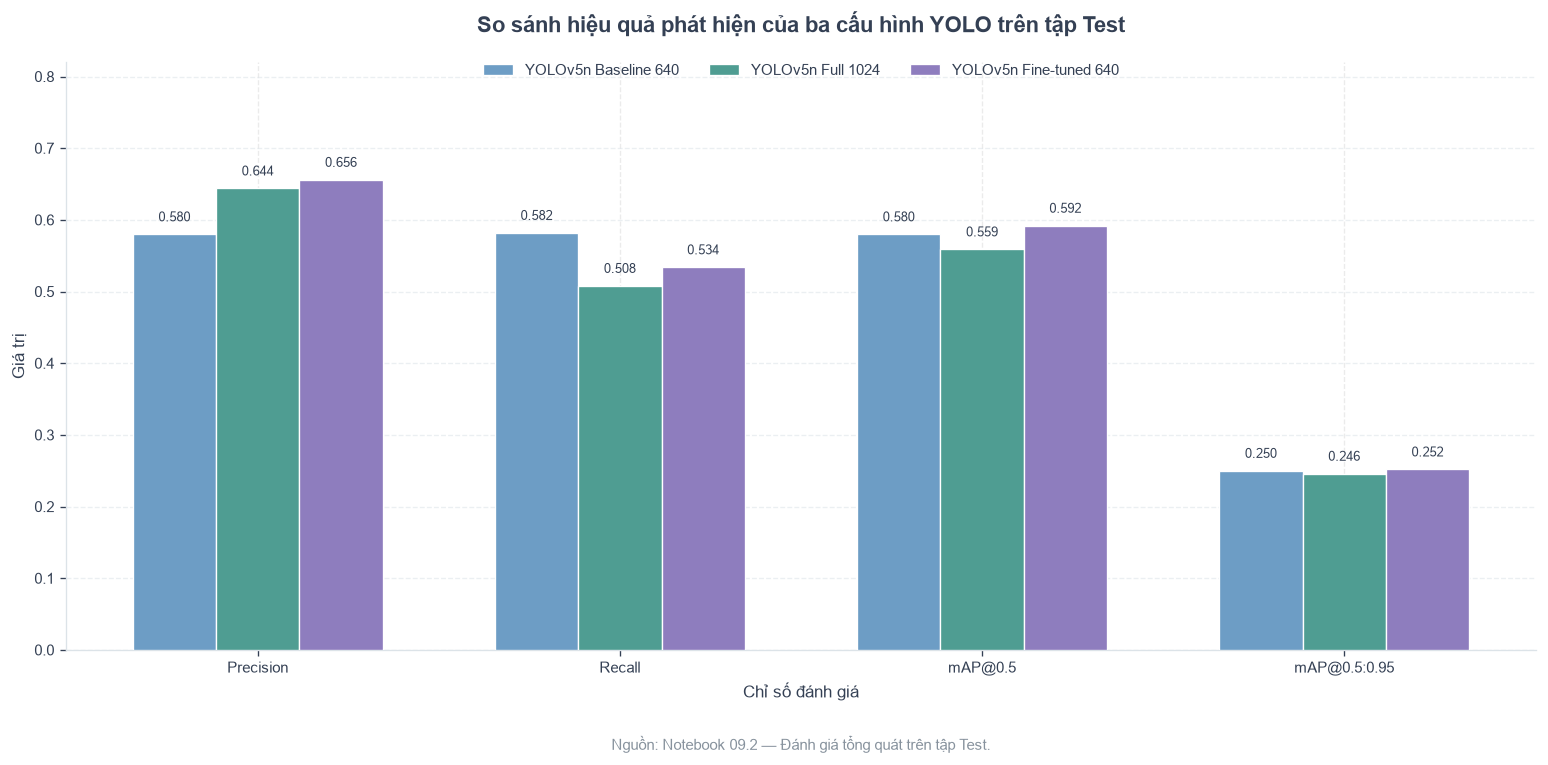

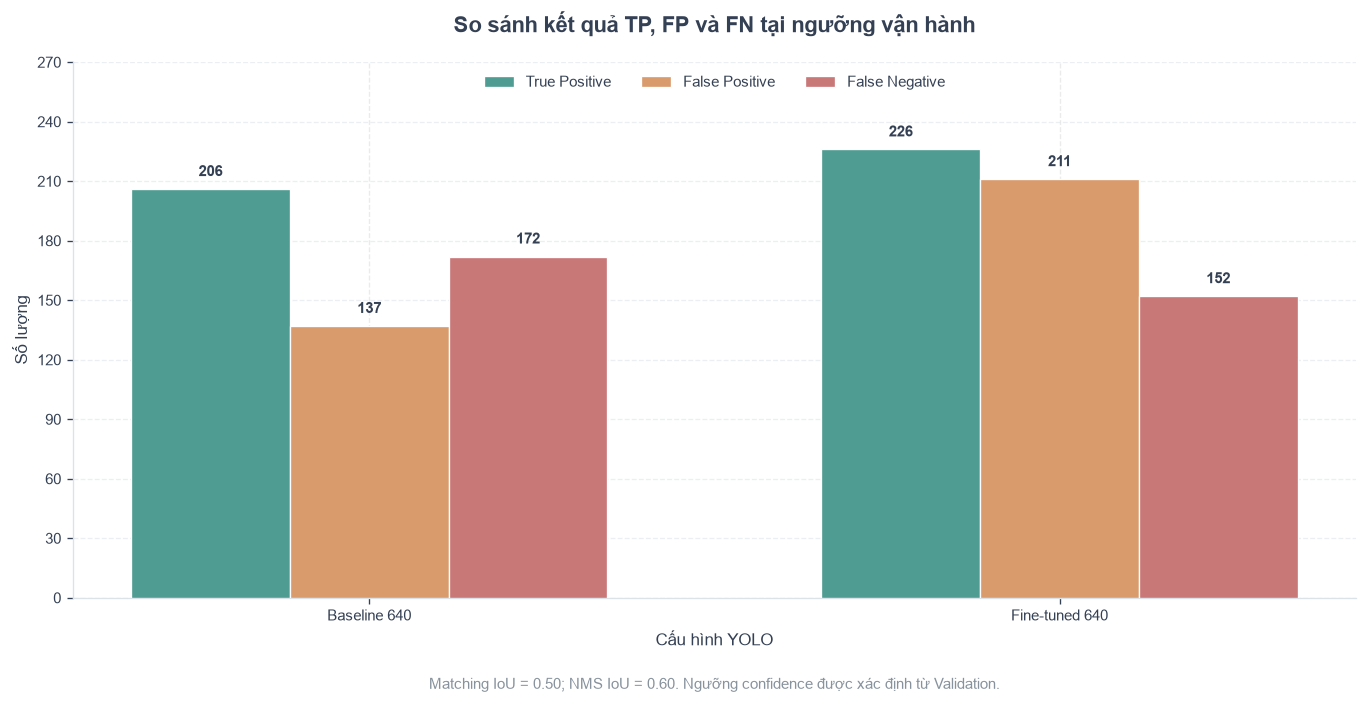

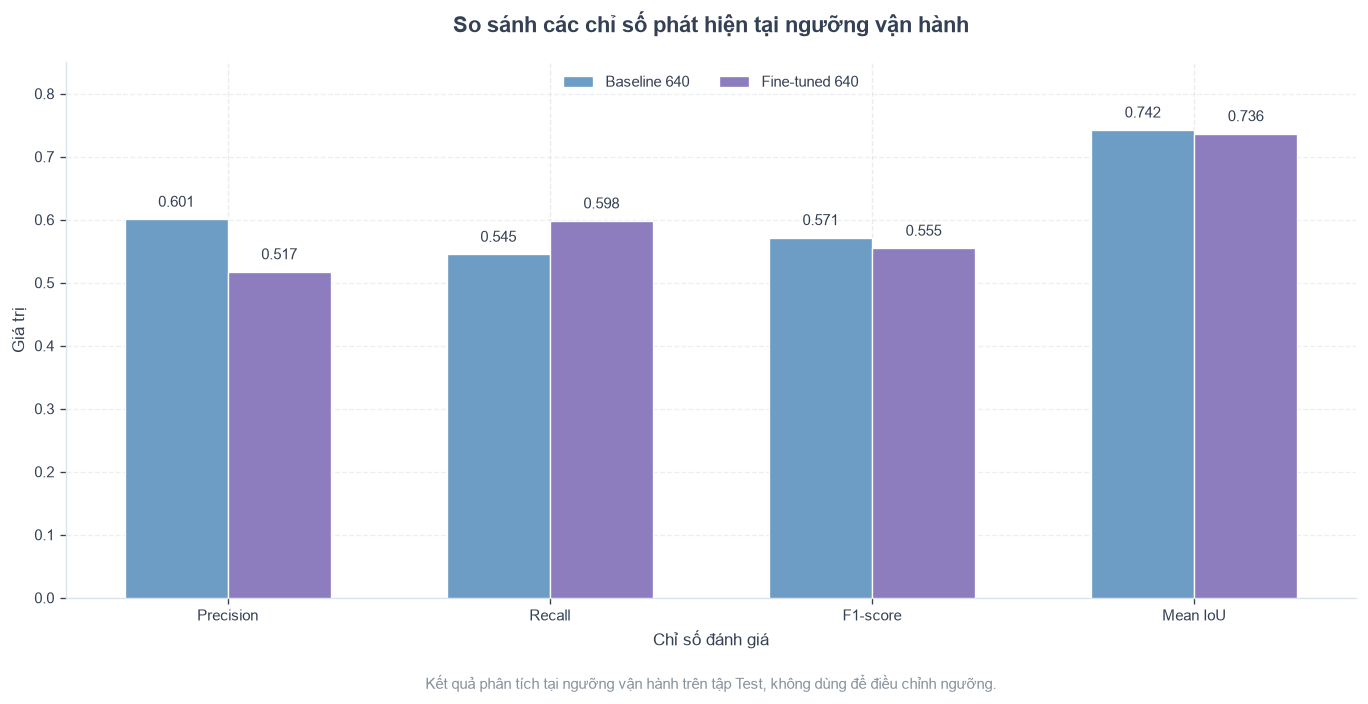

10.5 — SO SÁNH HIỆU QUẢ PHÁT HIỆN YOLO

1. ĐÁNH GIÁ TỔNG QUÁT TRÊN TEST — NOTEBOOK 09.2


,Model,Configuration,Images,Annotations,Precision,Recall,mAP50,mAP50_95
0,YOLOv5n Baseline 640,Full Image 640×640,361,378,0.580,0.582,0.580,0.250
1,YOLOv5n Full 1024,Full Image 1024×1024,361,378,0.644,0.508,0.559,0.246
2,YOLOv5n Fine-tuned 640,Fine-tuned 640×640,361,378,0.656,0.534,0.592,0.252



2. ĐÁNH GIÁ TẠI NGƯỠNG VẬN HÀNH — NOTEBOOK 09.4


,Model,Confidence,NMS_IoU,Matching_IoU,Predictions,TP,FP,FN,Precision,Recall,F1_Score,Mean_IoU
0,YOLOv5n Baseline 640,0.25,0.6,0.5,343,206,137,172,0.6006,0.5450,0.5714,0.7422
1,YOLOv5n Fine-tuned 640,0.20,0.6,0.5,437,226,211,152,0.5172,0.5979,0.5546,0.7363



3. CHÊNH LỆCH FINE-TUNED SO VỚI BASELINE


,Metric,Baseline_640,Fine_tuned_640,Difference,Interpretation
0,TP,206.0000,226.0000,20.0000,Số phát hiện đúng
1,FP,137.0000,211.0000,74.0000,Số phát hiện sai
2,FN,172.0000,152.0000,-20.0000,Số tổn thương bỏ sót
3,Precision,0.6006,0.5172,-0.0834,Độ chính xác của dự đoán dương tính
4,Recall,0.5450,0.5979,0.0529,Khả năng phát hiện tổn thương
5,F1_Score,0.5714,0.5546,-0.0168,Trung bình điều hòa Precision và Recall
6,Mean_IoU,0.7422,0.7363,-0.0059,IoU trung bình của các trường hợp khớp



4. KIỂM TRA TÍNH TOÀN VẸN
Dữ liệu: Có đủ 3 cấu hình YOLO trên Test                              : PASS
Dữ liệu: Cùng số ảnh Test                                             : PASS
Dữ liệu: Cùng số annotations Test                                     : PASS
Dữ liệu: Các chỉ số đánh giá tổng quát hợp lệ                         : PASS
Dữ liệu: Có đủ 2 cấu hình tại ngưỡng vận hành                         : PASS
Dữ liệu: Số Predictions nhất quán với TP + FP                         : PASS
Dữ liệu: Số TP + FN nhất quán với annotations                         : PASS
Dữ liệu: Các chỉ số vận hành nằm trong khoảng 0–1                     : PASS
Biểu đồ: nb10_5_figure_01_yolo_test_metrics.png                       : PASS
Biểu đồ: nb10_5_figure_02_yolo_operating_counts.png                   : PASS
Biểu đồ: nb10_5_figure_03_yolo_operating_metrics.png                  : PASS
Bảng: nb10_5_yolo_test_comparison.csv                                 : PASS
Bảng: nb10_5_yolo_operating_point_comparison.csv 

In [9]:
# 10.5 — SO SÁNH HIỆU QUẢ PHÁT HIỆN YOLO

# ============================================================
# 1. KIỂM TRA MÔI TRƯỜNG VÀ CẤU HÌNH
# ============================================================

required_variables = [
    "FIGURES_DIR",
    "TABLES_DIR",
    "REPORTS_DIR",
    "NB10_4_PASS"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Thiếu cấu hình từ các mục trước: "
        + ", ".join(missing_variables)
    )

if not NB10_4_PASS:
    raise RuntimeError(
        "Notebook 10.4 chưa PASS. Không thể tiếp tục 10.5."
    )

FIGURES_DIR = Path(FIGURES_DIR)
TABLES_DIR = Path(TABLES_DIR)
REPORTS_DIR = Path(REPORTS_DIR)

for directory in [FIGURES_DIR, TABLES_DIR, REPORTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


# Bảng màu thống nhất với Notebook 10.4
COLORS = {
    "navy": "#355070",
    "blue": "#6D9DC5",
    "teal": "#4F9D92",
    "green": "#83B692",
    "purple": "#8E7DBE",
    "orange": "#D99A6C",
    "red": "#C97878",
    "gray": "#87929D",
    "light": "#EAF0F4",
    "text": "#344054",
    "grid": "#DCE3E8"
}

YOLO_COLORS = {
    "YOLOv5n Baseline 640": COLORS["blue"],
    "YOLOv5n Full 1024": COLORS["teal"],
    "YOLOv5n Fine-tuned 640": COLORS["purple"]
}

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.labelcolor": COLORS["text"],
    "xtick.color": COLORS["text"],
    "ytick.color": COLORS["text"],
    "text.color": COLORS["text"],
    "axes.edgecolor": COLORS["grid"],
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white"
})


# ============================================================
# 2. KẾT QUẢ ĐÁNH GIÁ TỔNG QUÁT YOLO TRÊN TEST
#    Nguồn: Notebook 09.2
# ============================================================

yolo_test_records = [
    {
        "Model": "YOLOv5n Baseline 640",
        "Configuration": "Full Image 640×640",
        "Images": 361,
        "Annotations": 378,
        "Precision": 0.5800,
        "Recall": 0.5820,
        "mAP50": 0.5800,
        "mAP50_95": 0.2500
    },
    {
        "Model": "YOLOv5n Full 1024",
        "Configuration": "Full Image 1024×1024",
        "Images": 361,
        "Annotations": 378,
        "Precision": 0.6440,
        "Recall": 0.5080,
        "mAP50": 0.5590,
        "mAP50_95": 0.2460
    },
    {
        "Model": "YOLOv5n Fine-tuned 640",
        "Configuration": "Fine-tuned 640×640",
        "Images": 361,
        "Annotations": 378,
        "Precision": 0.6560,
        "Recall": 0.5340,
        "mAP50": 0.5920,
        "mAP50_95": 0.2520
    }
]

yolo_test_df = pd.DataFrame(yolo_test_records)


# ============================================================
# 3. KẾT QUẢ PHÂN TÍCH TẠI NGƯỠNG VẬN HÀNH
#    Nguồn: Notebook 09.4
#
#    Baseline 640: Confidence 0.25, NMS IoU 0.60
#    Fine-tuned 640: Confidence 0.20, NMS IoU 0.60
#
#    Full 1024 không có ngưỡng vận hành được khóa
#    từ Validation nên không đưa vào bảng này.
# ============================================================

operating_records = [
    {
        "Model": "YOLOv5n Baseline 640",
        "Confidence": 0.25,
        "NMS_IoU": 0.60,
        "Matching_IoU": 0.50,
        "Predictions": 343,
        "TP": 206,
        "FP": 137,
        "FN": 172,
        "Precision": 0.6006,
        "Recall": 0.5450,
        "F1_Score": 0.5714,
        "Mean_IoU": 0.7422
    },
    {
        "Model": "YOLOv5n Fine-tuned 640",
        "Confidence": 0.20,
        "NMS_IoU": 0.60,
        "Matching_IoU": 0.50,
        "Predictions": 437,
        "TP": 226,
        "FP": 211,
        "FN": 152,
        "Precision": 0.5172,
        "Recall": 0.5979,
        "F1_Score": 0.5546,
        "Mean_IoU": 0.7363
    }
]

operating_df = pd.DataFrame(operating_records)


# ============================================================
# 4. KIỂM TRA TÍNH HỢP LỆ CỦA SỐ LIỆU
# ============================================================

DATA_CHECKS = {
    "Có đủ 3 cấu hình YOLO trên Test": (
        len(yolo_test_df) == 3
    ),
    "Cùng số ảnh Test": (
        yolo_test_df["Images"].nunique() == 1
        and yolo_test_df["Images"].iloc[0] == 361
    ),
    "Cùng số annotations Test": (
        yolo_test_df["Annotations"].nunique() == 1
        and yolo_test_df["Annotations"].iloc[0] == 378
    ),
    "Các chỉ số đánh giá tổng quát hợp lệ": (
        yolo_test_df[
            ["Precision", "Recall", "mAP50", "mAP50_95"]
        ].apply(
            lambda column: column.between(0, 1).all()
        ).all()
    ),
    "Có đủ 2 cấu hình tại ngưỡng vận hành": (
        len(operating_df) == 2
    ),
    "Số Predictions nhất quán với TP + FP": (
        (
            operating_df["Predictions"]
            == operating_df["TP"] + operating_df["FP"]
        ).all()
    ),
    "Số TP + FN nhất quán với annotations": (
        (
            operating_df["TP"] + operating_df["FN"]
            == 378
        ).all()
    ),
    "Các chỉ số vận hành nằm trong khoảng 0–1": (
        operating_df[
            [
                "Precision",
                "Recall",
                "F1_Score",
                "Mean_IoU"
            ]
        ].apply(
            lambda column: column.between(0, 1).all()
        ).all()
    )
}

DATA_CHECKS = {
    key: bool(value)
    for key, value in DATA_CHECKS.items()
}

if not all(DATA_CHECKS.values()):
    raise ValueError(
        "Dữ liệu đầu vào không vượt qua kiểm tra. "
        "Không tiếp tục tạo biểu đồ."
    )


# ============================================================
# 5. BIỂU ĐỒ 1 — SO SÁNH PRECISION, RECALL VÀ mAP
# ============================================================

metrics = [
    "Precision",
    "Recall",
    "mAP50",
    "mAP50_95"
]

metric_labels = [
    "Precision",
    "Recall",
    "mAP@0.5",
    "mAP@0.5:0.95"
]

fig, ax = plt.subplots(figsize=(13, 6.5))

x = np.arange(len(metrics))
width = 0.23

for index, row in yolo_test_df.iterrows():

    model_name = row["Model"]

    values = [
        row[metric]
        for metric in metrics
    ]

    bars = ax.bar(
        x + (index - 1) * width,
        values,
        width,
        label=model_name,
        color=YOLO_COLORS[model_name],
        edgecolor="white",
        linewidth=0.8,
        zorder=3
    )

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.014,
            f"{bar.get_height():.3f}",
            ha="center",
            va="bottom",
            fontsize=8
        )

ax.set_title(
    "So sánh hiệu quả phát hiện của ba cấu hình YOLO trên tập Test",
    pad=18
)

ax.set_xlabel("Chỉ số đánh giá")
ax.set_ylabel("Giá trị")

ax.set_xticks(x)
ax.set_xticklabels(metric_labels)

ax.set_ylim(0, 0.82)
ax.set_yticks(np.arange(0, 0.81, 0.1))

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.55,
    color=COLORS["grid"],
    zorder=0
)

ax.legend(
    frameon=False,
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 1.02)
)

ax.text(
    0.5,
    -0.17,
    "Nguồn: Notebook 09.2 — Đánh giá tổng quát trên tập Test.",
    transform=ax.transAxes,
    ha="center",
    fontsize=9,
    color=COLORS["gray"]
)

fig.tight_layout()

figure_01_path = (
    FIGURES_DIR /
    "nb10_5_figure_01_yolo_test_metrics.png"
)

fig.savefig(
    figure_01_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 6. BIỂU ĐỒ 2 — SO SÁNH TP, FP VÀ FN
# ============================================================

fig, ax = plt.subplots(figsize=(11.5, 6))

x = np.arange(len(operating_df))
width = 0.23

count_metrics = [
    ("TP", COLORS["teal"], "True Positive"),
    ("FP", COLORS["orange"], "False Positive"),
    ("FN", COLORS["red"], "False Negative")
]

for index, (column, color, label) in enumerate(count_metrics):

    bars = ax.bar(
        x + (index - 1) * width,
        operating_df[column],
        width,
        label=label,
        color=color,
        edgecolor="white",
        linewidth=0.8,
        zorder=3
    )

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 5,
            f"{int(bar.get_height())}",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )

ax.set_title(
    "So sánh kết quả TP, FP và FN tại ngưỡng vận hành",
    pad=18
)

ax.set_xlabel("Cấu hình YOLO")
ax.set_ylabel("Số lượng")

ax.set_xticks(x)
ax.set_xticklabels([
    "Baseline 640",
    "Fine-tuned 640"
])

ax.set_ylim(0, 270)
ax.set_yticks(np.arange(0, 271, 30))

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.55,
    color=COLORS["grid"],
    zorder=0
)

ax.legend(
    frameon=False,
    ncol=3,
    loc="upper center"
)

ax.text(
    0.5,
    -0.17,
    "Matching IoU = 0.50; NMS IoU = 0.60. "
    "Ngưỡng confidence được xác định từ Validation.",
    transform=ax.transAxes,
    ha="center",
    fontsize=9,
    color=COLORS["gray"]
)

fig.tight_layout()

figure_02_path = (
    FIGURES_DIR /
    "nb10_5_figure_02_yolo_operating_counts.png"
)

fig.savefig(
    figure_02_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 7. BIỂU ĐỒ 3 — SO SÁNH CÁC CHỈ SỐ TẠI NGƯỠNG VẬN HÀNH
# ============================================================

operating_metrics = [
    "Precision",
    "Recall",
    "F1_Score",
    "Mean_IoU"
]

operating_labels = [
    "Precision",
    "Recall",
    "F1-score",
    "Mean IoU"
]

fig, ax = plt.subplots(figsize=(11.5, 6))

x = np.arange(len(operating_metrics))
width = 0.32

for index, row in operating_df.iterrows():

    model_name = row["Model"]

    values = [
        row[metric]
        for metric in operating_metrics
    ]

    color = (
        COLORS["blue"]
        if index == 0
        else COLORS["purple"]
    )

    bars = ax.bar(
        x + (index - 0.5) * width,
        values,
        width,
        label=(
            "Baseline 640"
            if index == 0
            else "Fine-tuned 640"
        ),
        color=color,
        edgecolor="white",
        linewidth=0.8,
        zorder=3
    )

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.015,
            f"{bar.get_height():.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

ax.set_title(
    "So sánh các chỉ số phát hiện tại ngưỡng vận hành",
    pad=18
)

ax.set_xlabel("Chỉ số đánh giá")
ax.set_ylabel("Giá trị")

ax.set_xticks(x)
ax.set_xticklabels(operating_labels)

ax.set_ylim(0, 0.85)
ax.set_yticks(np.arange(0, 0.81, 0.1))

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.55,
    color=COLORS["grid"],
    zorder=0
)

ax.legend(
    frameon=False,
    ncol=2,
    loc="upper center"
)

ax.text(
    0.5,
    -0.17,
    "Kết quả phân tích tại ngưỡng vận hành trên tập Test, "
    "không dùng để điều chỉnh ngưỡng.",
    transform=ax.transAxes,
    ha="center",
    fontsize=9,
    color=COLORS["gray"]
)

fig.tight_layout()

figure_03_path = (
    FIGURES_DIR /
    "nb10_5_figure_03_yolo_operating_metrics.png"
)

fig.savefig(
    figure_03_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 8. TẠO BẢNG SO SÁNH VÀ TÓM TẮT CHÊNH LỆCH
# ============================================================

# Bảng đánh giá tổng quát
test_comparison_df = yolo_test_df.copy()

# Bảng đánh giá tại ngưỡng vận hành
operating_comparison_df = operating_df.copy()

# Chênh lệch Fine-tuned so với Baseline
baseline_row = operating_df[
    operating_df["Model"] == "YOLOv5n Baseline 640"
].iloc[0]

finetuned_row = operating_df[
    operating_df["Model"] == "YOLOv5n Fine-tuned 640"
].iloc[0]

difference_records = [
    {
        "Metric": "TP",
        "Baseline_640": int(baseline_row["TP"]),
        "Fine_tuned_640": int(finetuned_row["TP"]),
        "Difference": int(
            finetuned_row["TP"] - baseline_row["TP"]
        ),
        "Interpretation": "Số phát hiện đúng"
    },
    {
        "Metric": "FP",
        "Baseline_640": int(baseline_row["FP"]),
        "Fine_tuned_640": int(finetuned_row["FP"]),
        "Difference": int(
            finetuned_row["FP"] - baseline_row["FP"]
        ),
        "Interpretation": "Số phát hiện sai"
    },
    {
        "Metric": "FN",
        "Baseline_640": int(baseline_row["FN"]),
        "Fine_tuned_640": int(finetuned_row["FN"]),
        "Difference": int(
            finetuned_row["FN"] - baseline_row["FN"]
        ),
        "Interpretation": "Số tổn thương bỏ sót"
    },
    {
        "Metric": "Precision",
        "Baseline_640": float(baseline_row["Precision"]),
        "Fine_tuned_640": float(finetuned_row["Precision"]),
        "Difference": float(
            finetuned_row["Precision"]
            - baseline_row["Precision"]
        ),
        "Interpretation": "Độ chính xác của dự đoán dương tính"
    },
    {
        "Metric": "Recall",
        "Baseline_640": float(baseline_row["Recall"]),
        "Fine_tuned_640": float(finetuned_row["Recall"]),
        "Difference": float(
            finetuned_row["Recall"]
            - baseline_row["Recall"]
        ),
        "Interpretation": "Khả năng phát hiện tổn thương"
    },
    {
        "Metric": "F1_Score",
        "Baseline_640": float(baseline_row["F1_Score"]),
        "Fine_tuned_640": float(finetuned_row["F1_Score"]),
        "Difference": float(
            finetuned_row["F1_Score"]
            - baseline_row["F1_Score"]
        ),
        "Interpretation": "Trung bình điều hòa Precision và Recall"
    },
    {
        "Metric": "Mean_IoU",
        "Baseline_640": float(baseline_row["Mean_IoU"]),
        "Fine_tuned_640": float(finetuned_row["Mean_IoU"]),
        "Difference": float(
            finetuned_row["Mean_IoU"]
            - baseline_row["Mean_IoU"]
        ),
        "Interpretation": "IoU trung bình của các trường hợp khớp"
    }
]

difference_df = pd.DataFrame(difference_records)


# ============================================================
# 9. XUẤT BẢNG CSV
# ============================================================

tables_to_save = {
    "nb10_5_yolo_test_comparison.csv": test_comparison_df,
    "nb10_5_yolo_operating_point_comparison.csv": (
        operating_comparison_df
    ),
    "nb10_5_yolo_baseline_finetuned_difference.csv": (
        difference_df
    )
}

saved_table_paths = []

for filename, dataframe in tables_to_save.items():

    output_path = TABLES_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    saved_table_paths.append(output_path)


# ============================================================
# 10. KIỂM TRA TỆP BIỂU ĐỒ VÀ BẢNG
# ============================================================

figure_paths = [
    figure_01_path,
    figure_02_path,
    figure_03_path
]

figure_checks = {
    path.name: bool(
        path.exists() and path.stat().st_size > 0
    )
    for path in figure_paths
}

table_checks = {
    path.name: bool(
        path.exists() and path.stat().st_size > 0
    )
    for path in saved_table_paths
}

NB10_5_CHECKS = {
    **{
        f"Dữ liệu: {name}": bool(status)
        for name, status in DATA_CHECKS.items()
    },
    **{
        f"Biểu đồ: {name}": bool(status)
        for name, status in figure_checks.items()
    },
    **{
        f"Bảng: {name}": bool(status)
        for name, status in table_checks.items()
    }
}

NB10_5_PASS = bool(all(NB10_5_CHECKS.values()))


# ============================================================
# 11. XUẤT BÁO CÁO JSON
# ============================================================

NB10_5_REPORT = {
    "section": "10.5",
    "title": "So sánh hiệu quả phát hiện YOLO",
    "created_at": datetime.now().isoformat(timespec="seconds"),

    "test_evaluation": {
        "source": "Notebook 09.2",
        "images": 361,
        "annotations": 378,
        "models": yolo_test_records
    },

    "operating_point_evaluation": {
        "source": "Notebook 09.4",
        "matching_iou": 0.50,
        "nms_iou": 0.60,
        "models": operating_records,
        "note": (
            "Chỉ so sánh Baseline 640 và Fine-tuned 640. "
            "Full 1024 không có ngưỡng vận hành được khóa "
            "từ Validation."
        )
    },

    "baseline_vs_finetuned_difference": (
        difference_records
    ),

    "figures": [
        str(path) for path in figure_paths
    ],

    "tables": [
        str(path) for path in saved_table_paths
    ],

    "checks": NB10_5_CHECKS,

    "interpretation": [
        (
            "Fine-tuned 640 có Precision và mAP cao nhất "
            "trong ba cấu hình ở kết quả đánh giá tổng quát "
            "trên Test."
        ),
        (
            "Baseline 640 có Recall cao nhất trong ba cấu hình "
            "ở kết quả đánh giá tổng quát trên Test."
        ),
        (
            "Tại ngưỡng vận hành được phân tích, Fine-tuned 640 "
            "tăng TP và Recall, đồng thời tăng FP và giảm Precision "
            "so với Baseline 640."
        ),
        (
            "Mean IoU của hai cấu hình tại ngưỡng vận hành "
            "khá tương đồng."
        )
    ],

    "limitations": [
        (
            "Không có kết quả phân tích TP, FP, FN tại ngưỡng "
            "vận hành cho Full 1024."
        ),
        (
            "Các ngưỡng confidence được xác định từ Validation "
            "và giữ nguyên khi đánh giá Test."
        ),
        (
            "Không điều chỉnh mô hình hoặc ngưỡng dựa trên "
            "kết quả Test."
        )
    ],

    "status": "PASS" if NB10_5_PASS else "FAIL"
}

NB10_5_REPORT_PATH = (
    REPORTS_DIR /
    "nb10_5_yolo_detection_comparison_report.json"
)

with open(
    NB10_5_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        NB10_5_REPORT,
        file,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )


# ============================================================
# 12. ĐỌC LẠI VÀ KIỂM TRA BÁO CÁO JSON
# ============================================================

with open(
    NB10_5_REPORT_PATH,
    "r",
    encoding="utf-8"
) as file:

    loaded_report = json.load(file)

json_check = bool(
    isinstance(loaded_report, dict)
    and loaded_report.get("section") == "10.5"
    and len(loaded_report.get("figures", [])) == 3
    and len(loaded_report.get("tables", [])) == 3
)

NB10_5_CHECKS["Báo cáo JSON đọc lại thành công"] = json_check

NB10_5_PASS = bool(all(NB10_5_CHECKS.values()))

loaded_report["checks"] = NB10_5_CHECKS
loaded_report["status"] = (
    "PASS" if NB10_5_PASS else "FAIL"
)

with open(
    NB10_5_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        loaded_report,
        file,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )


# ============================================================
# 13. HIỂN THỊ KẾT QUẢ
# ============================================================

print(
    "10.5 — SO SÁNH HIỆU QUẢ PHÁT HIỆN YOLO"
)

print("\n1. ĐÁNH GIÁ TỔNG QUÁT TRÊN TEST — NOTEBOOK 09.2")
display(test_comparison_df)

print(
    "\n2. ĐÁNH GIÁ TẠI NGƯỠNG VẬN HÀNH — NOTEBOOK 09.4"
)
display(operating_comparison_df)

print(
    "\n3. CHÊNH LỆCH FINE-TUNED SO VỚI BASELINE"
)
display(difference_df)

print("\n4. KIỂM TRA TÍNH TOÀN VẸN")

for check_name, check_status in NB10_5_CHECKS.items():

    print(
        f"{check_name:<70}: "
        f"{'PASS' if check_status else 'FAIL'}"
    )

print("\n5. TỆP ĐẦU RA")

for path in figure_paths:
    print(f"Biểu đồ: {path}")

for path in saved_table_paths:
    print(f"Bảng: {path}")

print(f"Báo cáo: {NB10_5_REPORT_PATH}")

print("\n6. NHẬN XÉT KẾT QUẢ")

print(
    "- Fine-tuned 640 có Precision = 0.6560 "
    "và mAP@0.5 = 0.5920 trên Test."
)

print(
    "- Baseline 640 có Recall = 0.5820, "
    "cao nhất trong ba cấu hình."
)

print(
    "- Tại ngưỡng vận hành, Fine-tuned 640 tăng "
    f"{int(finetuned_row['TP'] - baseline_row['TP'])} TP "
    "và giảm "
    f"{int(baseline_row['FN'] - finetuned_row['FN'])} FN, "
    "nhưng tăng "
    f"{int(finetuned_row['FP'] - baseline_row['FP'])} FP."
)

print(
    "- F1-score tại ngưỡng vận hành giảm từ "
    f"{baseline_row['F1_Score']:.4f} xuống "
    f"{finetuned_row['F1_Score']:.4f}."
)

print("\nKẾT LUẬN 10.5")
print(f"Số biểu đồ đã tạo: {len(figure_paths)}")
print(f"Số bảng đã xuất  : {len(saved_table_paths)}")
print(f"JSON kiểm tra    : {'PASS' if json_check else 'FAIL'}")
print(f"Trạng thái       : {'PASS' if NB10_5_PASS else 'FAIL'}")

if not NB10_5_PASS:
    raise RuntimeError(
        "10.5 chưa hoàn thành. Vui lòng kiểm tra các mục FAIL."
    )


### Thảo luận & Đánh giá hiệu quả tinh chỉnh (Fine-tuning) ở Giai đoạn 1

Khi đối chiếu hiệu năng giữa mô hình gốc (**YOLOv5n Baseline 640**) và mô hình tinh chỉnh (**YOLOv5n Fine-tuned 640**) trên tập Test, cần phân tách rõ kết quả theo hai góc độ đánh giá:

| Góc độ đánh giá | Chỉ số trọng tâm | Baseline 640 | Fine-tuned 640 | Biến động & Ý nghĩa thực nghiệm |
| :--- | :--- | :---: | :---: | :--- |
| **1. Đánh giá tổng quát**<br>*(Đa ngưỡng tự tin)* | `Precision` | 0,580 | **0,656** | **+0,076** — Fine-tuned đạt độ chính xác cao nhất |
| | `Recall` | **0,582** | 0,534 | **-0,048** — Baseline giữ độ nhạy tổng quát cao nhất |
| | `mAP@0.5` | 0,580 | **0,592** | **+0,012** — Fine-tuned dẫn đầu về khả năng phát hiện |
| **2. Ngưỡng vận hành**<br>*(Khóa từ Validation)* | `TP` *(Phát hiện đúng)* | 206 | **226** | **+20 ca** — Mở rộng khả năng bao phủ tổn thương |
| | `FN` *(Bỏ sót)* | 172 | **152** | **-20 ca** — Giảm số lượng tổn thương bị bỏ lọt |
| | `FP` *(Báo động giả)* | **137** | 211 | **+74 ca** — Phát sinh thêm nhiều vùng nghi ngờ giả |
| | `F1-score` | **0,5714** | 0,5546 | **-0,0168** — Cân bằng tổng thể giảm nhẹ do tăng FP |
| | `Mean IoU` *(trên TP)* | **0,7422** | 0,7363 | **-0,0059** — Chất lượng định vị khung gần tương đương |

> **Tiểu kết trọng tâm:** 
> * **Trên phương diện tổng quát**, `YOLOv5n Fine-tuned 640` đạt `Precision` (**0,656**) và `mAP@0.5` (**0,592**) cao nhất, trong khi `Baseline 640` đạt `Recall` (**0,582**) cao nhất.
> * **Tại ngưỡng vận hành thực tế**, `Fine-tuned 640` phát hiện đúng thêm **20 tổn thương** (giảm 20 `FN`) nhưng phải đánh đổi bằng sự gia tăng của **74 trường hợp dương tính giả** (`FP`), kéo `F1-score` giảm từ **0,5714** xuống **0,5546**, trong khi độ khít khung định vị (`Mean IoU`) giữ mức tương đương (**0,7422** so với **0,7363**).
> * **Kết luận:** Quá trình Fine-tuning giúp gia tăng số lượng tổn thương được phát hiện tại ngưỡng đã chọn, nhưng **chưa cải thiện đồng thời tất cả các chỉ số** mà tạo ra sự đánh đổi rõ rệt giữa độ bao phủ và tỷ lệ báo động giả.

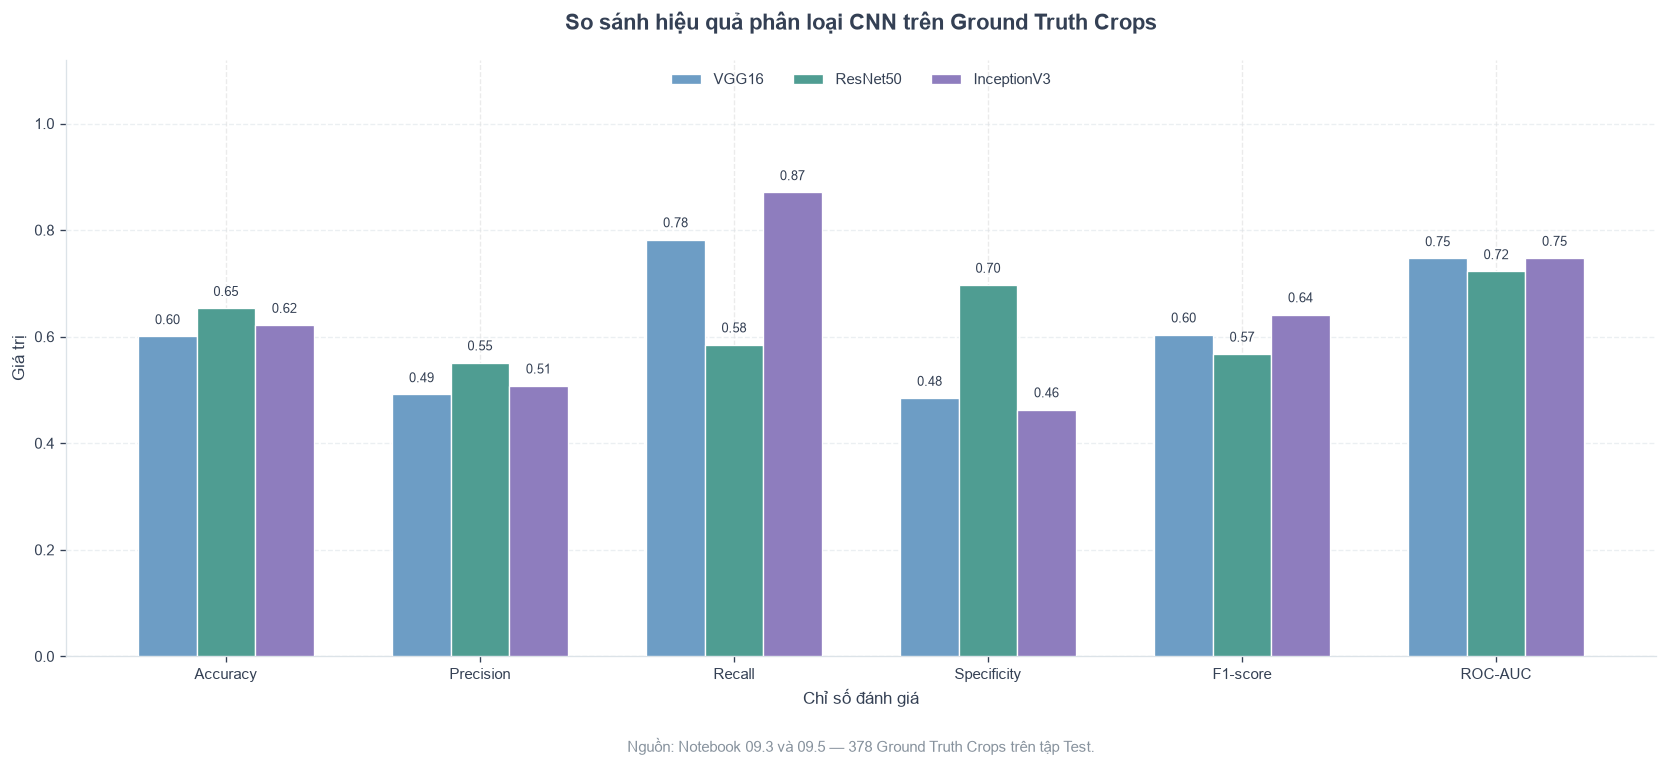

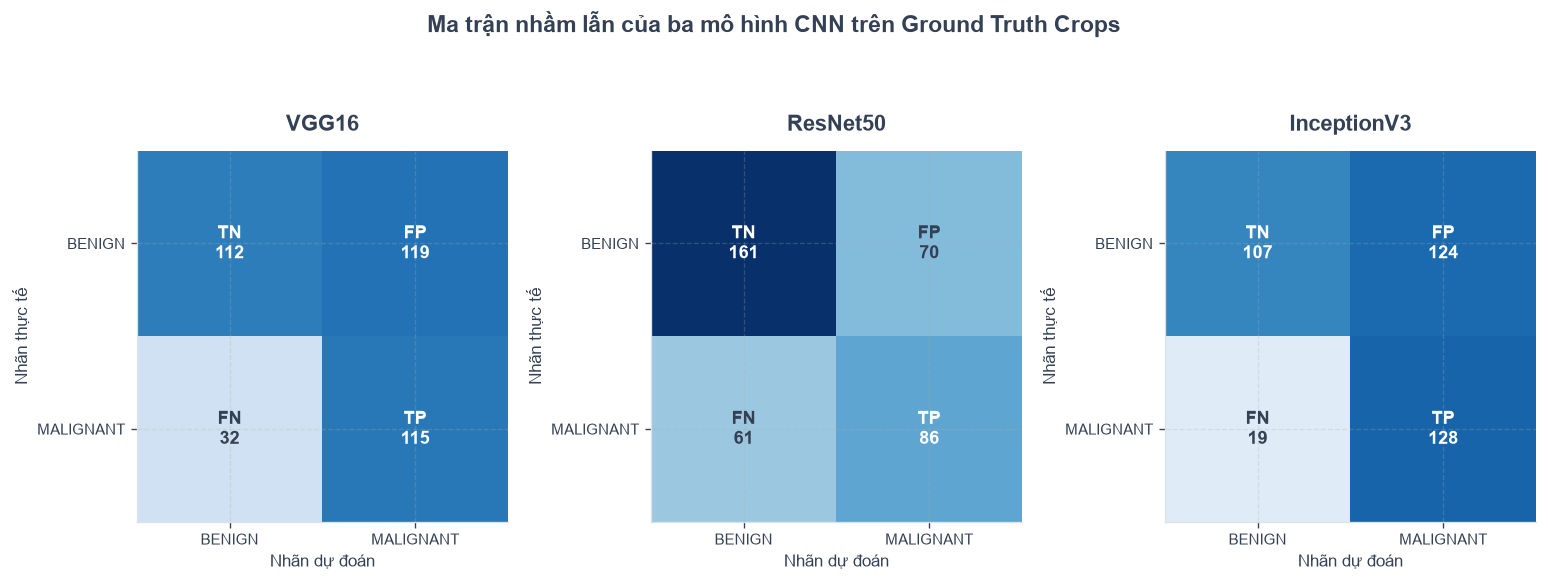

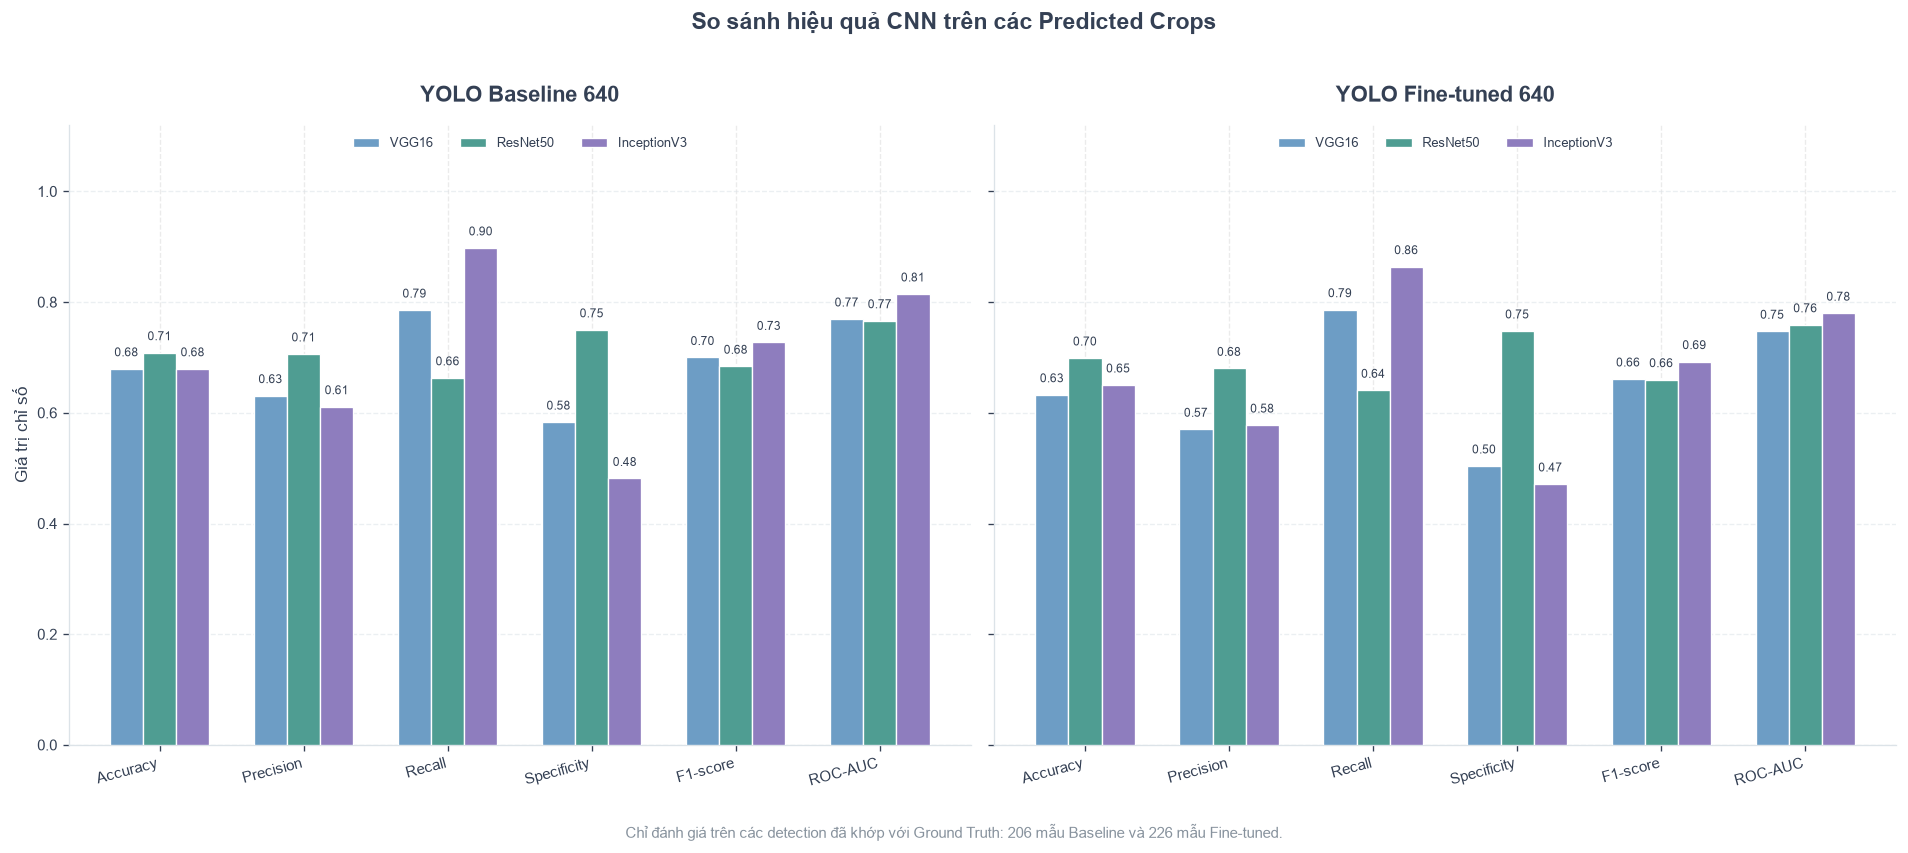

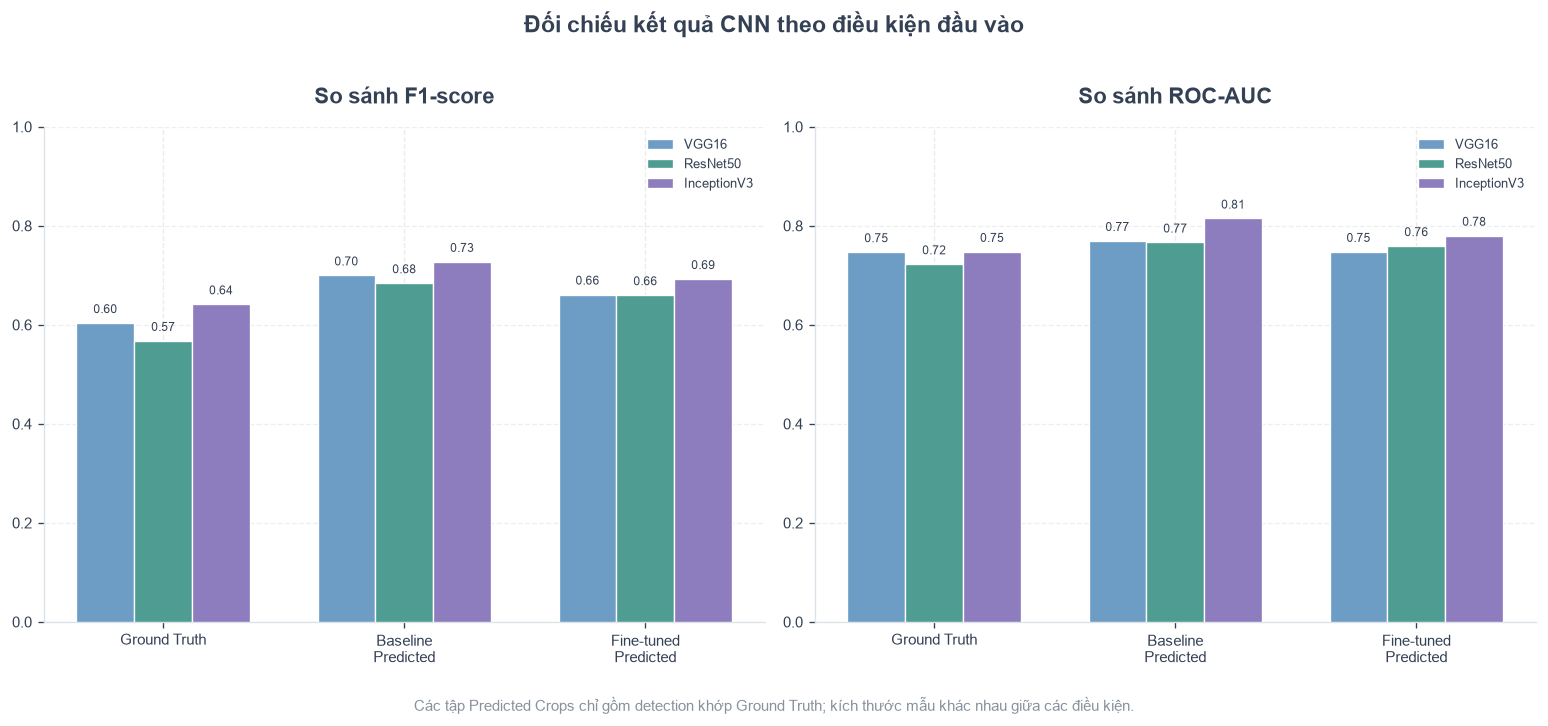

10.6 — SO SÁNH HIỆU QUẢ PHÂN LOẠI CNN

1. KẾT QUẢ TRÊN GROUND TRUTH CROPS


,Model,Samples,Patients,Threshold,Accuracy,Precision,Recall,Specificity,F1_Score,ROC_AUC,TN,FP,FN,TP
0,VGG16,378,201,0.3,0.6005,0.4915,0.7823,0.4848,0.6037,0.7469,112,119,32,115
1,ResNet50,378,201,0.5,0.6534,0.5513,0.5850,0.6970,0.5677,0.7225,161,70,61,86
2,InceptionV3,378,201,0.3,0.6217,0.5079,0.8707,0.4632,0.6416,0.7475,107,124,19,128



2. KẾT QUẢ TRÊN PREDICTED CROPS


,YOLO,CNN,Samples,Accuracy,Precision,Recall,Specificity,F1_Score,ROC_AUC,TN,FP,FN,TP
0,Baseline 640,VGG16,206,0.6796,0.6311,0.7857,0.5833,0.7000,0.7696,63,45,21,77
1,Baseline 640,ResNet50,206,0.7087,0.7065,0.6633,0.7500,0.6842,0.7664,81,27,33,65
2,Baseline 640,InceptionV3,206,0.6796,0.6111,0.8980,0.4815,0.7273,0.8148,52,56,10,88
3,Fine-tuned 640,VGG16,226,0.6327,0.5704,0.7864,0.5041,0.6612,0.7475,62,61,22,81
4,Fine-tuned 640,ResNet50,226,0.6991,0.6804,0.6408,0.7480,0.6600,0.7591,92,31,37,66
5,Fine-tuned 640,InceptionV3,226,0.6504,0.5779,0.8641,0.4715,0.6926,0.7801,58,65,14,89



3. MÔ HÌNH DẪN ĐẦU THEO TỪNG CHỈ SỐ


,Evaluation_Set,Metric,Best_Model,Best_Value
0,Ground Truth Crops,Accuracy,ResNet50,0.6534
1,Ground Truth Crops,Precision,ResNet50,0.5513
2,Ground Truth Crops,Recall,InceptionV3,0.8707
3,Ground Truth Crops,Specificity,ResNet50,0.6970
4,Ground Truth Crops,F1_Score,InceptionV3,0.6416
5,Ground Truth Crops,ROC_AUC,InceptionV3,0.7475
6,Predicted Crops - Baseline 640,Accuracy,ResNet50,0.7087
7,Predicted Crops - Baseline 640,Precision,ResNet50,0.7065
8,Predicted Crops - Baseline 640,Recall,InceptionV3,0.8980
9,Predicted Crops - Baseline 640,Specificity,ResNet50,0.7500



4. KIỂM TRA TÍNH TOÀN VẸN
Ground Truth: Có đủ 3 mô hình CNN trên Ground Truth Crops                  : PASS
Ground Truth: Mỗi mô hình đánh giá trên 378 mẫu                            : PASS
Ground Truth: Có đủ 201 bệnh nhân                                          : PASS
Ground Truth: Tổng confusion matrix bằng số mẫu                            : PASS
Ground Truth: Các chỉ số nằm trong khoảng 0–1                              : PASS
Predicted Crops: Có đủ 6 tổ hợp YOLO và CNN                                : PASS
Predicted Crops: Có đủ 3 CNN cho mỗi cấu hình YOLO                         : PASS
Predicted Crops: Baseline có 206 mẫu cho mỗi CNN                           : PASS
Predicted Crops: Fine-tuned có 226 mẫu cho mỗi CNN                         : PASS
Predicted Crops: Confusion matrix khớp số mẫu                              : PASS
Predicted Crops: Các chỉ số nằm trong khoảng 0–1                           : PASS
Biểu đồ: nb10_6_figure_01_cnn_ground_truth_comparison.png              

In [10]:
# 10.6 — SO SÁNH HIỆU QUẢ PHÂN LOẠI CNN

# ============================================================
# 1. KIỂM TRA MÔI TRƯỜNG VÀ CẤU HÌNH
# ============================================================

required_variables = [
    "FIGURES_DIR",
    "TABLES_DIR",
    "REPORTS_DIR",
    "NB10_5_PASS"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Thiếu cấu hình từ các mục trước: "
        + ", ".join(missing_variables)
    )

if not NB10_5_PASS:
    raise RuntimeError(
        "Notebook 10.5 chưa PASS. Không thể tiếp tục 10.6."
    )

FIGURES_DIR = Path(FIGURES_DIR)
TABLES_DIR = Path(TABLES_DIR)
REPORTS_DIR = Path(REPORTS_DIR)

for directory in [FIGURES_DIR, TABLES_DIR, REPORTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


# Bảng màu thống nhất
COLORS = {
    "navy": "#355070",
    "blue": "#6D9DC5",
    "teal": "#4F9D92",
    "green": "#83B692",
    "purple": "#8E7DBE",
    "orange": "#D99A6C",
    "red": "#C97878",
    "gray": "#87929D",
    "light": "#EAF0F4",
    "text": "#344054",
    "grid": "#DCE3E8"
}

CNN_COLORS = {
    "VGG16": COLORS["blue"],
    "ResNet50": COLORS["teal"],
    "InceptionV3": COLORS["purple"]
}

YOLO_COLORS = {
    "Baseline 640": COLORS["blue"],
    "Fine-tuned 640": COLORS["purple"]
}

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.labelcolor": COLORS["text"],
    "xtick.color": COLORS["text"],
    "ytick.color": COLORS["text"],
    "text.color": COLORS["text"],
    "axes.edgecolor": COLORS["grid"],
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white"
})


# ============================================================
# 2. KẾT QUẢ CNN TRÊN GROUND TRUTH CROPS
#    Nguồn: Notebook 09.3 và 09.5
# ============================================================

gt_crop_records = [
    {
        "Model": "VGG16",
        "Samples": 378,
        "Patients": 201,
        "Threshold": 0.30,
        "Accuracy": 0.6005,
        "Precision": 0.4915,
        "Recall": 0.7823,
        "Specificity": 0.4848,
        "F1_Score": 0.6037,
        "ROC_AUC": 0.7469,
        "TN": 112,
        "FP": 119,
        "FN": 32,
        "TP": 115
    },
    {
        "Model": "ResNet50",
        "Samples": 378,
        "Patients": 201,
        "Threshold": 0.50,
        "Accuracy": 0.6534,
        "Precision": 0.5513,
        "Recall": 0.5850,
        "Specificity": 0.6970,
        "F1_Score": 0.5677,
        "ROC_AUC": 0.7225,
        "TN": 161,
        "FP": 70,
        "FN": 61,
        "TP": 86
    },
    {
        "Model": "InceptionV3",
        "Samples": 378,
        "Patients": 201,
        "Threshold": 0.30,
        "Accuracy": 0.6217,
        "Precision": 0.5079,
        "Recall": 0.8707,
        "Specificity": 0.4632,
        "F1_Score": 0.6416,
        "ROC_AUC": 0.7475,
        "TN": 107,
        "FP": 124,
        "FN": 19,
        "TP": 128
    }
]

gt_crop_df = pd.DataFrame(gt_crop_records)


# ============================================================
# 3. KẾT QUẢ CNN TRÊN PREDICTED CROPS
#    Nguồn: Notebook 09.6
#
#    Các chỉ số chỉ được tính trên những detection
#    khớp với Ground Truth theo quy trình Notebook 09.6.
# ============================================================

predicted_crop_records = [
    {
        "YOLO": "Baseline 640",
        "CNN": "VGG16",
        "Samples": 206,
        "Accuracy": 0.6796,
        "Precision": 0.6311,
        "Recall": 0.7857,
        "Specificity": 0.5833,
        "F1_Score": 0.7000,
        "ROC_AUC": 0.7696,
        "TN": 63,
        "FP": 45,
        "FN": 21,
        "TP": 77
    },
    {
        "YOLO": "Baseline 640",
        "CNN": "ResNet50",
        "Samples": 206,
        "Accuracy": 0.7087,
        "Precision": 0.7065,
        "Recall": 0.6633,
        "Specificity": 0.7500,
        "F1_Score": 0.6842,
        "ROC_AUC": 0.7664,
        "TN": 81,
        "FP": 27,
        "FN": 33,
        "TP": 65
    },
    {
        "YOLO": "Baseline 640",
        "CNN": "InceptionV3",
        "Samples": 206,
        "Accuracy": 0.6796,
        "Precision": 0.6111,
        "Recall": 0.8980,
        "Specificity": 0.4815,
        "F1_Score": 0.7273,
        "ROC_AUC": 0.8148,
        "TN": 52,
        "FP": 56,
        "FN": 10,
        "TP": 88
    },
    {
        "YOLO": "Fine-tuned 640",
        "CNN": "VGG16",
        "Samples": 226,
        "Accuracy": 0.6327,
        "Precision": 0.5704,
        "Recall": 0.7864,
        "Specificity": 0.5041,
        "F1_Score": 0.6612,
        "ROC_AUC": 0.7475,
        "TN": 62,
        "FP": 61,
        "FN": 22,
        "TP": 81
    },
    {
        "YOLO": "Fine-tuned 640",
        "CNN": "ResNet50",
        "Samples": 226,
        "Accuracy": 0.6991,
        "Precision": 0.6804,
        "Recall": 0.6408,
        "Specificity": 0.7480,
        "F1_Score": 0.6600,
        "ROC_AUC": 0.7591,
        "TN": 92,
        "FP": 31,
        "FN": 37,
        "TP": 66
    },
    {
        "YOLO": "Fine-tuned 640",
        "CNN": "InceptionV3",
        "Samples": 226,
        "Accuracy": 0.6504,
        "Precision": 0.5779,
        "Recall": 0.8641,
        "Specificity": 0.4715,
        "F1_Score": 0.6926,
        "ROC_AUC": 0.7801,
        "TN": 58,
        "FP": 65,
        "FN": 14,
        "TP": 89
    }
]

predicted_crop_df = pd.DataFrame(predicted_crop_records)


# ============================================================
# 4. KIỂM TRA TÍNH HỢP LỆ CỦA SỐ LIỆU
# ============================================================

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1_Score",
    "ROC_AUC"
]

gt_checks = {
    "Có đủ 3 mô hình CNN trên Ground Truth Crops": (
        len(gt_crop_df) == 3
    ),
    "Mỗi mô hình đánh giá trên 378 mẫu": (
        (gt_crop_df["Samples"] == 378).all()
    ),
    "Có đủ 201 bệnh nhân": (
        (gt_crop_df["Patients"] == 201).all()
    ),
    "Tổng confusion matrix bằng số mẫu": (
        (
            gt_crop_df["TN"]
            + gt_crop_df["FP"]
            + gt_crop_df["FN"]
            + gt_crop_df["TP"]
            == gt_crop_df["Samples"]
        ).all()
    ),
    "Các chỉ số nằm trong khoảng 0–1": (
        gt_crop_df[metric_columns]
        .apply(lambda column: column.between(0, 1).all())
        .all()
    )
}

predicted_checks = {
    "Có đủ 6 tổ hợp YOLO và CNN": (
        len(predicted_crop_df) == 6
    ),
    "Có đủ 3 CNN cho mỗi cấu hình YOLO": (
        (
            predicted_crop_df.groupby("YOLO")["CNN"].nunique()
            == 3
        ).all()
    ),
    "Baseline có 206 mẫu cho mỗi CNN": (
        (
            predicted_crop_df[
                predicted_crop_df["YOLO"] == "Baseline 640"
            ]["Samples"] == 206
        ).all()
    ),
    "Fine-tuned có 226 mẫu cho mỗi CNN": (
        (
            predicted_crop_df[
                predicted_crop_df["YOLO"] == "Fine-tuned 640"
            ]["Samples"] == 226
        ).all()
    ),
    "Confusion matrix khớp số mẫu": (
        (
            predicted_crop_df["TN"]
            + predicted_crop_df["FP"]
            + predicted_crop_df["FN"]
            + predicted_crop_df["TP"]
            == predicted_crop_df["Samples"]
        ).all()
    ),
    "Các chỉ số nằm trong khoảng 0–1": (
        predicted_crop_df[metric_columns]
        .apply(lambda column: column.between(0, 1).all())
        .all()
    )
}

GT_CHECKS = {
    key: bool(value)
    for key, value in gt_checks.items()
}

PREDICTED_CHECKS = {
    key: bool(value)
    for key, value in predicted_checks.items()
}

if not all(GT_CHECKS.values()):
    raise ValueError(
        "Dữ liệu Ground Truth Crops không vượt qua kiểm tra."
    )

if not all(PREDICTED_CHECKS.values()):
    raise ValueError(
        "Dữ liệu Predicted Crops không vượt qua kiểm tra."
    )


# ============================================================
# 5. BIỂU ĐỒ 1 — SO SÁNH CNN TRÊN GROUND TRUTH CROPS
# ============================================================

gt_plot_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1_Score",
    "ROC_AUC"
]

gt_plot_labels = [
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1-score",
    "ROC-AUC"
]

fig, ax = plt.subplots(figsize=(14, 6.5))

x = np.arange(len(gt_plot_metrics))
width = 0.23

for index, row in gt_crop_df.iterrows():

    model_name = row["Model"]

    values = [
        row[metric]
        for metric in gt_plot_metrics
    ]

    bars = ax.bar(
        x + (index - 1) * width,
        values,
        width,
        label=model_name,
        color=CNN_COLORS[model_name],
        edgecolor="white",
        linewidth=0.8,
        zorder=3
    )

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.018,
            f"{bar.get_height():.2f}",
            ha="center",
            va="bottom",
            fontsize=7.5
        )

ax.set_title(
    "So sánh hiệu quả phân loại CNN trên Ground Truth Crops",
    pad=18
)

ax.set_xlabel("Chỉ số đánh giá")
ax.set_ylabel("Giá trị")

ax.set_xticks(x)
ax.set_xticklabels(gt_plot_labels)

ax.set_ylim(0, 1.12)
ax.set_yticks(np.arange(0, 1.01, 0.2))

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.55,
    color=COLORS["grid"],
    zorder=0
)

ax.legend(
    frameon=False,
    ncol=3,
    loc="upper center"
)

ax.text(
    0.5,
    -0.16,
    "Nguồn: Notebook 09.3 và 09.5 — "
    "378 Ground Truth Crops trên tập Test.",
    transform=ax.transAxes,
    ha="center",
    fontsize=9,
    color=COLORS["gray"]
)

fig.tight_layout()

figure_01_path = (
    FIGURES_DIR /
    "nb10_6_figure_01_cnn_ground_truth_comparison.png"
)

fig.savefig(
    figure_01_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 6. BIỂU ĐỒ 2 — CONFUSION MATRIX COUNTS TRÊN GROUND TRUTH
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(13, 4.8)
)

confusion_labels = [
    ["TN", "FP"],
    ["FN", "TP"]
]

for ax, (_, row) in zip(axes, gt_crop_df.iterrows()):

    matrix = np.array([
        [row["TN"], row["FP"]],
        [row["FN"], row["TP"]]
    ])

    image = ax.imshow(
        matrix,
        cmap="Blues",
        vmin=0,
        vmax=160
    )

    ax.set_title(
        row["Model"],
        fontweight="bold",
        pad=12
    )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["BENIGN", "MALIGNANT"])

    ax.set_yticks([0, 1])
    ax.set_yticklabels(["BENIGN", "MALIGNANT"])

    ax.set_xlabel("Nhãn dự đoán")
    ax.set_ylabel("Nhãn thực tế")

    for i in range(2):
        for j in range(2):

            value = int(matrix[i, j])

            ax.text(
                j,
                i,
                f"{confusion_labels[i][j]}\n{value}",
                ha="center",
                va="center",
                fontsize=11,
                fontweight="bold",
                color=(
                    "white"
                    if value > 85
                    else COLORS["text"]
                )
            )

fig.suptitle(
    "Ma trận nhầm lẫn của ba mô hình CNN trên Ground Truth Crops",
    fontsize=14,
    fontweight="bold",
    y=1.03
)

fig.tight_layout()

figure_02_path = (
    FIGURES_DIR /
    "nb10_6_figure_02_cnn_ground_truth_confusion_matrix.png"
)

fig.savefig(
    figure_02_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 7. BIỂU ĐỒ 3 — SO SÁNH CNN TRÊN PREDICTED CROPS
#    So sánh riêng từng cấu hình YOLO
# ============================================================

predicted_plot_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1_Score",
    "ROC_AUC"
]

predicted_plot_labels = [
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1-score",
    "ROC-AUC"
]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6.5),
    sharey=True
)

for ax, yolo_name in zip(
    axes,
    ["Baseline 640", "Fine-tuned 640"]
):

    subset = predicted_crop_df[
        predicted_crop_df["YOLO"] == yolo_name
    ].reset_index(drop=True)

    x = np.arange(len(predicted_plot_metrics))
    width = 0.23

    for index, row in subset.iterrows():

        model_name = row["CNN"]

        values = [
            row[metric]
            for metric in predicted_plot_metrics
        ]

        bars = ax.bar(
            x + (index - 1) * width,
            values,
            width,
            label=model_name,
            color=CNN_COLORS[model_name],
            edgecolor="white",
            linewidth=0.8,
            zorder=3
        )

        for bar in bars:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.018,
                f"{bar.get_height():.2f}",
                ha="center",
                va="bottom",
                fontsize=7
            )

    ax.set_title(
        f"YOLO {yolo_name}",
        pad=14
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        predicted_plot_labels,
        rotation=15,
        ha="right"
    )

    ax.set_ylim(0, 1.12)
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.55,
        color=COLORS["grid"],
        zorder=0
    )

    ax.legend(
        frameon=False,
        ncol=3,
        loc="upper center",
        fontsize=8
    )

axes[0].set_ylabel("Giá trị chỉ số")

fig.suptitle(
    "So sánh hiệu quả CNN trên các Predicted Crops",
    fontsize=14,
    fontweight="bold",
    y=1.02
)

fig.text(
    0.5,
    -0.04,
    "Chỉ đánh giá trên các detection đã khớp với Ground Truth: "
    "206 mẫu Baseline và 226 mẫu Fine-tuned.",
    ha="center",
    fontsize=9,
    color=COLORS["gray"]
)

fig.tight_layout()

figure_03_path = (
    FIGURES_DIR /
    "nb10_6_figure_03_cnn_predicted_crop_comparison.png"
)

fig.savefig(
    figure_03_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 8. BIỂU ĐỒ 4 — SO SÁNH F1-SCORE VÀ ROC-AUC
#    GIỮA GROUND TRUTH VÀ PREDICTED CROPS
#
#    Lưu ý: Đây là so sánh mô tả giữa các điều kiện đầu vào,
#    không phải phép đo tác động nhân quả của YOLO.
# ============================================================

comparison_records = []

for _, row in gt_crop_df.iterrows():

    comparison_records.append({
        "Input_Type": "Ground Truth Crops",
        "YOLO": "Không áp dụng",
        "CNN": row["Model"],
        "Samples": int(row["Samples"]),
        "F1_Score": row["F1_Score"],
        "ROC_AUC": row["ROC_AUC"]
    })

for _, row in predicted_crop_df.iterrows():

    comparison_records.append({
        "Input_Type": "Predicted Crops",
        "YOLO": row["YOLO"],
        "CNN": row["CNN"],
        "Samples": int(row["Samples"]),
        "F1_Score": row["F1_Score"],
        "ROC_AUC": row["ROC_AUC"]
    })

input_comparison_df = pd.DataFrame(comparison_records)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5.5)
)

for ax, metric, title in [
    (
        axes[0],
        "F1_Score",
        "So sánh F1-score"
    ),
    (
        axes[1],
        "ROC_AUC",
        "So sánh ROC-AUC"
    )
]:

    x = np.arange(3)
    width = 0.24

    for index, model_name in enumerate(
        ["VGG16", "ResNet50", "InceptionV3"]
    ):

        gt_value = gt_crop_df.loc[
            gt_crop_df["Model"] == model_name,
            metric
        ].iloc[0]

        baseline_value = predicted_crop_df.loc[
            (predicted_crop_df["YOLO"] == "Baseline 640")
            & (predicted_crop_df["CNN"] == model_name),
            metric
        ].iloc[0]

        fine_value = predicted_crop_df.loc[
            (predicted_crop_df["YOLO"] == "Fine-tuned 640")
            & (predicted_crop_df["CNN"] == model_name),
            metric
        ].iloc[0]

        values = [
            gt_value,
            baseline_value,
            fine_value
        ]

        bars = ax.bar(
            x + (index - 1) * width,
            values,
            width,
            label=model_name,
            color=CNN_COLORS[model_name],
            edgecolor="white",
            linewidth=0.8,
            zorder=3
        )

        for bar in bars:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.015,
                f"{bar.get_height():.2f}",
                ha="center",
                va="bottom",
                fontsize=7
            )

    ax.set_title(title, pad=14)

    ax.set_xticks(x)
    ax.set_xticklabels([
        "Ground Truth",
        "Baseline\nPredicted",
        "Fine-tuned\nPredicted"
    ])

    ax.set_ylim(0, 1.0)
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.55,
        color=COLORS["grid"],
        zorder=0
    )

    ax.legend(
        frameon=False,
        fontsize=8
    )

fig.suptitle(
    "Đối chiếu kết quả CNN theo điều kiện đầu vào",
    fontsize=14,
    fontweight="bold",
    y=1.02
)

fig.text(
    0.5,
    -0.04,
    "Các tập Predicted Crops chỉ gồm detection khớp Ground Truth; "
    "kích thước mẫu khác nhau giữa các điều kiện.",
    ha="center",
    fontsize=9,
    color=COLORS["gray"]
)

fig.tight_layout()

figure_04_path = (
    FIGURES_DIR /
    "nb10_6_figure_04_cnn_input_condition_comparison.png"
)

fig.savefig(
    figure_04_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 9. TẠO BẢNG SO SÁNH VÀ XÁC ĐỊNH GIÁ TRỊ CAO NHẤT
# ============================================================

gt_comparison_df = gt_crop_df.copy()
predicted_comparison_df = predicted_crop_df.copy()

# Bảng tóm tắt mô hình dẫn đầu theo từng chỉ số
leader_records = []

for metric in metric_columns:

    best_index = gt_crop_df[metric].idxmax()
    best_row = gt_crop_df.loc[best_index]

    leader_records.append({
        "Evaluation_Set": "Ground Truth Crops",
        "Metric": metric,
        "Best_Model": best_row["Model"],
        "Best_Value": float(best_row[metric])
    })

for yolo_name in ["Baseline 640", "Fine-tuned 640"]:

    subset = predicted_crop_df[
        predicted_crop_df["YOLO"] == yolo_name
    ]

    for metric in metric_columns:

        best_index = subset[metric].idxmax()
        best_row = subset.loc[best_index]

        leader_records.append({
            "Evaluation_Set": f"Predicted Crops - {yolo_name}",
            "Metric": metric,
            "Best_Model": best_row["CNN"],
            "Best_Value": float(best_row[metric])
        })

leader_df = pd.DataFrame(leader_records)


# Bảng đối chiếu F1 và AUC giữa các điều kiện
input_comparison_summary = (
    input_comparison_df.copy()
)


# ============================================================
# 10. XUẤT BẢNG CSV
# ============================================================

tables_to_save = {
    "nb10_6_cnn_ground_truth_comparison.csv": (
        gt_comparison_df
    ),
    "nb10_6_cnn_predicted_crop_comparison.csv": (
        predicted_comparison_df
    ),
    "nb10_6_cnn_input_condition_comparison.csv": (
        input_comparison_summary
    ),
    "nb10_6_cnn_metric_leaders.csv": (
        leader_df
    )
}

saved_table_paths = []

for filename, dataframe in tables_to_save.items():

    output_path = TABLES_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    saved_table_paths.append(output_path)


# ============================================================
# 11. KIỂM TRA BIỂU ĐỒ VÀ BẢNG
# ============================================================

figure_paths = [
    figure_01_path,
    figure_02_path,
    figure_03_path,
    figure_04_path
]

figure_checks = {
    path.name: bool(
        path.exists() and path.stat().st_size > 0
    )
    for path in figure_paths
}

table_checks = {
    path.name: bool(
        path.exists() and path.stat().st_size > 0
    )
    for path in saved_table_paths
}

NB10_6_CHECKS = {
    **{
        f"Ground Truth: {name}": bool(status)
        for name, status in GT_CHECKS.items()
    },
    **{
        f"Predicted Crops: {name}": bool(status)
        for name, status in PREDICTED_CHECKS.items()
    },
    **{
        f"Biểu đồ: {name}": bool(status)
        for name, status in figure_checks.items()
    },
    **{
        f"Bảng: {name}": bool(status)
        for name, status in table_checks.items()
    }
}

NB10_6_PASS = bool(all(NB10_6_CHECKS.values()))


# ============================================================
# 12. XUẤT BÁO CÁO JSON
# ============================================================

NB10_6_REPORT = {
    "section": "10.6",
    "title": "So sánh hiệu quả phân loại CNN",
    "created_at": datetime.now().isoformat(timespec="seconds"),

    "ground_truth_crop_evaluation": {
        "source": "Notebook 09.3 and 09.5",
        "samples": 378,
        "patients": 201,
        "models": gt_crop_records,
        "note": (
            "Đánh giá CNN trên các Ground Truth Crops "
            "được trích xuất từ annotations."
        )
    },

    "predicted_crop_evaluation": {
        "source": "Notebook 09.6",
        "models": predicted_crop_records,
        "note": (
            "Đánh giá CNN trên các detection khớp với "
            "Ground Truth. Không bao gồm detection FP "
            "không có nhãn pathology tương ứng."
        )
    },

    "metric_leaders": leader_records,

    "figures": [
        str(path) for path in figure_paths
    ],

    "tables": [
        str(path) for path in saved_table_paths
    ],

    "checks": NB10_6_CHECKS,

    "interpretation": [
        (
            "Trên Ground Truth Crops, InceptionV3 có "
            "Recall, F1-score và ROC-AUC cao nhất."
        ),
        (
            "Trên Ground Truth Crops, ResNet50 có "
            "Accuracy, Precision và Specificity cao nhất."
        ),
        (
            "Trên cả hai nhóm Predicted Crops, InceptionV3 "
            "có Recall, F1-score và ROC-AUC cao nhất."
        ),
        (
            "Trên cả hai nhóm Predicted Crops, ResNet50 "
            "có Accuracy, Precision và Specificity cao nhất."
        )
    ],

    "limitations": [
        (
            "Ground Truth Crops và Predicted Crops có "
            "điều kiện đầu vào và số lượng mẫu khác nhau."
        ),
        (
            "Predicted Crops chỉ bao gồm detection khớp "
            "Ground Truth theo quy trình Notebook 09.6."
        ),
        (
            "Kết quả trên Predicted Crops không đại diện "
            "cho toàn bộ hiệu quả end-to-end của Two-stage Pipeline."
        ),
        (
            "Không suy luận rằng sai lệch định vị không ảnh hưởng "
            "đến phân loại chỉ từ các kết quả này."
        ),
        (
            "Các ngưỡng phân loại CNN được giữ nguyên "
            "theo kết quả lựa chọn trên Validation."
        )
    ],

    "status": "PASS" if NB10_6_PASS else "FAIL"
}

NB10_6_REPORT_PATH = (
    REPORTS_DIR /
    "nb10_6_cnn_classification_comparison_report.json"
)

with open(
    NB10_6_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        NB10_6_REPORT,
        file,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )


# ============================================================
# 13. ĐỌC LẠI VÀ KIỂM TRA BÁO CÁO JSON
# ============================================================

with open(
    NB10_6_REPORT_PATH,
    "r",
    encoding="utf-8"
) as file:

    loaded_report = json.load(file)

json_check = bool(
    isinstance(loaded_report, dict)
    and loaded_report.get("section") == "10.6"
    and len(loaded_report.get("figures", [])) == 4
    and len(loaded_report.get("tables", [])) == 4
    and len(
        loaded_report.get(
            "ground_truth_crop_evaluation", {}
        ).get("models", [])
    ) == 3
    and len(
        loaded_report.get(
            "predicted_crop_evaluation", {}
        ).get("models", [])
    ) == 6
)

NB10_6_CHECKS["Báo cáo JSON đọc lại thành công"] = json_check

NB10_6_PASS = bool(all(NB10_6_CHECKS.values()))

loaded_report["checks"] = NB10_6_CHECKS
loaded_report["status"] = (
    "PASS" if NB10_6_PASS else "FAIL"
)

with open(
    NB10_6_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        loaded_report,
        file,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )


# ============================================================
# 14. HIỂN THỊ KẾT QUẢ
# ============================================================

print("10.6 — SO SÁNH HIỆU QUẢ PHÂN LOẠI CNN")

print("\n1. KẾT QUẢ TRÊN GROUND TRUTH CROPS")
display(gt_comparison_df)

print("\n2. KẾT QUẢ TRÊN PREDICTED CROPS")
display(predicted_comparison_df)

print("\n3. MÔ HÌNH DẪN ĐẦU THEO TỪNG CHỈ SỐ")
display(leader_df)

print("\n4. KIỂM TRA TÍNH TOÀN VẸN")

for check_name, check_status in NB10_6_CHECKS.items():

    print(
        f"{check_name:<75}: "
        f"{'PASS' if check_status else 'FAIL'}"
    )

print("\n5. TỆP ĐẦU RA")

for path in figure_paths:
    print(f"Biểu đồ: {path}")

for path in saved_table_paths:
    print(f"Bảng: {path}")

print(f"Báo cáo: {NB10_6_REPORT_PATH}")

print("\n6. NHẬN XÉT KẾT QUẢ")

print(
    "- Ground Truth Crops: InceptionV3 có Recall = 0.8707, "
    "F1-score = 0.6416 và ROC-AUC = 0.7475 cao nhất."
)

print(
    "- Ground Truth Crops: ResNet50 có Accuracy = 0.6534, "
    "Precision = 0.5513 và Specificity = 0.6970 cao nhất."
)

print(
    "- Predicted Crops Baseline: InceptionV3 có "
    "F1-score = 0.7273 và ROC-AUC = 0.8148 cao nhất."
)

print(
    "- Predicted Crops Fine-tuned: InceptionV3 có "
    "F1-score = 0.6926 và ROC-AUC = 0.7801 cao nhất."
)

print(
    "- ResNet50 có Accuracy, Precision và Specificity "
    "cao nhất trên cả hai nhóm Predicted Crops."
)

print("\nKẾT LUẬN 10.6")
print(f"Số biểu đồ đã tạo: {len(figure_paths)}")
print(f"Số bảng đã xuất  : {len(saved_table_paths)}")
print(f"JSON kiểm tra    : {'PASS' if json_check else 'FAIL'}")
print(f"Trạng thái       : {'PASS' if NB10_6_PASS else 'FAIL'}")

if not NB10_6_PASS:
    raise RuntimeError(
        "10.6 chưa hoàn thành. Vui lòng kiểm tra các mục FAIL."
    )


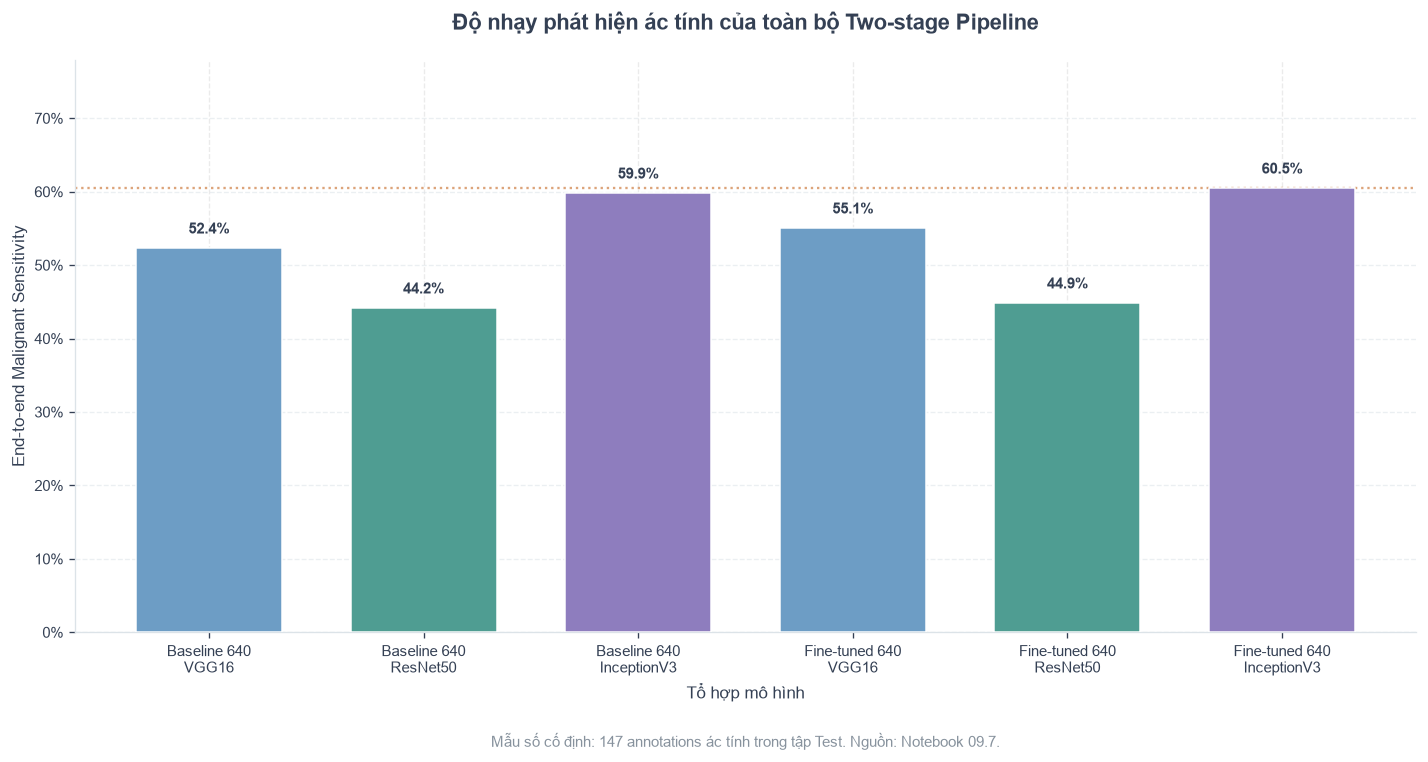

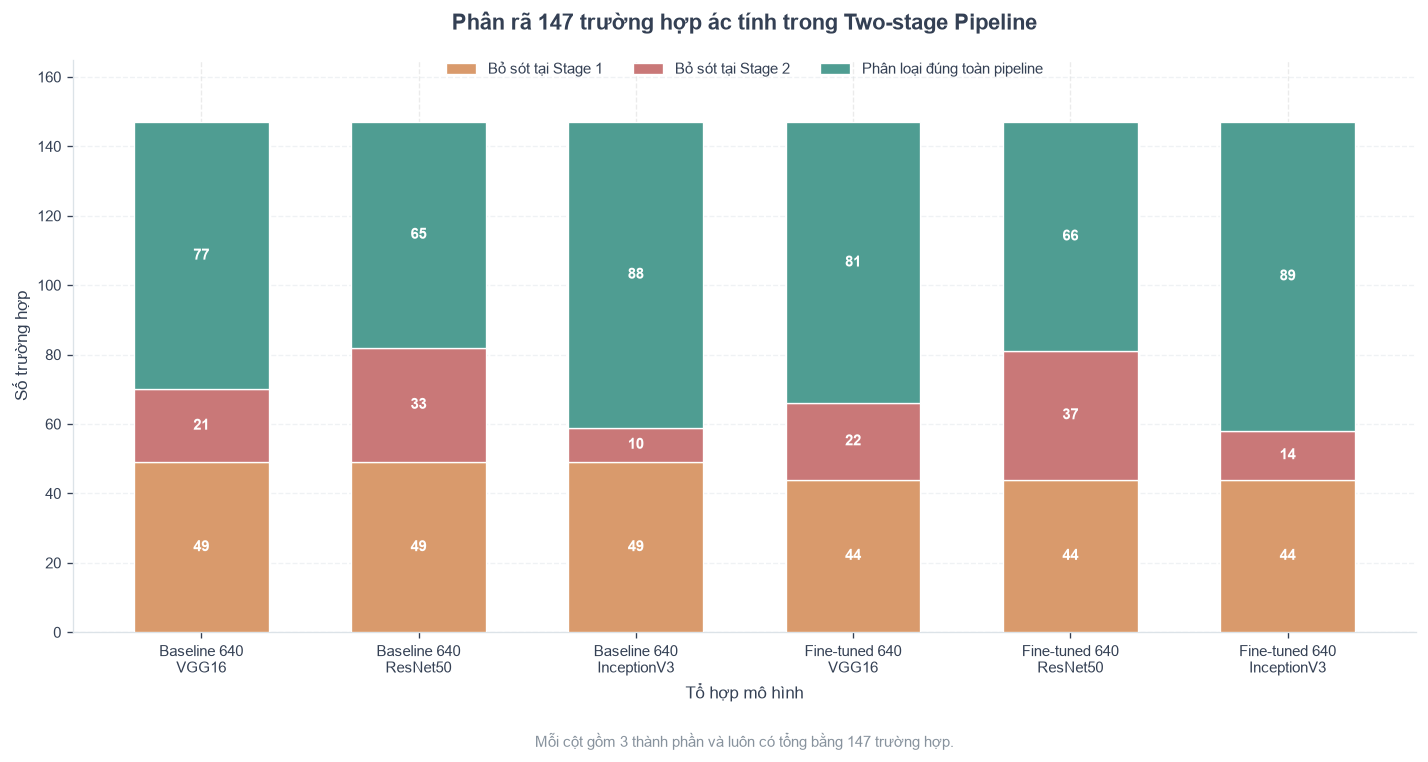

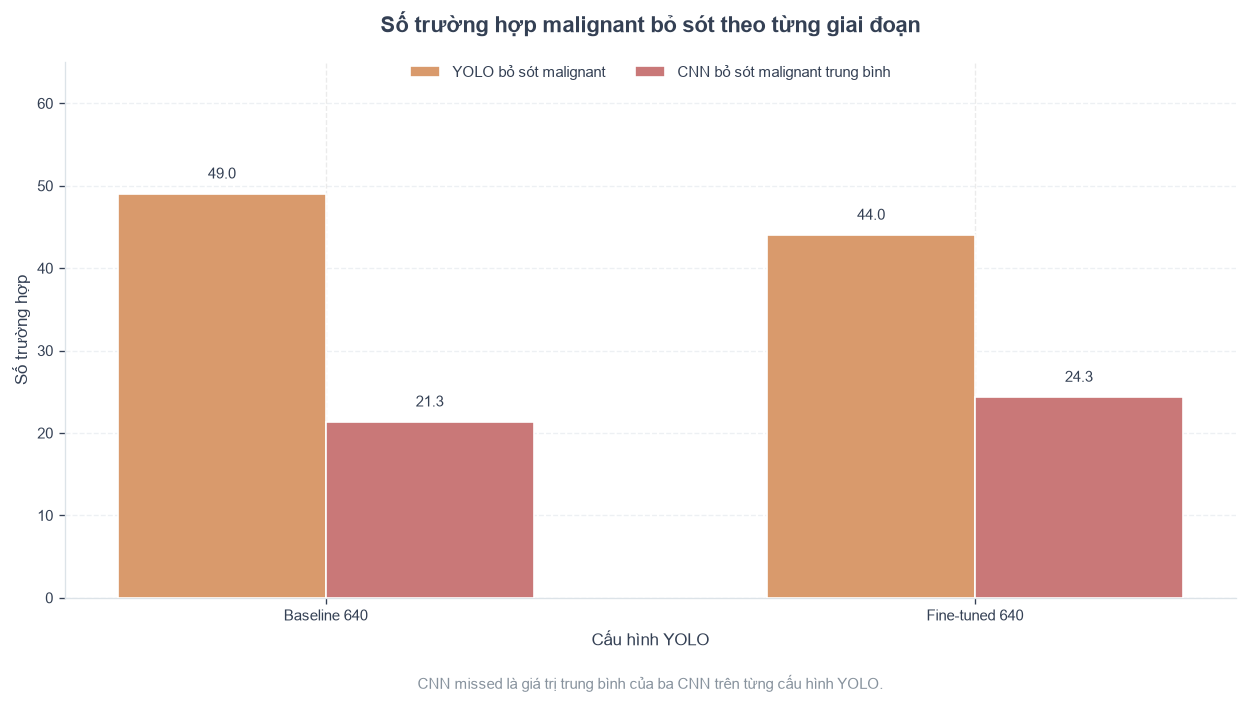

10.7 — TRỰC QUAN HÓA VÀ SO SÁNH TWO-STAGE PIPELINE

1. SO SÁNH 6 TỔ HỢP MÔ HÌNH


,YOLO,CNN,Matched_Crops,CNN_F1,YOLO_Missed_Malignant,CNN_Missed_Malignant,E2E_Malignant_TP,E2E_Malignant_Total,E2E_Sensitivity,E2E_Miss_Total,E2E_Miss_Rate
0,Fine-tuned 640,InceptionV3,226,0.6926,44,14,89,147,0.605442,58,0.394558
1,Baseline 640,InceptionV3,206,0.7273,49,10,88,147,0.598639,59,0.401361
2,Fine-tuned 640,VGG16,226,0.6612,44,22,81,147,0.551020,66,0.448980
3,Baseline 640,VGG16,206,0.7000,49,21,77,147,0.523810,70,0.476190
4,Fine-tuned 640,ResNet50,226,0.6600,44,37,66,147,0.448980,81,0.551020
5,Baseline 640,ResNet50,206,0.6842,49,33,65,147,0.442177,82,0.557823



2. TỔNG HỢP THEO CẤU HÌNH YOLO


,YOLO,Matched_Crops_Per_CNN,YOLO_Missed_Malignant,Mean_CNN_Missed_Malignant,Mean_E2E_Sensitivity,Best_CNN,Best_E2E_Sensitivity
0,Baseline 640,206,49,21.333333,0.521542,InceptionV3,0.598639
1,Fine-tuned 640,226,44,24.333333,0.535147,InceptionV3,0.605442



3. PHÂN RÃ CÁC TRƯỜNG HỢP MALIGNANT


,YOLO,CNN,Stage1_Missed,Stage2_Missed,Correct_Malignant,Total_Malignant
0,Baseline 640,VGG16,49,21,77,147
1,Baseline 640,ResNet50,49,33,65,147
2,Baseline 640,InceptionV3,49,10,88,147
3,Fine-tuned 640,VGG16,44,22,81,147
4,Fine-tuned 640,ResNet50,44,37,66,147
5,Fine-tuned 640,InceptionV3,44,14,89,147



4. TỔ HỢP DẪN ĐẦU
YOLO: Fine-tuned 640
CNN: InceptionV3
E2E malignant sensitivity: 60.54%
Malignant nhận diện đúng: 89/147

5. KIỂM TRA TÍNH TOÀN VẸN
Dữ liệu: Có đủ 6 tổ hợp YOLO và CNN                                        : PASS
Dữ liệu: Có đủ 2 cấu hình YOLO                                             : PASS
Dữ liệu: Có đủ 3 mô hình CNN                                               : PASS
Dữ liệu: Baseline có 206 matched crops                                     : PASS
Dữ liệu: Fine-tuned có 226 matched crops                                   : PASS
Dữ liệu: Tổng malignant của mỗi tổ hợp bằng 147                            : PASS
Dữ liệu: E2E TP nhất quán với CNN TP                                       : PASS
Dữ liệu: E2E Sensitivity nhất quán với TP / 147                            : PASS
Dữ liệu: Các chỉ số F1 và Sensitivity hợp lệ                               : PASS
Biểu đồ: nb10_7_figure_01_two_stage_e2e_sensitivity.png                    : PASS
Biểu đồ: nb10_7_figure_02_mal

In [11]:
# 10.7 — TRỰC QUAN HÓA VÀ SO SÁNH TWO-STAGE PIPELINE

# ============================================================
# 1. KIỂM TRA MÔI TRƯỜNG VÀ CẤU HÌNH
# ============================================================

required_variables = [
    "FIGURES_DIR",
    "TABLES_DIR",
    "REPORTS_DIR",
    "NB10_6_PASS"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Thiếu cấu hình từ các mục trước: "
        + ", ".join(missing_variables)
    )

if not NB10_6_PASS:
    raise RuntimeError(
        "Notebook 10.6 chưa PASS. Không thể tiếp tục 10.7."
    )

FIGURES_DIR = Path(FIGURES_DIR)
TABLES_DIR = Path(TABLES_DIR)
REPORTS_DIR = Path(REPORTS_DIR)

for directory in [FIGURES_DIR, TABLES_DIR, REPORTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


# Bảng màu thống nhất
COLORS = {
    "navy": "#355070",
    "blue": "#6D9DC5",
    "teal": "#4F9D92",
    "green": "#83B692",
    "purple": "#8E7DBE",
    "orange": "#D99A6C",
    "red": "#C97878",
    "gray": "#87929D",
    "light": "#EAF0F4",
    "text": "#344054",
    "grid": "#DCE3E8"
}

CNN_COLORS = {
    "VGG16": COLORS["blue"],
    "ResNet50": COLORS["teal"],
    "InceptionV3": COLORS["purple"]
}

YOLO_COLORS = {
    "Baseline 640": COLORS["blue"],
    "Fine-tuned 640": COLORS["purple"]
}

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.labelcolor": COLORS["text"],
    "xtick.color": COLORS["text"],
    "ytick.color": COLORS["text"],
    "text.color": COLORS["text"],
    "axes.edgecolor": COLORS["grid"],
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white"
})


# ============================================================
# 2. TỔNG HỢP KẾT QUẢ SIX TWO-STAGE COMBINATIONS
#    Nguồn: Notebook 09.7 và 09.8
# ============================================================

pipeline_records = [
    {
        "YOLO": "Baseline 640",
        "CNN": "VGG16",
        "Matched_Crops": 206,
        "CNN_F1": 0.7000,
        "CNN_TP": 77,
        "CNN_FN": 21,
        "CNN_FP": 45,
        "YOLO_Missed_Malignant": 49,
        "CNN_Missed_Malignant": 21,
        "E2E_Malignant_TP": 77,
        "E2E_Malignant_Total": 147,
        "E2E_Sensitivity": 0.523810
    },
    {
        "YOLO": "Baseline 640",
        "CNN": "ResNet50",
        "Matched_Crops": 206,
        "CNN_F1": 0.6842,
        "CNN_TP": 65,
        "CNN_FN": 33,
        "CNN_FP": 27,
        "YOLO_Missed_Malignant": 49,
        "CNN_Missed_Malignant": 33,
        "E2E_Malignant_TP": 65,
        "E2E_Malignant_Total": 147,
        "E2E_Sensitivity": 0.442177
    },
    {
        "YOLO": "Baseline 640",
        "CNN": "InceptionV3",
        "Matched_Crops": 206,
        "CNN_F1": 0.7273,
        "CNN_TP": 88,
        "CNN_FN": 10,
        "CNN_FP": 56,
        "YOLO_Missed_Malignant": 49,
        "CNN_Missed_Malignant": 10,
        "E2E_Malignant_TP": 88,
        "E2E_Malignant_Total": 147,
        "E2E_Sensitivity": 0.598639
    },
    {
        "YOLO": "Fine-tuned 640",
        "CNN": "VGG16",
        "Matched_Crops": 226,
        "CNN_F1": 0.6612,
        "CNN_TP": 81,
        "CNN_FN": 22,
        "CNN_FP": 61,
        "YOLO_Missed_Malignant": 44,
        "CNN_Missed_Malignant": 22,
        "E2E_Malignant_TP": 81,
        "E2E_Malignant_Total": 147,
        "E2E_Sensitivity": 0.551020
    },
    {
        "YOLO": "Fine-tuned 640",
        "CNN": "ResNet50",
        "Matched_Crops": 226,
        "CNN_F1": 0.6600,
        "CNN_TP": 66,
        "CNN_FN": 37,
        "CNN_FP": 31,
        "YOLO_Missed_Malignant": 44,
        "CNN_Missed_Malignant": 37,
        "E2E_Malignant_TP": 66,
        "E2E_Malignant_Total": 147,
        "E2E_Sensitivity": 0.448980
    },
    {
        "YOLO": "Fine-tuned 640",
        "CNN": "InceptionV3",
        "Matched_Crops": 226,
        "CNN_F1": 0.6926,
        "CNN_TP": 89,
        "CNN_FN": 14,
        "CNN_FP": 65,
        "YOLO_Missed_Malignant": 44,
        "CNN_Missed_Malignant": 14,
        "E2E_Malignant_TP": 89,
        "E2E_Malignant_Total": 147,
        "E2E_Sensitivity": 0.605442
    }
]

pipeline_df = pd.DataFrame(pipeline_records)


# ============================================================
# 3. TẠO BẢNG PHÂN RÃ KẾT QUẢ MALIGNANT
# ============================================================

pipeline_df["Total_Malignant_Check"] = (
    pipeline_df["YOLO_Missed_Malignant"]
    + pipeline_df["CNN_Missed_Malignant"]
    + pipeline_df["E2E_Malignant_TP"]
)

pipeline_df["E2E_Miss_Total"] = (
    pipeline_df["YOLO_Missed_Malignant"]
    + pipeline_df["CNN_Missed_Malignant"]
)

pipeline_df["E2E_Miss_Rate"] = (
    pipeline_df["E2E_Miss_Total"]
    / pipeline_df["E2E_Malignant_Total"]
)

pipeline_df["YOLO_Missed_Ratio"] = (
    pipeline_df["YOLO_Missed_Malignant"]
    / pipeline_df["E2E_Malignant_Total"]
)

pipeline_df["CNN_Missed_Ratio"] = (
    pipeline_df["CNN_Missed_Malignant"]
    / pipeline_df["E2E_Malignant_Total"]
)


# ============================================================
# 4. XÁC ĐỊNH MÔ HÌNH DẪN ĐẦU
# ============================================================

best_pipeline_index = pipeline_df[
    "E2E_Sensitivity"
].idxmax()

best_pipeline = pipeline_df.loc[best_pipeline_index]

best_by_yolo = (
    pipeline_df
    .sort_values("E2E_Sensitivity", ascending=False)
    .groupby("YOLO", as_index=False)
    .first()
)


# ============================================================
# 5. KIỂM TRA TÍNH TOÀN VẸN
# ============================================================

DATA_CHECKS = {
    "Có đủ 6 tổ hợp YOLO và CNN": (
        len(pipeline_df) == 6
    ),

    "Có đủ 2 cấu hình YOLO": (
        pipeline_df["YOLO"].nunique() == 2
    ),

    "Có đủ 3 mô hình CNN": (
        pipeline_df["CNN"].nunique() == 3
    ),

    "Baseline có 206 matched crops": (
        (
            pipeline_df.loc[
                pipeline_df["YOLO"] == "Baseline 640",
                "Matched_Crops"
            ] == 206
        ).all()
    ),

    "Fine-tuned có 226 matched crops": (
        (
            pipeline_df.loc[
                pipeline_df["YOLO"] == "Fine-tuned 640",
                "Matched_Crops"
            ] == 226
        ).all()
    ),

    "Tổng malignant của mỗi tổ hợp bằng 147": (
        (
            pipeline_df["Total_Malignant_Check"] == 147
        ).all()
    ),

    "E2E TP nhất quán với CNN TP": (
        (
            pipeline_df["E2E_Malignant_TP"]
            == pipeline_df["CNN_TP"]
        ).all()
    ),

    "E2E Sensitivity nhất quán với TP / 147": (
        np.allclose(
            pipeline_df["E2E_Sensitivity"],
            pipeline_df["E2E_Malignant_TP"] / 147,
            atol=1e-5
        )
    ),

    "Các chỉ số F1 và Sensitivity hợp lệ": (
        pipeline_df[
            ["CNN_F1", "E2E_Sensitivity"]
        ].apply(
            lambda column: column.between(0, 1).all()
        ).all()
    )
}

DATA_CHECKS = {
    key: bool(value)
    for key, value in DATA_CHECKS.items()
}

if not all(DATA_CHECKS.values()):
    raise ValueError(
        "Dữ liệu Two-stage Pipeline không vượt qua kiểm tra."
    )


# ============================================================
# 6. BIỂU ĐỒ 1 — E2E MALIGNANT SENSITIVITY
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6.5))

x = np.arange(len(pipeline_df))

bar_colors = [
    CNN_COLORS[c] for c in pipeline_df["CNN"]
]

bars = ax.bar(
    x,
    pipeline_df["E2E_Sensitivity"],
    color=bar_colors,
    width=0.68,
    edgecolor="white",
    linewidth=0.9,
    zorder=3
)

for index, bar in enumerate(bars):

    value = pipeline_df.iloc[index]["E2E_Sensitivity"]

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{value:.1%}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

ax.set_title(
    "Độ nhạy phát hiện ác tính của toàn bộ Two-stage Pipeline",
    pad=18
)

ax.set_xlabel("Tổ hợp mô hình")
ax.set_ylabel("End-to-end Malignant Sensitivity")

ax.set_xticks(x)
ax.set_xticklabels([
    f"{row.YOLO}\n{row.CNN}"
    for row in pipeline_df.itertuples()
])

ax.set_ylim(0, 0.78)
ax.set_yticks(np.arange(0, 0.71, 0.1))
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:.0%}")
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.55,
    color=COLORS["grid"],
    zorder=0
)

ax.axhline(
    best_pipeline["E2E_Sensitivity"],
    color=COLORS["orange"],
    linestyle=":",
    linewidth=1.4,
    alpha=0.9
)

ax.text(
    0.5,
    -0.20,
    "Mẫu số cố định: 147 annotations ác tính trong tập Test. "
    "Nguồn: Notebook 09.7.",
    transform=ax.transAxes,
    ha="center",
    fontsize=9,
    color=COLORS["gray"]
)

fig.tight_layout()

figure_01_path = (
    FIGURES_DIR /
    "nb10_7_figure_01_two_stage_e2e_sensitivity.png"
)

fig.savefig(
    figure_01_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 7. BIỂU ĐỒ 2 — PHÂN RÃ CÁC TRƯỜNG HỢP MALIGNANT
#
#    YOLO missed: Stage 1 bỏ sót
#    CNN missed: Stage 1 phát hiện nhưng Stage 2 phân loại sai
#    Correct: Toàn bộ pipeline nhận diện đúng malignant
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6.5))

x = np.arange(len(pipeline_df))
bar_width = 0.62

stages = [
    (
        "YOLO missed",
        "YOLO_Missed_Malignant",
        COLORS["orange"],
        "Bỏ sót tại Stage 1"
    ),
    (
        "CNN missed",
        "CNN_Missed_Malignant",
        COLORS["red"],
        "Bỏ sót tại Stage 2"
    ),
    (
        "Correct",
        "E2E_Malignant_TP",
        COLORS["teal"],
        "Phân loại đúng toàn pipeline"
    )
]

bottom = np.zeros(len(pipeline_df))

for label, column, color, legend_label in stages:

    values = pipeline_df[column].to_numpy()

    bars = ax.bar(
        x,
        values,
        bar_width,
        bottom=bottom,
        color=color,
        edgecolor="white",
        linewidth=0.8,
        label=legend_label,
        zorder=3
    )

    for index, bar in enumerate(bars):

        if values[index] > 0:

            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bottom[index] + values[index] / 2,
                str(int(values[index])),
                ha="center",
                va="center",
                fontsize=9,
                color="white",
                fontweight="bold"
            )

    bottom += values

ax.set_title(
    "Phân rã 147 trường hợp ác tính trong Two-stage Pipeline",
    pad=18
)

ax.set_xlabel("Tổ hợp mô hình")
ax.set_ylabel("Số trường hợp")

ax.set_xticks(x)
ax.set_xticklabels([
    f"{row.YOLO}\n{row.CNN}"
    for row in pipeline_df.itertuples()
])

ax.set_ylim(0, 165)
ax.set_yticks(np.arange(0, 161, 20))

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.45,
    color=COLORS["grid"],
    zorder=0
)

ax.legend(
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=3
)

ax.text(
    0.5,
    -0.20,
    "Mỗi cột gồm 3 thành phần và luôn có tổng bằng 147 trường hợp.",
    transform=ax.transAxes,
    ha="center",
    fontsize=9,
    color=COLORS["gray"]
)

fig.tight_layout()

figure_02_path = (
    FIGURES_DIR /
    "nb10_7_figure_02_malignant_error_decomposition.png"
)

fig.savefig(
    figure_02_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 8. BIỂU ĐỒ 3 — SO SÁNH YOLO VÀ CNN THEO GIAI ĐOẠN
# ============================================================

stage_summary = (
    pipeline_df
    .groupby("YOLO", as_index=False)
    .agg(
        YOLO_Missed_Malignant=(
            "YOLO_Missed_Malignant", "first"
        ),
        Mean_CNN_Missed_Malignant=(
            "CNN_Missed_Malignant", "mean"
        ),
        Mean_E2E_Sensitivity=(
            "E2E_Sensitivity", "mean"
        )
    )
)

fig, ax = plt.subplots(figsize=(10.5, 6))

x = np.arange(len(stage_summary))
width = 0.32

bars_1 = ax.bar(
    x - width / 2,
    stage_summary["YOLO_Missed_Malignant"],
    width,
    color=COLORS["orange"],
    label="YOLO bỏ sót malignant",
    edgecolor="white",
    zorder=3
)

bars_2 = ax.bar(
    x + width / 2,
    stage_summary["Mean_CNN_Missed_Malignant"],
    width,
    color=COLORS["red"],
    label="CNN bỏ sót malignant trung bình",
    edgecolor="white",
    zorder=3
)

for bars in [bars_1, bars_2]:

    for bar in bars:

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1.5,
            f"{bar.get_height():.1f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

ax.set_title(
    "Số trường hợp malignant bỏ sót theo từng giai đoạn",
    pad=18
)

ax.set_xlabel("Cấu hình YOLO")
ax.set_ylabel("Số trường hợp")

ax.set_xticks(x)
ax.set_xticklabels(stage_summary["YOLO"])

ax.set_ylim(0, 65)
ax.set_yticks(np.arange(0, 61, 10))

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.5,
    color=COLORS["grid"],
    zorder=0
)

ax.legend(
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2
)

ax.text(
    0.5,
    -0.17,
    "CNN missed là giá trị trung bình của ba CNN trên từng cấu hình YOLO.",
    transform=ax.transAxes,
    ha="center",
    fontsize=9,
    color=COLORS["gray"]
)

fig.tight_layout()

figure_03_path = (
    FIGURES_DIR /
    "nb10_7_figure_03_stage_missed_malignant.png"
)

fig.savefig(
    figure_03_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 9. TẠO BẢNG SO SÁNH THEO TỪNG TỔ HỢP
# ============================================================

comparison_columns = [
    "YOLO",
    "CNN",
    "Matched_Crops",
    "CNN_F1",
    "YOLO_Missed_Malignant",
    "CNN_Missed_Malignant",
    "E2E_Malignant_TP",
    "E2E_Malignant_Total",
    "E2E_Sensitivity",
    "E2E_Miss_Total",
    "E2E_Miss_Rate"
]

pipeline_comparison_df = pipeline_df[
    comparison_columns
].copy()

pipeline_comparison_df = (
    pipeline_comparison_df.sort_values(
        "E2E_Sensitivity",
        ascending=False
    ).reset_index(drop=True)
)


# ============================================================
# 10. TẠO BẢNG TỔNG HỢP THEO CẤU HÌNH YOLO
# ============================================================

yolo_summary_records = []

for yolo_name in ["Baseline 640", "Fine-tuned 640"]:

    subset = pipeline_df[
        pipeline_df["YOLO"] == yolo_name
    ]

    best_row = subset.loc[
        subset["E2E_Sensitivity"].idxmax()
    ]

    yolo_summary_records.append({
        "YOLO": yolo_name,
        "Matched_Crops_Per_CNN": int(
            subset["Matched_Crops"].iloc[0]
        ),
        "YOLO_Missed_Malignant": int(
            subset["YOLO_Missed_Malignant"].iloc[0]
        ),
        "Mean_CNN_Missed_Malignant": float(
            subset["CNN_Missed_Malignant"].mean()
        ),
        "Mean_E2E_Sensitivity": float(
            subset["E2E_Sensitivity"].mean()
        ),
        "Best_CNN": best_row["CNN"],
        "Best_E2E_Sensitivity": float(
            best_row["E2E_Sensitivity"]
        )
    })

yolo_pipeline_summary_df = pd.DataFrame(
    yolo_summary_records
)


# ============================================================
# 11. TẠO BẢNG PHÂN RÃ MALIGNANT
# ============================================================

decomposition_df = pipeline_df[
    [
        "YOLO",
        "CNN",
        "YOLO_Missed_Malignant",
        "CNN_Missed_Malignant",
        "E2E_Malignant_TP",
        "Total_Malignant_Check"
    ]
].copy()

decomposition_df = decomposition_df.rename(
    columns={
        "YOLO_Missed_Malignant": "Stage1_Missed",
        "CNN_Missed_Malignant": "Stage2_Missed",
        "E2E_Malignant_TP": "Correct_Malignant",
        "Total_Malignant_Check": "Total_Malignant"
    }
)


# ============================================================
# 12. XUẤT CÁC BẢNG CSV
# ============================================================

tables_to_save = {
    "nb10_7_two_stage_pipeline_comparison.csv": (
        pipeline_comparison_df
    ),
    "nb10_7_yolo_pipeline_summary.csv": (
        yolo_pipeline_summary_df
    ),
    "nb10_7_malignant_error_decomposition.csv": (
        decomposition_df
    )
}

saved_table_paths = []

for filename, dataframe in tables_to_save.items():

    output_path = TABLES_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    saved_table_paths.append(output_path)


# ============================================================
# 13. KIỂM TRA TỆP ĐẦU RA
# ============================================================

figure_paths = [
    figure_01_path,
    figure_02_path,
    figure_03_path
]

figure_checks = {
    path.name: bool(
        path.exists() and path.stat().st_size > 0
    )
    for path in figure_paths
}

table_checks = {
    path.name: bool(
        path.exists() and path.stat().st_size > 0
    )
    for path in saved_table_paths
}

NB10_7_CHECKS = {
    **{
        f"Dữ liệu: {name}": bool(status)
        for name, status in DATA_CHECKS.items()
    },
    **{
        f"Biểu đồ: {name}": bool(status)
        for name, status in figure_checks.items()
    },
    **{
        f"Bảng: {name}": bool(status)
        for name, status in table_checks.items()
    }
}

NB10_7_PASS = bool(all(NB10_7_CHECKS.values()))


# ============================================================
# 14. XUẤT BÁO CÁO JSON
# ============================================================

NB10_7_REPORT = {
    "section": "10.7",
    "title": "Trực quan hóa và so sánh Two-stage Pipeline",
    "created_at": datetime.now().isoformat(timespec="seconds"),

    "test_population": {
        "malignant_annotations": 147,
        "test_images": 361,
        "test_annotations": 378,
        "test_patients": 201
    },

    "pipeline_combinations": pipeline_records,

    "best_pipeline": {
        "YOLO": str(best_pipeline["YOLO"]),
        "CNN": str(best_pipeline["CNN"]),
        "E2E_Malignant_TP": int(
            best_pipeline["E2E_Malignant_TP"]
        ),
        "E2E_Malignant_Total": 147,
        "E2E_Sensitivity": float(
            best_pipeline["E2E_Sensitivity"]
        )
    },

    "figures": [
        str(path) for path in figure_paths
    ],

    "tables": [
        str(path) for path in saved_table_paths
    ],

    "checks": NB10_7_CHECKS,

    "interpretation": [
        (
            "InceptionV3 đạt E2E malignant sensitivity cao nhất "
            "trong cả hai cấu hình YOLO được đánh giá."
        ),
        (
            "Fine-tuned 640 giảm số malignant bị YOLO bỏ sót "
            "từ 49 xuống 44 so với Baseline 640."
        ),
        (
            "Ở tổ hợp Fine-tuned 640 + InceptionV3, "
            "89 trên 147 trường hợp malignant được nhận diện đúng."
        ),
        (
            "Stage 1 và Stage 2 đều có thể tạo ra trường hợp bỏ sót "
            "trong toàn bộ pipeline."
        )
    ],

    "methodological_notes": [
        (
            "E2E malignant sensitivity được tính trên toàn bộ "
            "147 annotations ác tính của tập Test."
        ),
        (
            "Malignant bị YOLO bỏ sót được tính là lỗi tại Stage 1."
        ),
        (
            "Malignant được YOLO phát hiện nhưng CNN phân loại "
            "thành BENIGN được tính là lỗi tại Stage 2."
        ),
        (
            "Detection FP không có nhãn pathology Ground Truth "
            "tương ứng nên không được cộng vào phân rã 147 "
            "annotations malignant."
        ),
        (
            "CNN_F1 được tính trên các predicted crops đã ghép "
            "khớp với annotation, không phải trên toàn bộ ảnh Test."
        )
    ],

    "limitations": [
        (
            "Kết quả phản ánh tập Test CBIS-DDSM và các cấu hình "
            "thực nghiệm đã đánh giá."
        ),
        (
            "Không diễn giải E2E sensitivity như một chỉ số "
            "chẩn đoán lâm sàng."
        )
    ],

    "status": "PASS" if NB10_7_PASS else "FAIL"
}

NB10_7_REPORT_PATH = (
    REPORTS_DIR /
    "nb10_7_two_stage_pipeline_report.json"
)

with open(
    NB10_7_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        NB10_7_REPORT,
        file,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )


# ============================================================
# 15. ĐỌC LẠI VÀ KIỂM TRA BÁO CÁO JSON
# ============================================================

with open(
    NB10_7_REPORT_PATH,
    "r",
    encoding="utf-8"
) as file:

    loaded_report = json.load(file)

json_check = bool(
    isinstance(loaded_report, dict)
    and loaded_report.get("section") == "10.7"
    and len(loaded_report.get("pipeline_combinations", [])) == 6
    and len(loaded_report.get("figures", [])) == 3
    and len(loaded_report.get("tables", [])) == 3
)

NB10_7_CHECKS["Báo cáo JSON đọc lại thành công"] = json_check

NB10_7_PASS = bool(all(NB10_7_CHECKS.values()))

loaded_report["checks"] = NB10_7_CHECKS
loaded_report["status"] = (
    "PASS" if NB10_7_PASS else "FAIL"
)

with open(
    NB10_7_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        loaded_report,
        file,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )


# ============================================================
# 16. HIỂN THỊ KẾT QUẢ
# ============================================================

print("10.7 — TRỰC QUAN HÓA VÀ SO SÁNH TWO-STAGE PIPELINE")

print("\n1. SO SÁNH 6 TỔ HỢP MÔ HÌNH")
display(pipeline_comparison_df)

print("\n2. TỔNG HỢP THEO CẤU HÌNH YOLO")
display(yolo_pipeline_summary_df)

print("\n3. PHÂN RÃ CÁC TRƯỜNG HỢP MALIGNANT")
display(decomposition_df)

print("\n4. TỔ HỢP DẪN ĐẦU")

print(
    f"YOLO: {best_pipeline['YOLO']}"
)

print(
    f"CNN: {best_pipeline['CNN']}"
)

print(
    f"E2E malignant sensitivity: "
    f"{best_pipeline['E2E_Sensitivity']:.2%}"
)

print(
    f"Malignant nhận diện đúng: "
    f"{int(best_pipeline['E2E_Malignant_TP'])}/147"
)

print("\n5. KIỂM TRA TÍNH TOÀN VẸN")

for check_name, check_status in NB10_7_CHECKS.items():

    print(
        f"{check_name:<75}: "
        f"{'PASS' if check_status else 'FAIL'}"
    )

print("\n6. TỆP ĐẦU RA")

for path in figure_paths:
    print(f"Biểu đồ: {path}")

for path in saved_table_paths:
    print(f"Bảng: {path}")

print(f"Báo cáo: {NB10_7_REPORT_PATH}")

print("\n7. NHẬN XÉT KẾT QUẢ")

print(
    "- InceptionV3 đạt E2E malignant sensitivity cao nhất "
    "ở cả hai cấu hình YOLO."
)

print(
    "- Fine-tuned 640 giảm số malignant bị Stage 1 bỏ sót "
    "từ 49 xuống 44 trường hợp."
)

print(
    "- Tổ hợp Fine-tuned 640 + InceptionV3 nhận diện đúng "
    f"{int(best_pipeline['E2E_Malignant_TP'])}/147 "
    "trường hợp malignant."
)

print(
    "- Cần xem xét đồng thời lỗi ở Stage 1 và Stage 2 "
    "khi đánh giá toàn bộ hệ thống."
)

print("\nKẾT LUẬN 10.7")
print(f"Số biểu đồ đã tạo: {len(figure_paths)}")
print(f"Số bảng đã xuất  : {len(saved_table_paths)}")
print(f"JSON kiểm tra    : {'PASS' if json_check else 'FAIL'}")
print(f"Trạng thái       : {'PASS' if NB10_7_PASS else 'FAIL'}")

if not NB10_7_PASS:
    raise RuntimeError(
        "10.7 chưa hoàn thành. Vui lòng kiểm tra các mục FAIL."
    )


### Đánh giá trọng tâm hiệu năng End-to-End của Two-stage Pipeline

Khi đánh giá khả năng nhận diện tổn thương ác tính xuyên suốt cả hai giai đoạn trên toàn bộ **147 annotations `MALIGNANT`** của tập Test, cần ghi nhận ba phát hiện cốt lõi sau:

| Cấu hình Two-stage Pipeline | Bỏ sót tại Stage 1 (`YOLO FN`) | Bỏ sót tại Stage 2 (`CNN FN`) | Phát hiện đúng (`E2E TP`) | Độ nhạy End-to-End (`E2E Sensitivity`) |
| :--- | :---: | :---: | :---: | :---: |
| **YOLOv5n Baseline 640 + InceptionV3** | 49 | **10** | 88 / 147 | 59,86% |
| **YOLOv5n Fine-tuned 640 + InceptionV3** | **44** | 14 | **89 / 147** | **60,54%** |
| *Chênh lệch (`Fine-tuned` so với `Baseline`)* | **-5 ca** | **+4 ca** | **+1 ca** | **+0,68%** |

* **1. Tổ hợp dẫn đầu về độ nhạy End-to-End:** Trong sáu cấu hình đã thử nghiệm, tổ hợp **`YOLOv5n Fine-tuned 640` + `InceptionV3`** đạt độ nhạy phát hiện tổn thương ác tính toàn quy trình (*End-to-End Malignant Sensitivity*) cao nhất với **89 / 147 trường hợp**, tương ứng **60,54%**.
* **2. Hiệu ứng bù trừ sai số giữa hai giai đoạn:** Việc sử dụng `YOLOv5n Fine-tuned 640` giúp giảm số ca ác tính bị bỏ sót ở Stage 1 từ **49** xuống **44 trường hợp** (cứu thêm 5 ca); tuy nhiên, trong số các vùng tổn thương bổ sung này, số ca ác tính bị bộ phân loại `InceptionV3` dự đoán nhầm ở Stage 2 lại tăng từ **10** lên **14 trường hợp**. Do đó, hiệu quả thực tế toàn hệ thống chỉ tăng ròng thêm **1 trường hợp** (từ 88 lên 89 ca).
* **3. Phạm vi diễn giải và giới hạn lâm sàng:** Chỉ số **60,54%** phản ánh tỷ lệ nhận diện đúng các vùng chú thích `MALIGNANT` trên toàn bộ **147 annotations** của tập Test trong phạm vi thực nghiệm, **không đồng nghĩa với độ chính xác chẩn đoán lâm sàng** trên bệnh nhân thực tế.

> **Lưu ý phương pháp luận:** Mức độ nhạy **60,54%** là kết quả cao nhất trong phạm vi **sáu tổ hợp mô hình đã khảo sát** dưới điều kiện phần cứng giới hạn; cần diễn giải đây là cấu hình tiềm năng nhất trong nhóm thực nghiệm thay vì khẳng định là mô hình tối ưu để triển khai trực tiếp trong thực hành lâm sàng.

Thư mục dự án: C:\Breast-Cancer-CBIS-DDSM
Nguồn Notebook 09.8: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb09_model_evaluation\nb09_8_error_analysis
Thư mục lưu kết quả: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb10_research_visualization
Nguồn Notebook 09.8 tồn tại: True

Đã xuất các bảng phân tích lỗi:
cnn_ground_truth_errors: 3 dòng
yolo_detection_errors: 2 dòng
cnn_predicted_crop_errors: 6 dòng
two_stage_error_decomposition: 6 dòng
cnn_error_probability_summary: 6 dòng


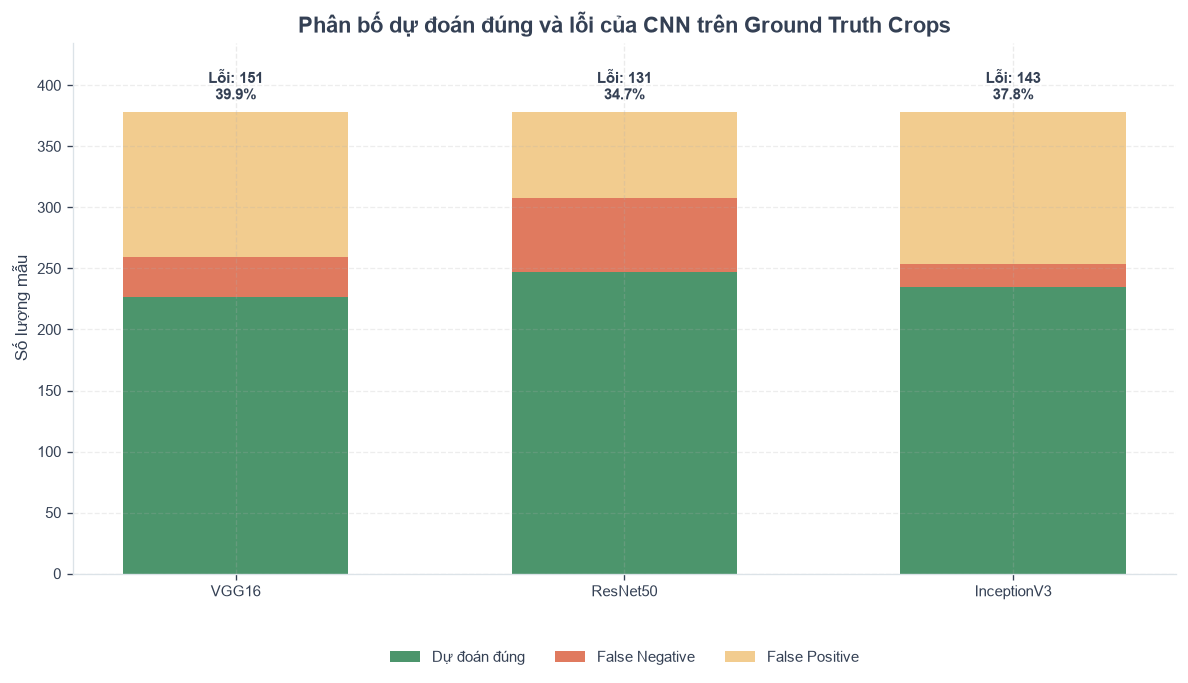

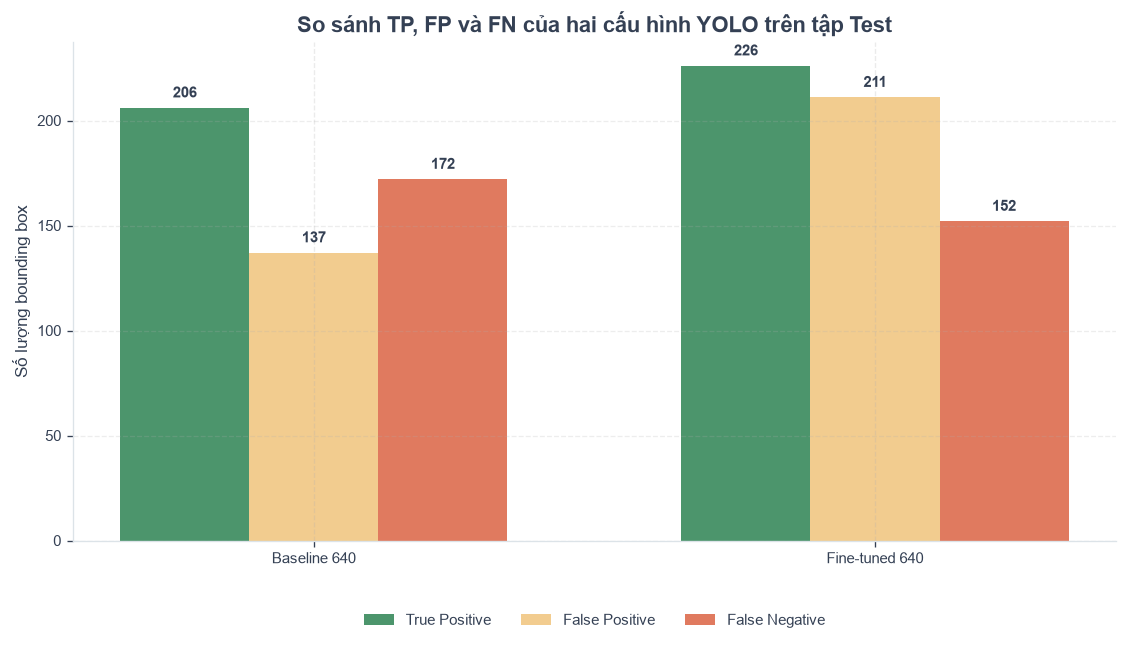

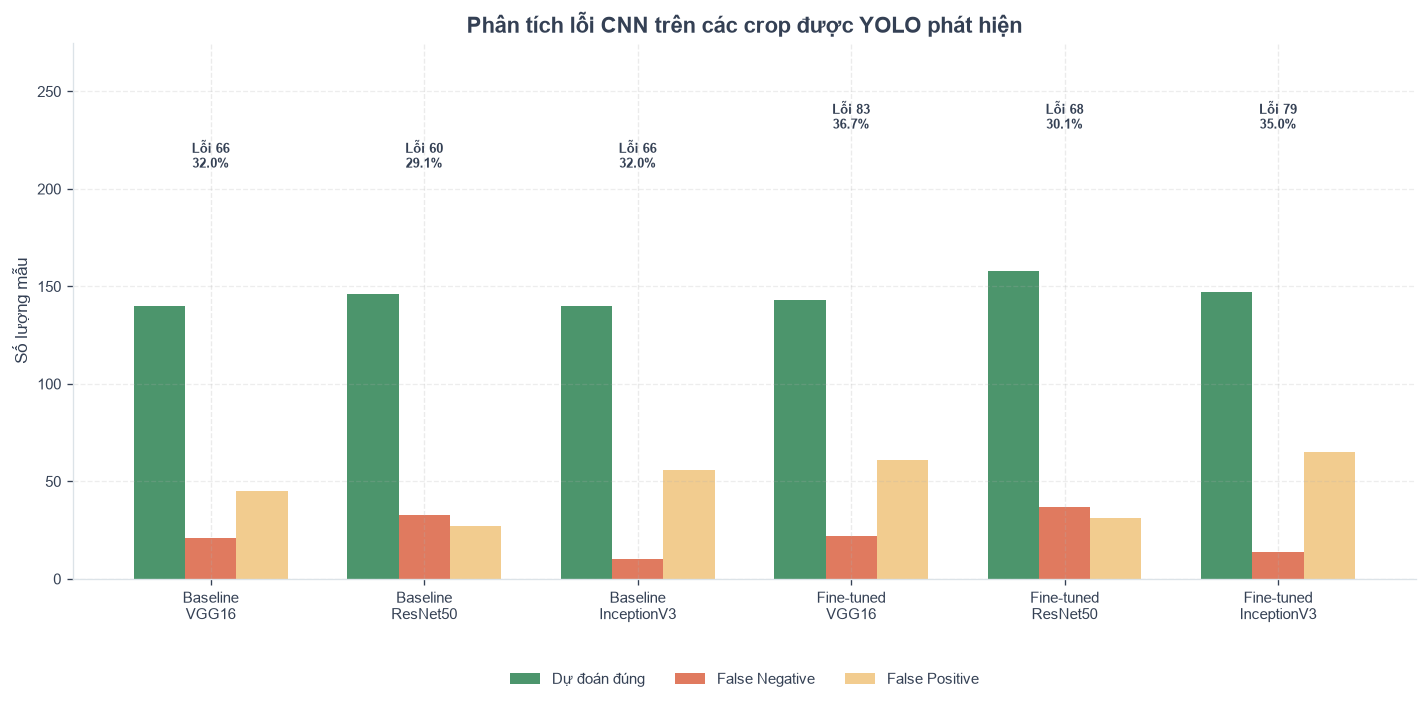

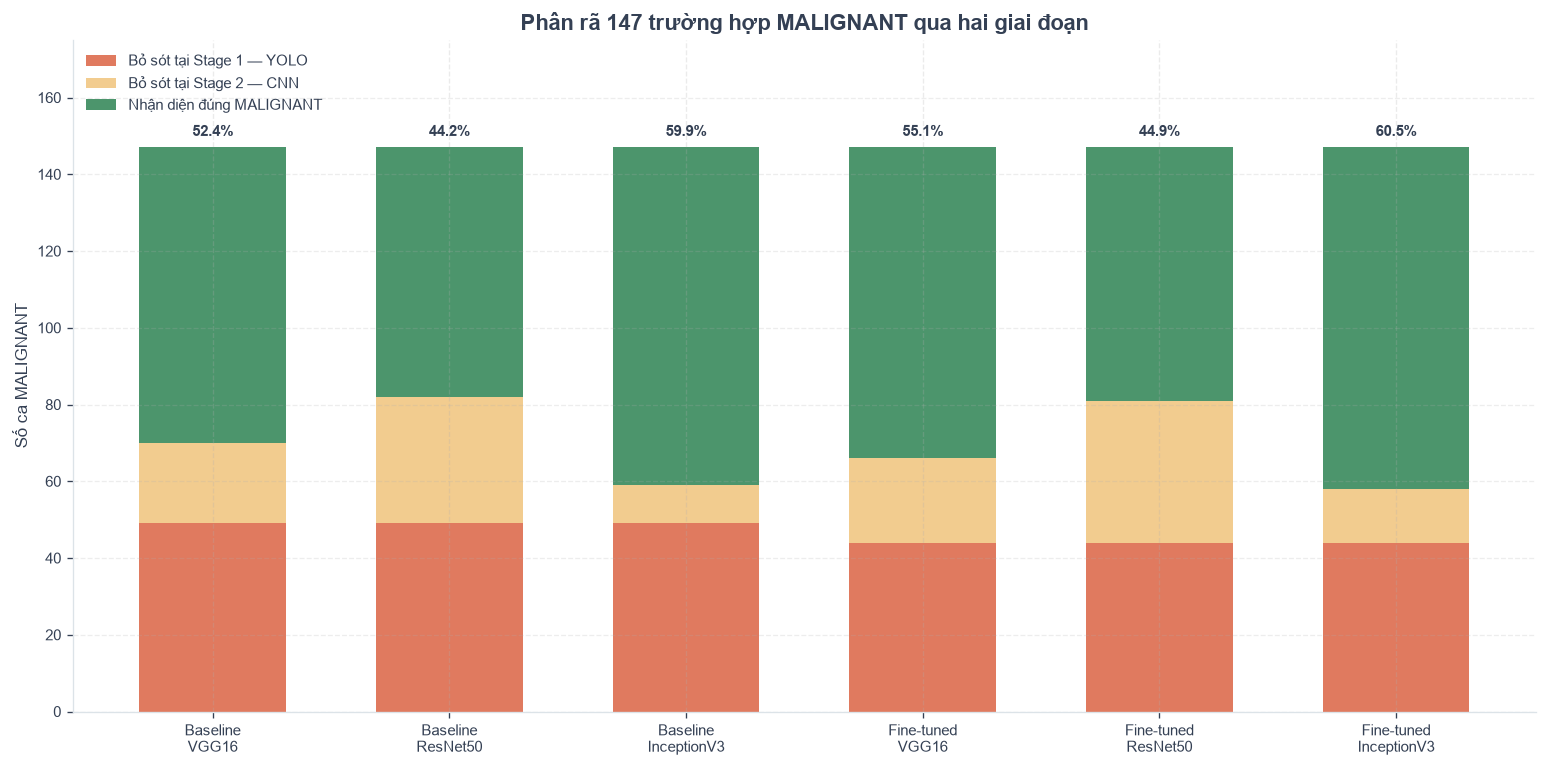

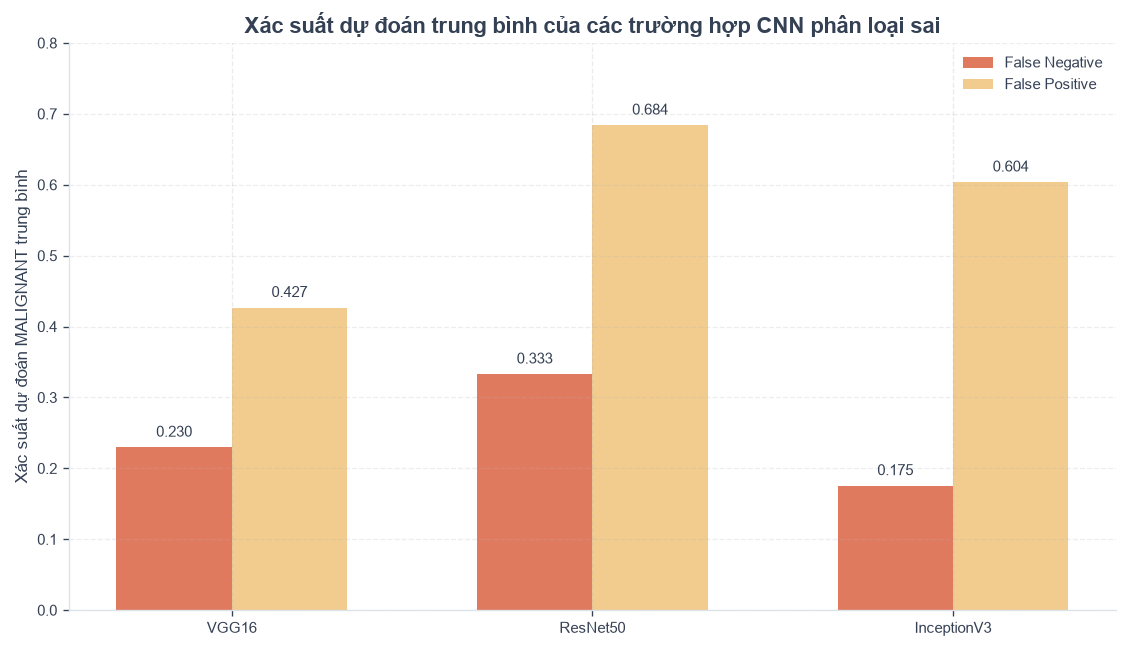


Hình ảnh minh họa tìm thấy: 2
Hình ảnh hợp lệ đã sao chép: 2
Hình ảnh không hợp lệ: 0
Ảnh: nb10_8_illustration_01.png
Ảnh: nb10_8_illustration_02.png


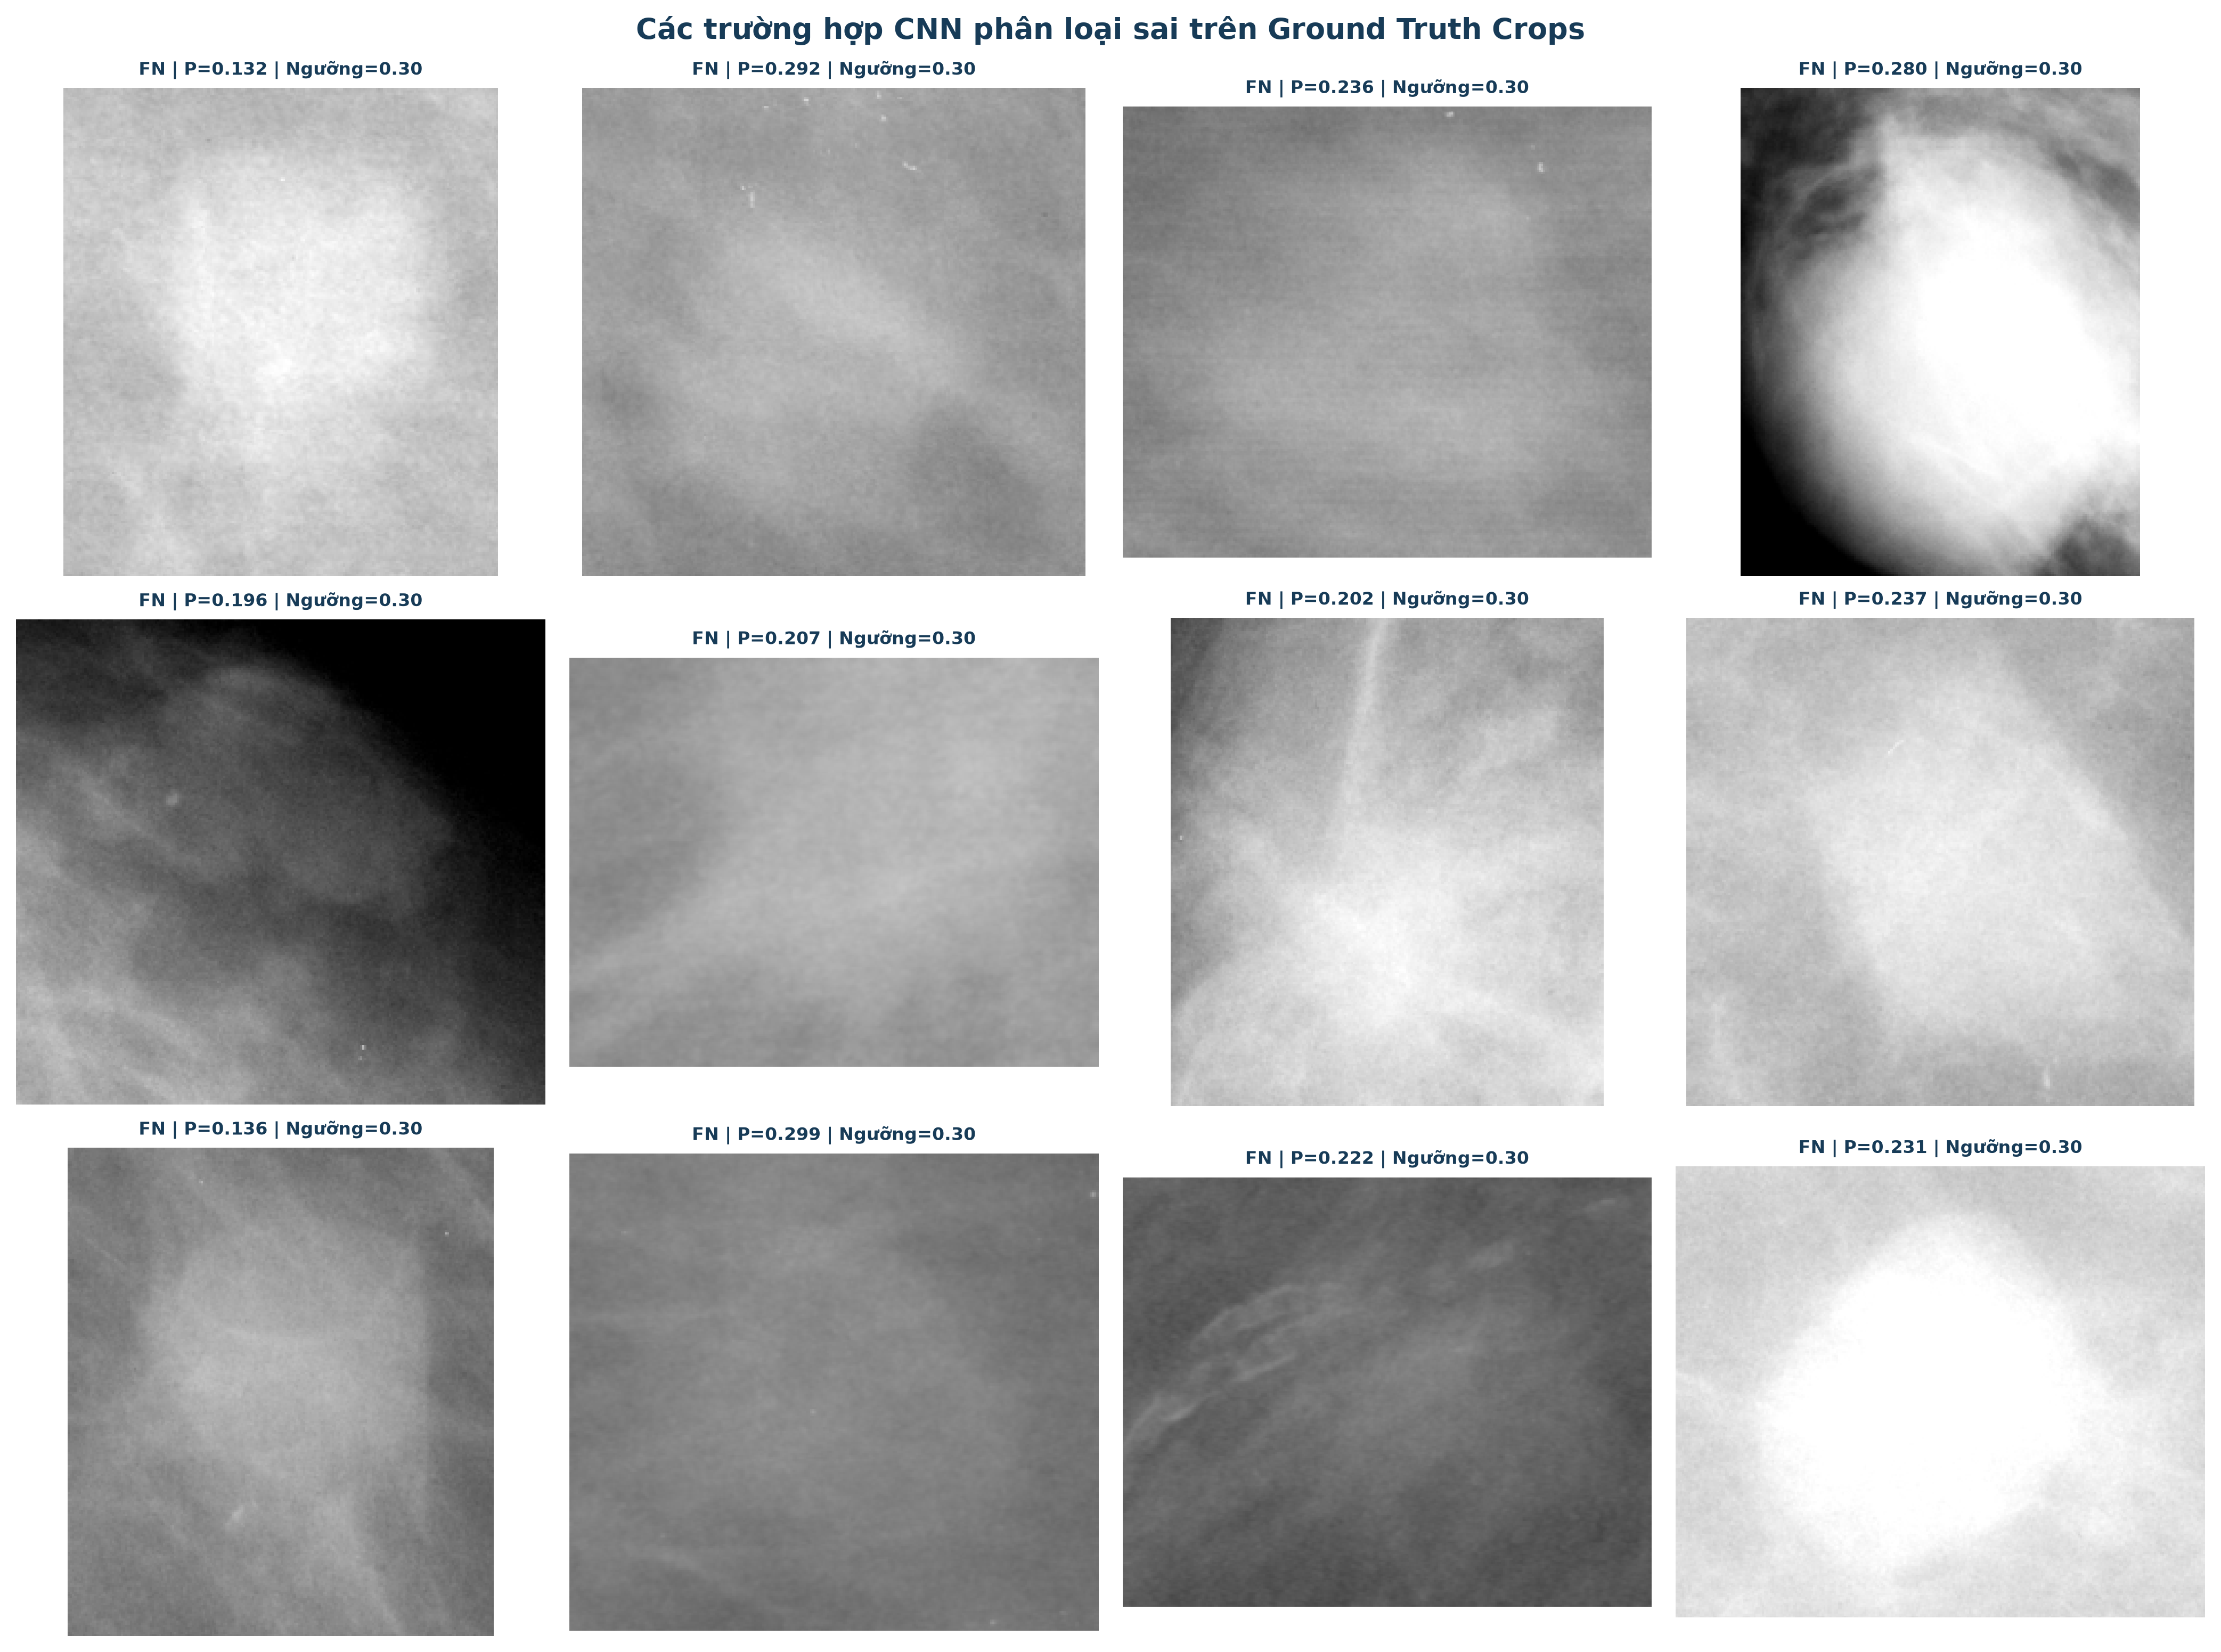

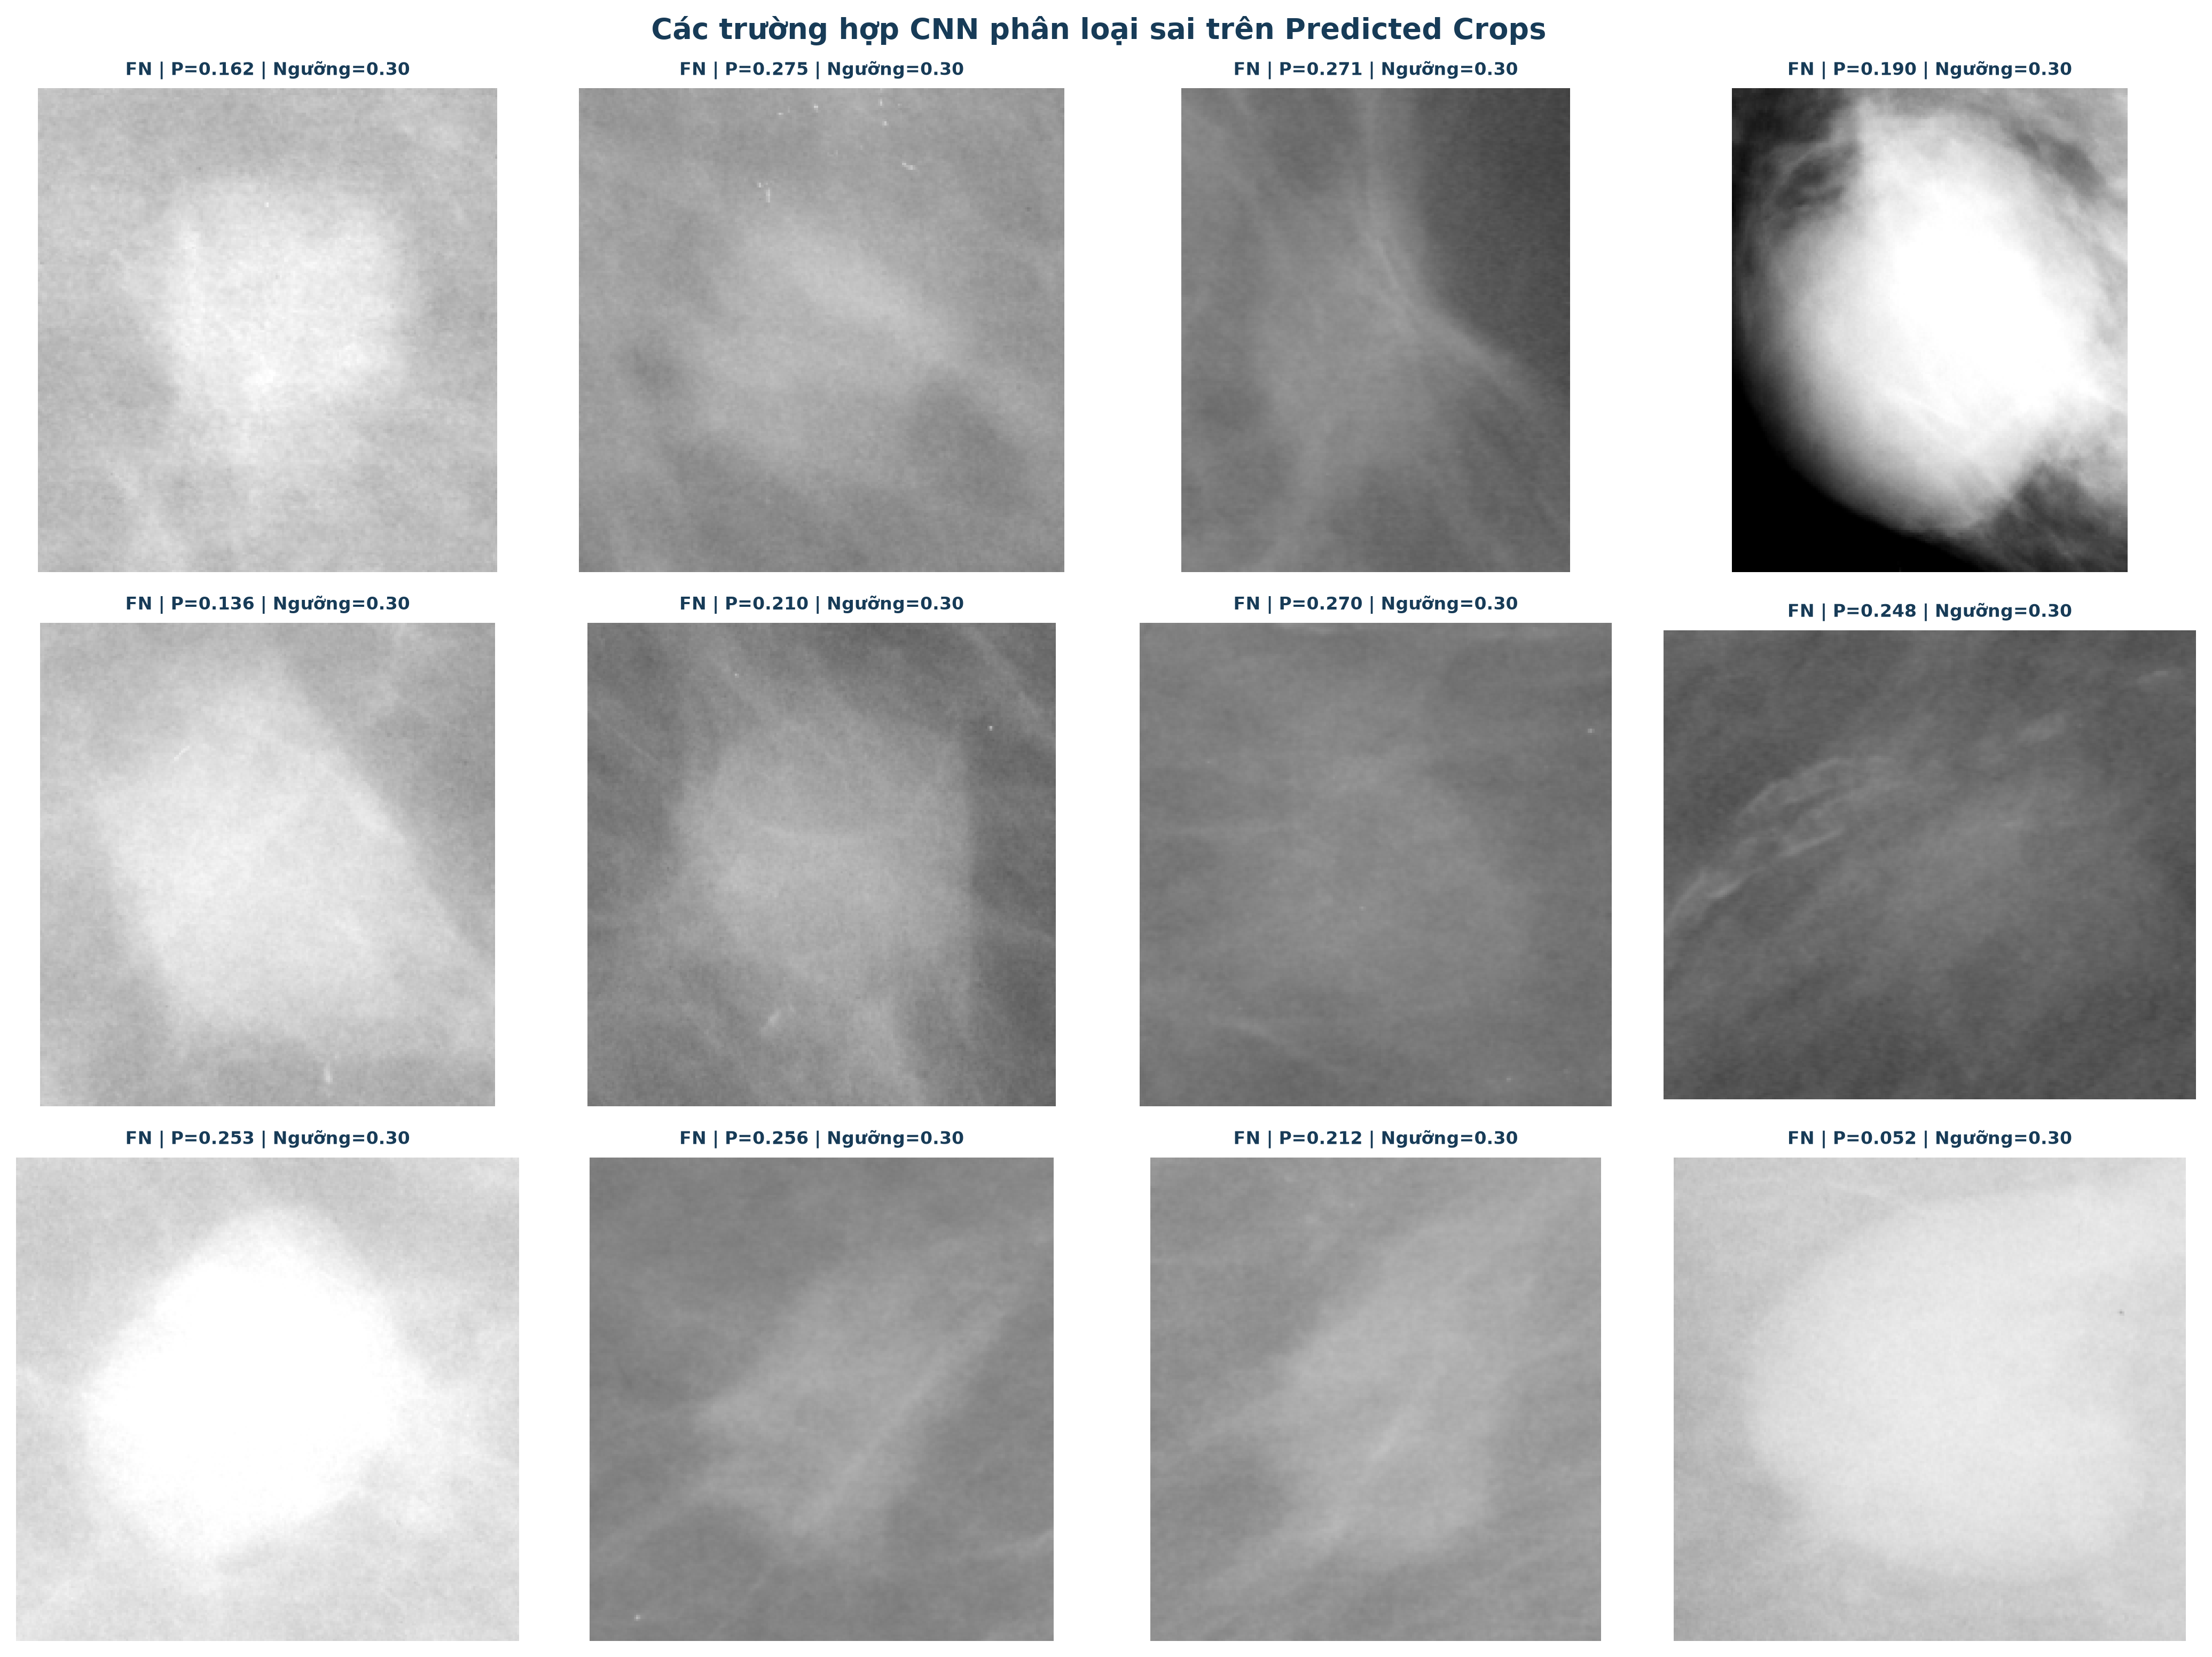


BẢNG 1 — LỖI CNN TRÊN GROUND TRUTH CROPS


,CNN,Correct,FN,FP,Total_Errors,Total_Samples,Error_Rate
0,VGG16,227,32,119,151,378,0.3995
1,ResNet50,247,61,70,131,378,0.3466
2,InceptionV3,235,19,124,143,378,0.3783



BẢNG 2 — LỖI YOLO DETECTION


,YOLO,TP,FP,FN,Predictions,TP_Images,FP_Images,FN_Images,FP_Mean_Confidence,FP_Median_Confidence,TP_Mean_Confidence,TP_Median_Confidence,TP_Mean_IoU
0,Baseline 640,206,137,172,343,202,122,164,0.3802,0.3543,0.5451,0.5434,0.7422
1,Fine-tuned 640,226,211,152,437,222,169,146,0.3322,0.2914,0.5465,0.5540,0.7363



BẢNG 3 — LỖI CNN TRÊN PREDICTED CROPS


,YOLO,CNN,Samples,Correct,FN,FP,Total_Errors,Error_Rate
0,Baseline 640,VGG16,206,140,21,45,66,0.3204
1,Baseline 640,ResNet50,206,146,33,27,60,0.2913
2,Baseline 640,InceptionV3,206,140,10,56,66,0.3204
3,Fine-tuned 640,VGG16,226,143,22,61,83,0.3673
4,Fine-tuned 640,ResNet50,226,158,37,31,68,0.3009
5,Fine-tuned 640,InceptionV3,226,147,14,65,79,0.3496



BẢNG 4 — PHÂN RÃ LỖI TWO-STAGE PIPELINE


,YOLO,CNN,YOLO_Missed_Malignant,CNN_Missed_Malignant,Correct_Malignant,Total_Malignant,E2E_Sensitivity
0,Baseline 640,VGG16,49,21,77,147,0.5238
1,Baseline 640,ResNet50,49,33,65,147,0.4422
2,Baseline 640,InceptionV3,49,10,88,147,0.5986
3,Fine-tuned 640,VGG16,44,22,81,147,0.5510
4,Fine-tuned 640,ResNet50,44,37,66,147,0.4490
5,Fine-tuned 640,InceptionV3,44,14,89,147,0.6054



BẢNG 5 — XÁC SUẤT DỰ ĐOÁN CỦA CÁC TRƯỜNG HỢP CNN PHÂN LOẠI SAI


,CNN,Error_Type,Cases,Mean_Predicted_Probability,Mean_Threshold_Distance,Patients
0,InceptionV3,FN,19,0.1754,0.1246,18
1,InceptionV3,FP,124,0.6037,0.3037,89
2,ResNet50,FN,61,0.3329,0.1671,46
3,ResNet50,FP,70,0.6840,0.1840,60
4,VGG16,FN,32,0.2297,0.0703,24
5,VGG16,FP,119,0.4267,0.1267,84



KIỂM TRA TÍNH TOÀN VẸN
Có đủ 3 mô hình CNN                                                 : PASS
Có đủ 2 cấu hình YOLO                                               : PASS
Có đủ 6 tổ hợp CNN trên Predicted Crops                             : PASS
Có đủ 6 tổ hợp Two-stage Pipeline                                   : PASS
CNN Ground Truth có 378 mẫu mỗi mô hình                             : PASS
Tổng Correct + FN + FP bằng số mẫu Ground Truth                     : PASS
YOLO TP + FP bằng số predictions                                    : PASS
YOLO có tổng 378 annotations                                        : PASS
Baseline có 206 matched crops cho mỗi CNN                           : PASS
Fine-tuned có 226 matched crops cho mỗi CNN                         : PASS
Correct + FN + FP bằng số Predicted Crops                           : PASS
Mỗi tổ hợp phân rã đủ 147 ca MALIGNANT                              : PASS
E2E Sensitivity khớp Correct / 147                                  : PASS
B

In [13]:
# 10.8 — TỔNG HỢP PHÂN TÍCH LỖI VÀ HÌNH ẢNH MINH HỌA

import json
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. THIẾT LẬP ĐƯỜNG DẪN VÀ CẤU HÌNH
# ------------------------------------------------------------

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
PROCESSED_DIR = PROJECT_ROOT / "Data" / "processed"

NB09_DIR = PROCESSED_DIR / "nb09_model_evaluation"
NB09_8_DIR = NB09_DIR / "nb09_8_error_analysis"

NB10_DIR = PROCESSED_DIR / "nb10_research_visualization"
TABLE_DIR = NB10_DIR / "tables"
FIGURE_DIR = NB10_DIR / "figures"
REPORT_DIR = NB10_DIR / "reports"

for folder in [TABLE_DIR, FIGURE_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

OUTPUT_PREFIX = "nb10_8"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.titlesize": 15,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white"
})

COLORS = {
    "correct": "#4C956C",
    "tp": "#4C956C",
    "fn": "#E07A5F",
    "fp": "#F2CC8F",
    "stage1": "#E07A5F",
    "stage2": "#F2CC8F",
    "cnn": "#577590",
    "baseline": "#7895B2",
    "finetuned": "#D17A55",
    "neutral": "#8D99AE"
}

print("Thư mục dự án:", PROJECT_ROOT)
print("Nguồn Notebook 09.8:", NB09_8_DIR)
print("Thư mục lưu kết quả:", NB10_DIR)
print("Nguồn Notebook 09.8 tồn tại:", NB09_8_DIR.exists())


# ------------------------------------------------------------
# 2. KHAI BÁO DỮ LIỆU PHÂN TÍCH LỖI TỪ NOTEBOOK 09.8
# ------------------------------------------------------------

# 2.1. Lỗi CNN trên Ground Truth Crops

cnn_gt_data = [
    {
        "CNN": "VGG16",
        "Correct": 227,
        "FN": 32,
        "FP": 119,
        "Total_Errors": 151,
        "Total_Samples": 378,
        "Error_Rate": 151 / 378
    },
    {
        "CNN": "ResNet50",
        "Correct": 247,
        "FN": 61,
        "FP": 70,
        "Total_Errors": 131,
        "Total_Samples": 378,
        "Error_Rate": 131 / 378
    },
    {
        "CNN": "InceptionV3",
        "Correct": 235,
        "FN": 19,
        "FP": 124,
        "Total_Errors": 143,
        "Total_Samples": 378,
        "Error_Rate": 143 / 378
    }
]

df_cnn_gt = pd.DataFrame(cnn_gt_data)


# 2.2. Lỗi YOLO trên tập Test

yolo_error_data = [
    {
        "YOLO": "Baseline 640",
        "TP": 206,
        "FP": 137,
        "FN": 172,
        "Predictions": 343,
        "TP_Images": 202,
        "FP_Images": 122,
        "FN_Images": 164,
        "FP_Mean_Confidence": 0.380194,
        "FP_Median_Confidence": 0.354299,
        "TP_Mean_Confidence": 0.545097,
        "TP_Median_Confidence": 0.543386,
        "TP_Mean_IoU": 0.742191
    },
    {
        "YOLO": "Fine-tuned 640",
        "TP": 226,
        "FP": 211,
        "FN": 152,
        "Predictions": 437,
        "TP_Images": 222,
        "FP_Images": 169,
        "FN_Images": 146,
        "FP_Mean_Confidence": 0.332211,
        "FP_Median_Confidence": 0.291402,
        "TP_Mean_Confidence": 0.546475,
        "TP_Median_Confidence": 0.554013,
        "TP_Mean_IoU": 0.736318
    }
]

df_yolo_error = pd.DataFrame(yolo_error_data)


# 2.3. Lỗi CNN trên Predicted Crops

predicted_crop_data = [
    {
        "YOLO": "Baseline 640",
        "CNN": "VGG16",
        "Samples": 206,
        "Correct": 140,
        "FN": 21,
        "FP": 45,
        "Total_Errors": 66,
        "Error_Rate": 66 / 206
    },
    {
        "YOLO": "Baseline 640",
        "CNN": "ResNet50",
        "Samples": 206,
        "Correct": 146,
        "FN": 33,
        "FP": 27,
        "Total_Errors": 60,
        "Error_Rate": 60 / 206
    },
    {
        "YOLO": "Baseline 640",
        "CNN": "InceptionV3",
        "Samples": 206,
        "Correct": 140,
        "FN": 10,
        "FP": 56,
        "Total_Errors": 66,
        "Error_Rate": 66 / 206
    },
    {
        "YOLO": "Fine-tuned 640",
        "CNN": "VGG16",
        "Samples": 226,
        "Correct": 143,
        "FN": 22,
        "FP": 61,
        "Total_Errors": 83,
        "Error_Rate": 83 / 226
    },
    {
        "YOLO": "Fine-tuned 640",
        "CNN": "ResNet50",
        "Samples": 226,
        "Correct": 158,
        "FN": 37,
        "FP": 31,
        "Total_Errors": 68,
        "Error_Rate": 68 / 226
    },
    {
        "YOLO": "Fine-tuned 640",
        "CNN": "InceptionV3",
        "Samples": 226,
        "Correct": 147,
        "FN": 14,
        "FP": 65,
        "Total_Errors": 79,
        "Error_Rate": 79 / 226
    }
]

df_predicted_crop = pd.DataFrame(predicted_crop_data)


# 2.4. Phân rã lỗi Two-stage Pipeline

two_stage_data = [
    {
        "YOLO": "Baseline 640",
        "CNN": "VGG16",
        "YOLO_Missed_Malignant": 49,
        "CNN_Missed_Malignant": 21,
        "Correct_Malignant": 77,
        "Total_Malignant": 147,
        "E2E_Sensitivity": 77 / 147
    },
    {
        "YOLO": "Baseline 640",
        "CNN": "ResNet50",
        "YOLO_Missed_Malignant": 49,
        "CNN_Missed_Malignant": 33,
        "Correct_Malignant": 65,
        "Total_Malignant": 147,
        "E2E_Sensitivity": 65 / 147
    },
    {
        "YOLO": "Baseline 640",
        "CNN": "InceptionV3",
        "YOLO_Missed_Malignant": 49,
        "CNN_Missed_Malignant": 10,
        "Correct_Malignant": 88,
        "Total_Malignant": 147,
        "E2E_Sensitivity": 88 / 147
    },
    {
        "YOLO": "Fine-tuned 640",
        "CNN": "VGG16",
        "YOLO_Missed_Malignant": 44,
        "CNN_Missed_Malignant": 22,
        "Correct_Malignant": 81,
        "Total_Malignant": 147,
        "E2E_Sensitivity": 81 / 147
    },
    {
        "YOLO": "Fine-tuned 640",
        "CNN": "ResNet50",
        "YOLO_Missed_Malignant": 44,
        "CNN_Missed_Malignant": 37,
        "Correct_Malignant": 66,
        "Total_Malignant": 147,
        "E2E_Sensitivity": 66 / 147
    },
    {
        "YOLO": "Fine-tuned 640",
        "CNN": "InceptionV3",
        "YOLO_Missed_Malignant": 44,
        "CNN_Missed_Malignant": 14,
        "Correct_Malignant": 89,
        "Total_Malignant": 147,
        "E2E_Sensitivity": 89 / 147
    }
]

df_two_stage = pd.DataFrame(two_stage_data)


# 2.5. Thống kê xác suất của các trường hợp FN và FP trên Ground Truth Crops

probability_data = [
    {
        "CNN": "InceptionV3",
        "Error_Type": "FN",
        "Cases": 19,
        "Mean_Predicted_Probability": 0.175416,
        "Mean_Threshold_Distance": 0.124584,
        "Patients": 18
    },
    {
        "CNN": "InceptionV3",
        "Error_Type": "FP",
        "Cases": 124,
        "Mean_Predicted_Probability": 0.603739,
        "Mean_Threshold_Distance": 0.303739,
        "Patients": 89
    },
    {
        "CNN": "ResNet50",
        "Error_Type": "FN",
        "Cases": 61,
        "Mean_Predicted_Probability": 0.332885,
        "Mean_Threshold_Distance": 0.167115,
        "Patients": 46
    },
    {
        "CNN": "ResNet50",
        "Error_Type": "FP",
        "Cases": 70,
        "Mean_Predicted_Probability": 0.684046,
        "Mean_Threshold_Distance": 0.184046,
        "Patients": 60
    },
    {
        "CNN": "VGG16",
        "Error_Type": "FN",
        "Cases": 32,
        "Mean_Predicted_Probability": 0.229715,
        "Mean_Threshold_Distance": 0.070285,
        "Patients": 24
    },
    {
        "CNN": "VGG16",
        "Error_Type": "FP",
        "Cases": 119,
        "Mean_Predicted_Probability": 0.426721,
        "Mean_Threshold_Distance": 0.126721,
        "Patients": 84
    }
]

df_probability = pd.DataFrame(probability_data)


# ------------------------------------------------------------
# 3. TẠO BẢNG TỔNG HỢP VÀ XUẤT CSV
# ------------------------------------------------------------

tables = {
    "cnn_ground_truth_errors": df_cnn_gt,
    "yolo_detection_errors": df_yolo_error,
    "cnn_predicted_crop_errors": df_predicted_crop,
    "two_stage_error_decomposition": df_two_stage,
    "cnn_error_probability_summary": df_probability
}

for table_name, dataframe in tables.items():
    output_path = TABLE_DIR / f"{OUTPUT_PREFIX}_{table_name}.csv"
    dataframe.to_csv(output_path, index=False, encoding="utf-8-sig")

print("\nĐã xuất các bảng phân tích lỗi:")
for table_name, dataframe in tables.items():
    print(f"{table_name}: {len(dataframe)} dòng")


# ------------------------------------------------------------
# 4. BIỂU ĐỒ 1 — LỖI CNN TRÊN GROUND TRUTH CROPS
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5.8))

x = np.arange(len(df_cnn_gt))
width = 0.58

ax.bar(
    x,
    df_cnn_gt["Correct"],
    width,
    label="Dự đoán đúng",
    color=COLORS["correct"]
)

ax.bar(
    x,
    df_cnn_gt["FN"],
    width,
    bottom=df_cnn_gt["Correct"],
    label="False Negative",
    color=COLORS["fn"]
)

bottom_fp = df_cnn_gt["Correct"] + df_cnn_gt["FN"]

ax.bar(
    x,
    df_cnn_gt["FP"],
    width,
    bottom=bottom_fp,
    label="False Positive",
    color=COLORS["fp"]
)

for i, row in df_cnn_gt.iterrows():
    ax.text(
        i,
        row["Total_Samples"] + 7,
        f"Lỗi: {row['Total_Errors']}\n{row['Error_Rate']:.1%}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

ax.set_xticks(x)
ax.set_xticklabels(df_cnn_gt["CNN"])
ax.set_ylabel("Số lượng mẫu")
ax.set_title("Phân bố dự đoán đúng và lỗi của CNN trên Ground Truth Crops")
ax.set_ylim(0, 435)
ax.grid(axis="y", alpha=0.22)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)

fig.tight_layout()

fig1_path = FIGURE_DIR / f"{OUTPUT_PREFIX}_figure_01_cnn_ground_truth_errors.png"
fig.savefig(fig1_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 5. BIỂU ĐỒ 2 — LỖI YOLO DETECTION TRÊN TEST
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9.5, 5.5))

x = np.arange(len(df_yolo_error))
width = 0.23

ax.bar(
    x - width,
    df_yolo_error["TP"],
    width,
    label="True Positive",
    color=COLORS["tp"]
)

ax.bar(
    x,
    df_yolo_error["FP"],
    width,
    label="False Positive",
    color=COLORS["fp"]
)

ax.bar(
    x + width,
    df_yolo_error["FN"],
    width,
    label="False Negative",
    color=COLORS["fn"]
)

for column, offset in [("TP", -width), ("FP", 0), ("FN", width)]:
    for i, value in enumerate(df_yolo_error[column]):
        ax.text(
            i + offset,
            value + 5,
            str(int(value)),
            ha="center",
            fontsize=9,
            fontweight="bold"
        )

ax.set_xticks(x)
ax.set_xticklabels(df_yolo_error["YOLO"])
ax.set_ylabel("Số lượng bounding box")
ax.set_title("So sánh TP, FP và FN của hai cấu hình YOLO trên tập Test")
ax.grid(axis="y", alpha=0.22)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)

fig.tight_layout()

fig2_path = FIGURE_DIR / f"{OUTPUT_PREFIX}_figure_02_yolo_detection_errors.png"
fig.savefig(fig2_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 6. BIỂU ĐỒ 3 — LỖI CNN TRÊN PREDICTED CROPS
# ------------------------------------------------------------

plot_predicted = df_predicted_crop.copy()
plot_predicted["Combination"] = (
    plot_predicted["YOLO"].str.replace(" 640", "", regex=False)
    + "\n"
    + plot_predicted["CNN"]
)

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(plot_predicted))
width = 0.24

ax.bar(
    x - width,
    plot_predicted["Correct"],
    width,
    label="Dự đoán đúng",
    color=COLORS["correct"]
)

ax.bar(
    x,
    plot_predicted["FN"],
    width,
    label="False Negative",
    color=COLORS["fn"]
)

ax.bar(
    x + width,
    plot_predicted["FP"],
    width,
    label="False Positive",
    color=COLORS["fp"]
)

ax.set_xticks(x)
ax.set_xticklabels(plot_predicted["Combination"])
ax.set_ylabel("Số lượng mẫu")
ax.set_title("Phân tích lỗi CNN trên các crop được YOLO phát hiện")
ax.grid(axis="y", alpha=0.22)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)

for i, row in plot_predicted.iterrows():
    ax.text(
        i,
        row["Samples"] + 3,
        f"Lỗi {row['Total_Errors']}\n{row['Error_Rate']:.1%}",
        ha="center",
        va="bottom",
        fontsize=8,
        fontweight="bold"
    )

ax.set_ylim(0, 275)
fig.tight_layout()

fig3_path = FIGURE_DIR / f"{OUTPUT_PREFIX}_figure_03_cnn_predicted_crop_errors.png"
fig.savefig(fig3_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 7. BIỂU ĐỒ 4 — PHÂN RÃ LỖI MALIGNANT TRONG TWO-STAGE PIPELINE
# ------------------------------------------------------------

plot_two_stage = df_two_stage.copy()
plot_two_stage["Combination"] = (
    plot_two_stage["YOLO"].str.replace(" 640", "", regex=False)
    + "\n"
    + plot_two_stage["CNN"]
)

fig, ax = plt.subplots(figsize=(13, 6.5))

x = np.arange(len(plot_two_stage))
width = 0.62

ax.bar(
    x,
    plot_two_stage["YOLO_Missed_Malignant"],
    width,
    label="Bỏ sót tại Stage 1 — YOLO",
    color=COLORS["stage1"]
)

ax.bar(
    x,
    plot_two_stage["CNN_Missed_Malignant"],
    width,
    bottom=plot_two_stage["YOLO_Missed_Malignant"],
    label="Bỏ sót tại Stage 2 — CNN",
    color=COLORS["stage2"]
)

bottom_correct = (
    plot_two_stage["YOLO_Missed_Malignant"]
    + plot_two_stage["CNN_Missed_Malignant"]
)

ax.bar(
    x,
    plot_two_stage["Correct_Malignant"],
    width,
    bottom=bottom_correct,
    label="Nhận diện đúng MALIGNANT",
    color=COLORS["correct"]
)

for i, row in plot_two_stage.iterrows():
    ax.text(
        i,
        row["Total_Malignant"] + 3,
        f"{row['E2E_Sensitivity']:.1%}",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

ax.set_xticks(x)
ax.set_xticklabels(plot_two_stage["Combination"])
ax.set_ylabel("Số ca MALIGNANT")
ax.set_title("Phân rã 147 trường hợp MALIGNANT qua hai giai đoạn")
ax.set_ylim(0, 175)
ax.grid(axis="y", alpha=0.22)
ax.legend(ncol=1, loc="upper left", frameon=False)

fig.tight_layout()

fig4_path = FIGURE_DIR / f"{OUTPUT_PREFIX}_figure_04_two_stage_malignant_decomposition.png"
fig.savefig(fig4_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 8. BIỂU ĐỒ 5 — XÁC SUẤT DỰ ĐOÁN TRUNG BÌNH CỦA CÁC LỖI CNN
# ------------------------------------------------------------

probability_pivot = df_probability.pivot(
    index="CNN",
    columns="Error_Type",
    values="Mean_Predicted_Probability"
).reindex(["VGG16", "ResNet50", "InceptionV3"])

fig, ax = plt.subplots(figsize=(9.5, 5.5))

x = np.arange(len(probability_pivot))
width = 0.32

ax.bar(
    x - width / 2,
    probability_pivot["FN"],
    width,
    label="False Negative",
    color=COLORS["fn"]
)

ax.bar(
    x + width / 2,
    probability_pivot["FP"],
    width,
    label="False Positive",
    color=COLORS["fp"]
)

for i, model in enumerate(probability_pivot.index):
    fn_value = probability_pivot.loc[model, "FN"]
    fp_value = probability_pivot.loc[model, "FP"]

    ax.text(
        i - width / 2,
        fn_value + 0.015,
        f"{fn_value:.3f}",
        ha="center",
        fontsize=9
    )

    ax.text(
        i + width / 2,
        fp_value + 0.015,
        f"{fp_value:.3f}",
        ha="center",
        fontsize=9
    )

ax.set_xticks(x)
ax.set_xticklabels(probability_pivot.index)
ax.set_ylabel("Xác suất dự đoán MALIGNANT trung bình")
ax.set_ylim(0, 0.8)
ax.set_title("Xác suất dự đoán trung bình của các trường hợp CNN phân loại sai")
ax.grid(axis="y", alpha=0.22)
ax.legend(frameon=False)

fig.tight_layout()

fig5_path = FIGURE_DIR / f"{OUTPUT_PREFIX}_figure_05_cnn_error_probability.png"
fig.savefig(fig5_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 9. TÌM VÀ SAO CHÉP HÌNH ẢNH MINH HỌA CÓ SẴN TỪ NOTEBOOK 09.8
# ------------------------------------------------------------

# Chỉ sử dụng ảnh đã tồn tại trong thư mục Notebook 09.8.
# Không tự tạo bounding box hoặc thay đổi nội dung ảnh gốc.

illustration_dir = FIGURE_DIR / f"{OUTPUT_PREFIX}_source_illustrations"
illustration_dir.mkdir(parents=True, exist_ok=True)

image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}

candidate_images = []

if NB09_8_DIR.exists():
    for image_path in NB09_8_DIR.rglob("*"):
        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in image_extensions:
            continue

        name_lower = image_path.name.lower()

        # Ưu tiên các ảnh montage minh họa lỗi đã được Notebook 09.8 tạo.
        if (
            "montage" in name_lower
            or "misclassified" in name_lower
            or "misclass" in name_lower
            or "figure_06" in name_lower
            or "figure_07" in name_lower
        ):
            candidate_images.append(image_path)

copied_illustrations = []
invalid_illustrations = []

for index, source_path in enumerate(candidate_images, start=1):
    try:
        with Image.open(source_path) as img:
            img.verify()

        destination_path = (
            illustration_dir
            / f"{OUTPUT_PREFIX}_illustration_{index:02d}{source_path.suffix.lower()}"
        )

        shutil.copy2(source_path, destination_path)
        copied_illustrations.append(destination_path)

    except Exception as error:
        invalid_illustrations.append({
            "file": str(source_path),
            "error": str(error)
        })

print("\nHình ảnh minh họa tìm thấy:", len(candidate_images))
print("Hình ảnh hợp lệ đã sao chép:", len(copied_illustrations))
print("Hình ảnh không hợp lệ:", len(invalid_illustrations))

for image_path in copied_illustrations:
    print("Ảnh:", image_path.name)


# ------------------------------------------------------------
# 10. HIỂN THỊ HÌNH ẢNH MINH HỌA NẾU CÓ
# ------------------------------------------------------------

if copied_illustrations:
    for image_path in copied_illustrations:
        try:
            with Image.open(image_path) as img:
                display(img.copy())
        except Exception as error:
            print("Không thể hiển thị:", image_path.name, "|", error)
else:
    print(
        "Không tìm thấy ảnh montage phù hợp trong Notebook 09.8. "
        "Các biểu đồ thống kê lỗi vẫn được tạo bình thường."
    )


# ------------------------------------------------------------
# 11. KIỂM TRA TÍNH TOÀN VẸN DỮ LIỆU VÀ KẾT QUẢ
# ------------------------------------------------------------

integrity_checks = {}

# Kiểm tra số lượng mô hình và tổ hợp
integrity_checks["Có đủ 3 mô hình CNN"] = (
    set(df_cnn_gt["CNN"]) == {"VGG16", "ResNet50", "InceptionV3"}
)

integrity_checks["Có đủ 2 cấu hình YOLO"] = (
    len(df_yolo_error) == 2
)

integrity_checks["Có đủ 6 tổ hợp CNN trên Predicted Crops"] = (
    len(df_predicted_crop) == 6
)

integrity_checks["Có đủ 6 tổ hợp Two-stage Pipeline"] = (
    len(df_two_stage) == 6
)

# Kiểm tra tổng số mẫu Ground Truth Crops
integrity_checks["CNN Ground Truth có 378 mẫu mỗi mô hình"] = (
    (df_cnn_gt["Total_Samples"] == 378).all()
)

integrity_checks["Tổng Correct + FN + FP bằng số mẫu Ground Truth"] = (
    (
        df_cnn_gt["Correct"]
        + df_cnn_gt["FN"]
        + df_cnn_gt["FP"]
        == df_cnn_gt["Total_Samples"]
    ).all()
)

# Kiểm tra YOLO
integrity_checks["YOLO TP + FP bằng số predictions"] = (
    (
        df_yolo_error["TP"] + df_yolo_error["FP"]
        == df_yolo_error["Predictions"]
    ).all()
)

integrity_checks["YOLO có tổng 378 annotations"] = (
    (
        df_yolo_error["TP"]
        + df_yolo_error["FN"]
        == 378
    ).all()
)

# Kiểm tra Predicted Crops
integrity_checks["Baseline có 206 matched crops cho mỗi CNN"] = (
    (
        df_predicted_crop.loc[
            df_predicted_crop["YOLO"] == "Baseline 640", "Samples"
        ] == 206
    ).all()
)

integrity_checks["Fine-tuned có 226 matched crops cho mỗi CNN"] = (
    (
        df_predicted_crop.loc[
            df_predicted_crop["YOLO"] == "Fine-tuned 640", "Samples"
        ] == 226
    ).all()
)

integrity_checks["Correct + FN + FP bằng số Predicted Crops"] = (
    (
        df_predicted_crop["Correct"]
        + df_predicted_crop["FN"]
        + df_predicted_crop["FP"]
        == df_predicted_crop["Samples"]
    ).all()
)

# Kiểm tra phân rã Two-stage
decomposition_sum = (
    df_two_stage["YOLO_Missed_Malignant"]
    + df_two_stage["CNN_Missed_Malignant"]
    + df_two_stage["Correct_Malignant"]
)

integrity_checks["Mỗi tổ hợp phân rã đủ 147 ca MALIGNANT"] = (
    (decomposition_sum == 147).all()
)

integrity_checks["E2E Sensitivity khớp Correct / 147"] = (
    np.allclose(
        df_two_stage["E2E_Sensitivity"],
        df_two_stage["Correct_Malignant"] / 147
    )
)

# Kiểm tra số ca Stage 1 bỏ sót nhất quán giữa các CNN
baseline_stage1 = df_two_stage.loc[
    df_two_stage["YOLO"] == "Baseline 640",
    "YOLO_Missed_Malignant"
]

finetuned_stage1 = df_two_stage.loc[
    df_two_stage["YOLO"] == "Fine-tuned 640",
    "YOLO_Missed_Malignant"
]

integrity_checks["Baseline bỏ sót 49 ca MALIGNANT"] = (
    (baseline_stage1 == 49).all()
)

integrity_checks["Fine-tuned bỏ sót 44 ca MALIGNANT"] = (
    (finetuned_stage1 == 44).all()
)

# Kiểm tra các chỉ số tỷ lệ
integrity_checks["Error Rate nằm trong khoảng 0–1"] = (
    df_cnn_gt["Error_Rate"].between(0, 1).all()
    and df_predicted_crop["Error_Rate"].between(0, 1).all()
)

integrity_checks["E2E Sensitivity nằm trong khoảng 0–1"] = (
    df_two_stage["E2E_Sensitivity"].between(0, 1).all()
)


# ------------------------------------------------------------
# 12. KIỂM TRA CÁC FILE ĐẦU RA
# ------------------------------------------------------------

output_files = [
    FIGURE_DIR / f"{OUTPUT_PREFIX}_figure_01_cnn_ground_truth_errors.png",
    FIGURE_DIR / f"{OUTPUT_PREFIX}_figure_02_yolo_detection_errors.png",
    FIGURE_DIR / f"{OUTPUT_PREFIX}_figure_03_cnn_predicted_crop_errors.png",
    FIGURE_DIR / f"{OUTPUT_PREFIX}_figure_04_two_stage_malignant_decomposition.png",
    FIGURE_DIR / f"{OUTPUT_PREFIX}_figure_05_cnn_error_probability.png"
]

for table_name in tables:
    output_files.append(
        TABLE_DIR / f"{OUTPUT_PREFIX}_{table_name}.csv"
    )

integrity_checks["5 biểu đồ được tạo thành công"] = all(
    path.exists() and path.stat().st_size > 0
    for path in output_files[:5]
)

integrity_checks["5 bảng CSV được xuất thành công"] = all(
    path.exists() and path.stat().st_size > 0
    for path in output_files[5:]
)

# Đọc lại CSV để kiểm tra khả năng truy xuất
csv_readback_pass = True

for table_name in tables:
    csv_path = TABLE_DIR / f"{OUTPUT_PREFIX}_{table_name}.csv"

    try:
        check_df = pd.read_csv(csv_path)
        if check_df.empty:
            csv_readback_pass = False
    except Exception:
        csv_readback_pass = False

integrity_checks["Đọc lại toàn bộ CSV thành công"] = csv_readback_pass


# ------------------------------------------------------------
# 13. XÁC ĐỊNH TỔ HỢP TWO-STAGE DẪN ĐẦU VÀ TẠO BÁO CÁO JSON
# ------------------------------------------------------------

best_combination = df_two_stage.loc[
    df_two_stage["E2E_Sensitivity"].idxmax()
].to_dict()

best_combination = {
    key: (
        value.item() if isinstance(value, np.generic)
        else value
    )
    for key, value in best_combination.items()
}

report = {
    "notebook_section": "10.8",
    "section_name": "Tổng hợp phân tích lỗi và hình ảnh minh họa",
    "evaluation_scope": "Test",
    "source": "Notebook 09.8 - Error Analysis",
    "cnn_ground_truth_models": int(len(df_cnn_gt)),
    "yolo_configurations": int(len(df_yolo_error)),
    "predicted_crop_combinations": int(len(df_predicted_crop)),
    "two_stage_combinations": int(len(df_two_stage)),
    "best_two_stage_combination": best_combination,
    "illustration_images_found": int(len(candidate_images)),
    "illustration_images_copied": int(len(copied_illustrations)),
    "integrity_checks": {
        key: bool(value)
        for key, value in integrity_checks.items()
    },
    "all_checks_pass": bool(all(integrity_checks.values())),
    "output_files": [str(path) for path in output_files]
}

json_path = REPORT_DIR / f"{OUTPUT_PREFIX}_integrity_report.json"

with open(json_path, "w", encoding="utf-8") as file:
    json.dump(
        report,
        file,
        ensure_ascii=False,
        indent=4
    )

# Đọc lại JSON
with open(json_path, "r", encoding="utf-8") as file:
    report_check = json.load(file)

integrity_checks["Báo cáo JSON đọc lại thành công"] = (
    isinstance(report_check, dict)
    and report_check.get("notebook_section") == "10.8"
    and isinstance(report_check.get("integrity_checks"), dict)
)

# Cập nhật trạng thái cuối cùng sau kiểm tra JSON
report["integrity_checks"] = {
    key: bool(value)
    for key, value in integrity_checks.items()
}

report["all_checks_pass"] = bool(all(integrity_checks.values()))

with open(json_path, "w", encoding="utf-8") as file:
    json.dump(
        report,
        file,
        ensure_ascii=False,
        indent=4
    )


# ------------------------------------------------------------
# 14. HIỂN THỊ BẢNG KẾT QUẢ VÀ TỔNG KẾT
# ------------------------------------------------------------

print("\nBẢNG 1 — LỖI CNN TRÊN GROUND TRUTH CROPS")
display(df_cnn_gt.round(4))

print("\nBẢNG 2 — LỖI YOLO DETECTION")
display(df_yolo_error.round(4))

print("\nBẢNG 3 — LỖI CNN TRÊN PREDICTED CROPS")
display(df_predicted_crop.round(4))

print("\nBẢNG 4 — PHÂN RÃ LỖI TWO-STAGE PIPELINE")
display(df_two_stage.round(4))

print("\nBẢNG 5 — XÁC SUẤT DỰ ĐOÁN CỦA CÁC TRƯỜNG HỢP CNN PHÂN LOẠI SAI")
display(df_probability.round(4))

print("\nKIỂM TRA TÍNH TOÀN VẸN")

for check_name, check_result in integrity_checks.items():
    print(
        f"{check_name:<68}: "
        f"{'PASS' if check_result else 'FAIL'}"
    )

print("\nTỔNG HỢP NOTEBOOK 10.8")
print("Số mô hình CNN Ground Truth :", len(df_cnn_gt))
print("Số cấu hình YOLO            :", len(df_yolo_error))
print("Số tổ hợp Predicted Crops   :", len(df_predicted_crop))
print("Số tổ hợp Two-stage         :", len(df_two_stage))
print("Số biểu đồ                  :", 5)
print("Số bảng CSV                 :", len(tables))
print("Ảnh minh họa đã sao chép    :", len(copied_illustrations))
print("JSON                         :", "PASS" if json_path.exists() else "FAIL")
print("Trạng thái                  :", "PASS" if all(integrity_checks.values()) else "FAIL")
print("Thư mục kết quả             :", NB10_DIR)


In [14]:
# 10.9 — TỔNG HỢP, XUẤT KẾT QUẢ VÀ KIỂM TRA TOÀN VẸN NOTEBOOK 10

import re
import shutil
import zipfile
import hashlib
import warnings
from PIL import Image
from IPython.display import display

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. THIẾT LẬP ĐƯỜNG DẪN
# ------------------------------------------------------------

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
PROCESSED_DIR = PROJECT_ROOT / "Data" / "processed"

NB10_DIR = PROCESSED_DIR / "nb10_research_visualization"

TABLE_DIR = NB10_DIR / "tables"
FIGURE_DIR = NB10_DIR / "figures"
REPORT_DIR = NB10_DIR / "reports"

# Thư mục tập hợp kết quả cuối cùng
FINAL_DIR = NB10_DIR / "nb10_final_results"
FINAL_TABLE_DIR = FINAL_DIR / "tables"
FINAL_FIGURE_DIR = FINAL_DIR / "figures"
FINAL_REPORT_DIR = FINAL_DIR / "reports"

FINAL_MANIFEST_PATH = FINAL_REPORT_DIR / "nb10_final_file_manifest.csv"
FINAL_REPORT_PATH = FINAL_REPORT_DIR / "nb10_final_integrity_report.json"

ZIP_PATH = NB10_DIR / "nb10_final_results_bundle.zip"

for folder in [
    FINAL_TABLE_DIR,
    FINAL_FIGURE_DIR,
    FINAL_REPORT_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Thư mục dự án:", PROJECT_ROOT)
print("Thư mục Notebook 10:", NB10_DIR)
print("Thư mục kết quả cuối:", FINAL_DIR)


# ------------------------------------------------------------
# 2. THU THẬP CÁC FILE ĐẦU RA TỪ NOTEBOOK 10.3–10.8
# ------------------------------------------------------------

source_directories = {
    "tables": TABLE_DIR,
    "figures": FIGURE_DIR,
    "reports": REPORT_DIR
}

supported_extensions = {
    ".csv",
    ".png",
    ".json"
}

source_files = []

for category, source_dir in source_directories.items():

    if not source_dir.exists():
        continue

    for file_path in source_dir.rglob("*"):

        if not file_path.is_file():
            continue

        if file_path.suffix.lower() not in supported_extensions:
            continue

        # Không thu thập file nằm trong thư mục kết quả cuối.
        if FINAL_DIR in file_path.parents:
            continue

        source_files.append({
            "category": category,
            "path": file_path
        })

source_files = sorted(
    source_files,
    key=lambda item: (
        item["category"],
        str(item["path"]).lower()
    )
)

print("\nSố file đầu ra tìm thấy:", len(source_files))

for category in source_directories:
    count = sum(
        item["category"] == category
        for item in source_files
    )
    print(f"{category:<12}: {count} file")


# ------------------------------------------------------------
# 3. KIỂM TRA FILE NGUỒN VÀ PHÂN LOẠI THEO NOTEBOOK
# ------------------------------------------------------------

source_inventory = []
source_validation = []

for item in source_files:

    file_path = item["path"]
    category = item["category"]

    match = re.search(
        r"nb10_(\d+)",
        file_path.name.lower()
    )

    section = (
        f"10.{match.group(1)}"
        if match
        else "Khác"
    )

    file_size = file_path.stat().st_size

    file_valid = file_size > 0
    validation_message = "PASS"

    try:

        if file_path.suffix.lower() == ".csv":

            df_check = pd.read_csv(file_path)

            if df_check.empty:
                file_valid = False
                validation_message = "CSV rỗng"

        elif file_path.suffix.lower() == ".png":

            with Image.open(file_path) as image:
                image.verify()

        elif file_path.suffix.lower() == ".json":

            with open(file_path, "r", encoding="utf-8") as file:
                json.load(file)

    except Exception as error:

        file_valid = False
        validation_message = str(error)

    source_inventory.append({
        "Section": section,
        "Category": category,
        "File_Name": file_path.name,
        "File_Extension": file_path.suffix.lower(),
        "File_Size_Bytes": int(file_size),
        "Source_Path": str(file_path),
        "Source_Valid": bool(file_valid),
        "Validation_Message": validation_message
    })

    source_validation.append(bool(file_valid))


df_source_inventory = pd.DataFrame(source_inventory)

print("\nKIỂM TRA FILE NGUỒN")
print("Tổng số file:", len(df_source_inventory))
print("File hợp lệ:", sum(source_validation))
print("File không hợp lệ:", len(source_validation) - sum(source_validation))

if not df_source_inventory.empty:
    display(
        df_source_inventory[
            [
                "Section",
                "Category",
                "File_Name",
                "File_Size_Bytes",
                "Source_Valid"
            ]
        ].head(30)
    )


# ------------------------------------------------------------
# 4. THỐNG KÊ SỐ LƯỢNG FILE THEO TỪNG PHẦN
# ------------------------------------------------------------

if not df_source_inventory.empty:

    section_summary = (
        df_source_inventory
        .groupby(["Section", "Category"])
        .size()
        .unstack(fill_value=0)
        .reset_index()
    )

else:

    section_summary = pd.DataFrame(
        columns=["Section", "tables", "figures", "reports"]
    )

print("\nTHỐNG KÊ FILE THEO PHẦN")
display(section_summary)


# ------------------------------------------------------------
# 5. XÁC ĐỊNH CÁC PHẦN 10.3–10.8 ĐÃ CÓ KẾT QUẢ
# ------------------------------------------------------------

expected_sections = [
    "10.3",
    "10.4",
    "10.5",
    "10.6",
    "10.7",
    "10.8"
]

available_sections = set(
    df_source_inventory["Section"].tolist()
) if not df_source_inventory.empty else set()

section_file_counts = {
    section: int(
        (df_source_inventory["Section"] == section).sum()
    )
    if not df_source_inventory.empty
    else 0
    for section in expected_sections
}

print("\nKIỂM TRA KẾT QUẢ THEO PHẦN")

for section in expected_sections:
    print(
        f"{section}: "
        f"{section_file_counts[section]} file"
    )


# ------------------------------------------------------------
# 6. SAO CHÉP KẾT QUẢ VÀO THƯ MỤC CUỐI
# ------------------------------------------------------------

copy_records = []

for item in source_files:

    source_path = item["path"]
    category = item["category"]

    if category == "tables":
        destination_dir = FINAL_TABLE_DIR

    elif category == "figures":
        destination_dir = FINAL_FIGURE_DIR

    else:
        destination_dir = FINAL_REPORT_DIR

    destination_path = destination_dir / source_path.name

    try:

        shutil.copy2(
            source_path,
            destination_path
        )

        copy_records.append({
            "Category": category,
            "File_Name": source_path.name,
            "Source_Path": str(source_path),
            "Destination_Path": str(destination_path),
            "Copied": bool(destination_path.exists()),
            "File_Size_Bytes": int(destination_path.stat().st_size)
        })

    except Exception as error:

        copy_records.append({
            "Category": category,
            "File_Name": source_path.name,
            "Source_Path": str(source_path),
            "Destination_Path": str(destination_path),
            "Copied": False,
            "File_Size_Bytes": 0,
            "Error": str(error)
        })

df_copy_manifest = pd.DataFrame(copy_records)

print("\nSAO CHÉP FILE")
print("Tổng file:", len(df_copy_manifest))
print(
    "Sao chép thành công:",
    int(df_copy_manifest["Copied"].sum())
    if not df_copy_manifest.empty else 0
)


# ------------------------------------------------------------
# 7. TẠO DANH MỤC FILE KẾT QUẢ CUỐI CÙNG
# ------------------------------------------------------------

final_manifest_records = []

for item in copy_records:

    destination_path = Path(item["Destination_Path"])

    if not destination_path.exists():
        continue

    final_manifest_records.append({
        "Category": item["Category"],
        "File_Name": item["File_Name"],
        "File_Size_Bytes": int(destination_path.stat().st_size),
        "Destination_Path": str(destination_path),
        "SHA256": hashlib.sha256(
            destination_path.read_bytes()
        ).hexdigest()
    })

df_final_manifest = pd.DataFrame(final_manifest_records)

df_final_manifest.to_csv(
    FINAL_MANIFEST_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("\nDANH MỤC FILE KẾT QUẢ")
print("Số file trong danh mục:", len(df_final_manifest))
print("File danh mục:", FINAL_MANIFEST_PATH)


# ------------------------------------------------------------
# 8. KIỂM TRA LẠI CÁC FILE ĐÃ SAO CHÉP
# ------------------------------------------------------------

copied_validation = []

for item in copy_records:

    destination_path = Path(item["Destination_Path"])

    valid = False

    try:

        if not destination_path.exists():
            raise FileNotFoundError(destination_path)

        if destination_path.stat().st_size <= 0:
            raise ValueError("File rỗng")

        extension = destination_path.suffix.lower()

        if extension == ".csv":

            check_df = pd.read_csv(destination_path)

            if check_df.empty:
                raise ValueError("CSV rỗng")

        elif extension == ".png":

            with Image.open(destination_path) as image:
                image.verify()

        elif extension == ".json":

            with open(destination_path, "r", encoding="utf-8") as file:
                json.load(file)

        valid = True

    except Exception as error:

        print(
            "Lỗi kiểm tra:",
            destination_path.name,
            "|",
            error
        )

    copied_validation.append(valid)

copied_valid_count = sum(copied_validation)


# ------------------------------------------------------------
# 9. KIỂM TRA CẤU TRÚC THƯ MỤC VÀ SỐ LƯỢNG FILE
# ------------------------------------------------------------

final_csv_files = list(FINAL_TABLE_DIR.glob("*.csv"))
final_png_files = list(FINAL_FIGURE_DIR.glob("*.png"))
final_json_files = list(FINAL_REPORT_DIR.glob("*.json"))

print("\nTHỐNG KÊ THƯ MỤC KẾT QUẢ CUỐI")
print("Bảng CSV :", len(final_csv_files))
print("Biểu đồ  :", len(final_png_files))
print("Báo cáo JSON:", len(final_json_files))


# ------------------------------------------------------------
# 10. TẠO FILE ZIP TẬP HỢP KẾT QUẢ
# ------------------------------------------------------------

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

zip_file_count = 0

with zipfile.ZipFile(
    ZIP_PATH,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as zip_file:

    for file_path in FINAL_DIR.rglob("*"):

        if not file_path.is_file():
            continue

        relative_path = file_path.relative_to(FINAL_DIR.parent)

        zip_file.write(
            file_path,
            arcname=str(relative_path)
        )

        zip_file_count += 1

print("\nFILE ZIP")
print("Đường dẫn:", ZIP_PATH)
print("Số file được đóng gói:", zip_file_count)
print(
    "Dung lượng ZIP:",
    round(ZIP_PATH.stat().st_size / (1024 ** 2), 2),
    "MB"
)


# ------------------------------------------------------------
# 11. KIỂM TRA FILE ZIP
# ------------------------------------------------------------

zip_valid = False
zip_internal_count = 0

try:

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:

        bad_file = zip_file.testzip()

        zip_internal_count = len(zip_file.namelist())

        zip_valid = (
            bad_file is None
            and zip_internal_count == zip_file_count
        )

except Exception as error:

    print("Lỗi kiểm tra ZIP:", error)


# ------------------------------------------------------------
# 12. KIỂM TRA TÍNH TOÀN VẸN CUỐI CÙNG
# ------------------------------------------------------------

integrity_checks = {}

integrity_checks["Có thư mục tables"] = FINAL_TABLE_DIR.exists()
integrity_checks["Có thư mục figures"] = FINAL_FIGURE_DIR.exists()
integrity_checks["Có thư mục reports"] = FINAL_REPORT_DIR.exists()

integrity_checks["Tìm thấy file đầu ra Notebook 10"] = (
    len(source_files) > 0
)

integrity_checks["Có kết quả từ Notebook 10.3–10.8"] = (
    all(
        section_file_counts[section] > 0
        for section in expected_sections
    )
)

integrity_checks["Toàn bộ file nguồn đọc được"] = (
    len(source_validation) > 0
    and all(source_validation)
)

integrity_checks["Sao chép đầy đủ file"] = (
    len(copy_records) == len(source_files)
    and all(
        item["Copied"]
        for item in copy_records
    )
)

integrity_checks["Toàn bộ file đã sao chép đọc được"] = (
    len(copied_validation) > 0
    and all(copied_validation)
)

integrity_checks["Có danh mục file cuối cùng"] = (
    FINAL_MANIFEST_PATH.exists()
    and FINAL_MANIFEST_PATH.stat().st_size > 0
)

integrity_checks["Đọc lại danh mục file thành công"] = False

try:

    manifest_check = pd.read_csv(FINAL_MANIFEST_PATH)

    integrity_checks["Đọc lại danh mục file thành công"] = (
        len(manifest_check) == len(copy_records)
    )

except Exception:
    pass

integrity_checks["File ZIP tồn tại"] = ZIP_PATH.exists()
integrity_checks["File ZIP toàn vẹn"] = bool(zip_valid)


# ------------------------------------------------------------
# 13. TẠO BÁO CÁO JSON CUỐI CÙNG
# ------------------------------------------------------------

final_report = {
    "notebook": "Notebook 10",
    "title": "Research Visualization and Results Presentation",
    "project_root": str(PROJECT_ROOT),
    "output_directory": str(FINAL_DIR),
    "source_directory": str(NB10_DIR),
    "sections_included": expected_sections,
    "source_file_count": int(len(source_files)),
    "copied_file_count": int(len(copy_records)),
    "copied_valid_file_count": int(copied_valid_count),
    "table_count": int(len(final_csv_files)),
    "figure_count": int(len(final_png_files)),
    "json_report_count": int(len(final_json_files)),
    "zip_path": str(ZIP_PATH),
    "zip_file_count": int(zip_internal_count),
    "zip_size_bytes": int(ZIP_PATH.stat().st_size) if ZIP_PATH.exists() else 0,
    "integrity_checks": {
        key: bool(value)
        for key, value in integrity_checks.items()
    },
    "all_checks_pass": bool(all(integrity_checks.values()))
}

with open(FINAL_REPORT_PATH, "w", encoding="utf-8") as file:
    json.dump(
        final_report,
        file,
        ensure_ascii=False,
        indent=4
    )

# Đọc lại báo cáo JSON
with open(FINAL_REPORT_PATH, "r", encoding="utf-8") as file:
    final_report_check = json.load(file)

json_readback_pass = (
    final_report_check.get("notebook") == "Notebook 10"
    and final_report_check.get("source_file_count") == len(source_files)
)

integrity_checks["Báo cáo JSON đọc lại thành công"] = bool(
    json_readback_pass
)

final_report["integrity_checks"] = {
    key: bool(value)
    for key, value in integrity_checks.items()
}

final_report["all_checks_pass"] = bool(
    all(integrity_checks.values())
)

with open(FINAL_REPORT_PATH, "w", encoding="utf-8") as file:
    json.dump(
        final_report,
        file,
        ensure_ascii=False,
        indent=4
    )


# ------------------------------------------------------------
# 14. HIỂN THỊ BẢNG DANH MỤC VÀ KẾT QUẢ KIỂM TRA
# ------------------------------------------------------------

print("\nDANH MỤC FILE ĐÃ TẬP HỢP")
display(
    df_final_manifest[
        [
            "Category",
            "File_Name",
            "File_Size_Bytes"
        ]
    ].head(50)
)

print("\nKIỂM TRA TÍNH TOÀN VẸN NOTEBOOK 10")

for check_name, check_result in integrity_checks.items():

    print(
        f"{check_name:<58}: "
        f"{'PASS' if check_result else 'FAIL'}"
    )

print("\nTỔNG KẾT NOTEBOOK 10")

print("Số file nguồn              :", len(source_files))
print("Số file đã sao chép        :", len(copy_records))
print("Số file hợp lệ sau sao chép:", copied_valid_count)
print("Số bảng CSV                :", len(final_csv_files))
print("Số biểu đồ                 :", len(final_png_files))
print("Số báo cáo JSON            :", len(final_json_files))
print("Số file trong ZIP          :", zip_internal_count)
print(
    "Trạng thái                 :",
    "PASS" if all(integrity_checks.values()) else "FAIL"
)

print("\nTHƯ MỤC KẾT QUẢ CUỐI:")
print(FINAL_DIR)

print("\nFILE ZIP:")
print(ZIP_PATH)

print("\nBÁO CÁO KIỂM TRA:")
print(FINAL_REPORT_PATH)


Thư mục dự án: C:\Breast-Cancer-CBIS-DDSM
Thư mục Notebook 10: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb10_research_visualization
Thư mục kết quả cuối: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb10_research_visualization\nb10_final_results

Số file đầu ra tìm thấy: 63
tables      : 31 file
figures     : 24 file
reports     : 8 file

KIỂM TRA FILE NGUỒN
Tổng số file: 63
File hợp lệ: 63
File không hợp lệ: 0


,Section,Category,File_Name,File_Size_Bytes,Source_Valid
0,10.3,figures,nb10_3_figure_01_pathology_distribution.png,96280,True
1,10.3,figures,nb10_3_figure_02_dataset_split.png,107829,True
2,10.3,figures,nb10_3_figure_03_detection_dataset_scale.png,111972,True
3,10.3,figures,nb10_3_figure_04_dataset_construction_pipeline.png,335398,True
4,10.4,figures,nb10_4_figure_01_yolo_map_comparison.png,158321,True
5,10.4,figures,nb10_4_figure_02_cnn_validation_metrics.png,167138,True
6,10.4,figures,nb10_4_figure_03_cnn_validation_loss_best_epoch.png,167375,True
7,10.5,figures,nb10_5_figure_01_yolo_test_metrics.png,166305,True
8,10.5,figures,nb10_5_figure_02_yolo_operating_counts.png,132951,True
9,10.5,figures,nb10_5_figure_03_yolo_operating_metrics.png,138208,True



THỐNG KÊ FILE THEO PHẦN


Category,Section,figures,reports,tables
0,10.2,0,1,8
1,10.3,4,1,5
2,10.4,3,1,3
3,10.5,3,1,3
4,10.6,4,1,4
5,10.7,3,1,3
6,10.8,7,1,5
7,Khác,0,1,0



KIỂM TRA KẾT QUẢ THEO PHẦN
10.3: 10 file
10.4: 7 file
10.5: 7 file
10.6: 9 file
10.7: 7 file
10.8: 13 file

SAO CHÉP FILE
Tổng file: 63
Sao chép thành công: 63

DANH MỤC FILE KẾT QUẢ
Số file trong danh mục: 63
File danh mục: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb10_research_visualization\nb10_final_results\reports\nb10_final_file_manifest.csv

THỐNG KÊ THƯ MỤC KẾT QUẢ CUỐI
Bảng CSV : 31
Biểu đồ  : 24
Báo cáo JSON: 8

FILE ZIP
Đường dẫn: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb10_research_visualization\nb10_final_results_bundle.zip
Số file được đóng gói: 64
Dung lượng ZIP: 4.73 MB

DANH MỤC FILE ĐÃ TẬP HỢP


,Category,File_Name,File_Size_Bytes
0,figures,nb10_3_figure_01_pathology_distribution.png,96280
1,figures,nb10_3_figure_02_dataset_split.png,107829
2,figures,nb10_3_figure_03_detection_dataset_scale.png,111972
3,figures,nb10_3_figure_04_dataset_construction_pipeline.png,335398
4,figures,nb10_4_figure_01_yolo_map_comparison.png,158321
5,figures,nb10_4_figure_02_cnn_validation_metrics.png,167138
6,figures,nb10_4_figure_03_cnn_validation_loss_best_epoch.png,167375
7,figures,nb10_5_figure_01_yolo_test_metrics.png,166305
8,figures,nb10_5_figure_02_yolo_operating_counts.png,132951
9,figures,nb10_5_figure_03_yolo_operating_metrics.png,138208



KIỂM TRA TÍNH TOÀN VẸN NOTEBOOK 10
Có thư mục tables                                         : PASS
Có thư mục figures                                        : PASS
Có thư mục reports                                        : PASS
Tìm thấy file đầu ra Notebook 10                          : PASS
Có kết quả từ Notebook 10.3–10.8                          : PASS
Toàn bộ file nguồn đọc được                               : PASS
Sao chép đầy đủ file                                      : PASS
Toàn bộ file đã sao chép đọc được                         : PASS
Có danh mục file cuối cùng                                : PASS
Đọc lại danh mục file thành công                          : PASS
File ZIP tồn tại                                          : PASS
File ZIP toàn vẹn                                         : PASS
Báo cáo JSON đọc lại thành công                           : PASS

TỔNG KẾT NOTEBOOK 10
Số file nguồn              : 63
Số file đã sao chép        : 63
Số file hợp lệ sau sao chép: 63
S

### TỔNG KẾT NOTEBOOK 10

### Mục tiêu và nội dung thực hiện
Notebook 10 tổng hợp, trực quan hóa và chuẩn hóa toàn bộ kết quả từ Notebook 05 đến Notebook 09 phục vụ khóa luận tốt nghiệp, gồm:
- Thống kê dữ liệu, quá trình huấn luyện `YOLOv5n` và ba mô hình CNN (`VGG16`, `ResNet50`, `InceptionV3`).
- Đối chiếu hiệu năng phát hiện (`YOLO`), phân loại (`Ground Truth` & `Predicted Crops`) và phối hợp `Two-stage Pipeline`.
- Phân tích lỗi (`TP`, `FP`, `FN`), xuất dữ liệu và kiểm định tính toàn vẹn kết quả.

### Kết quả tổng hợp

| Thành phần lưu trữ | Định dạng / Thư mục | Số lượng | Kiểm định |
| :--- | :--- | :---: | :---: |
| Bảng dữ liệu | `tables/` (`.csv`) | 31 | PASS |
| Biểu đồ trực quan | `figures/` (`.png`) | 24 | PASS |
| Báo cáo & Danh mục | `reports/` (`.json`) | 8 | PASS |
| **Tổng cộng** | `nb10_final_results/` & `.zip` | **63** | **63/63 PASS** |

- **Tổ hợp nổi bật:** `Fine-tuned YOLOv5n 640` + `InceptionV3` đạt *End-to-End Malignant Sensitivity* cao nhất (**89/147 ca**, tương ứng **60,54%**).
- **Giới hạn diễn giải:** Kết quả chỉ phản ánh hiệu năng trên tập Test theo ngưỡng cố định từ Validation, không dùng làm chỉ số xác nhận chẩn đoán lâm sàng.

### Lưu trữ và kết luận
- Toàn bộ **63 tệp** được đồng bộ tại `Data/processed/nb10_research_visualization/nb10_final_results`, đóng gói thành `nb10_final_results_bundle.zip` và xác minh hợp lệ qua `nb10_final_integrity_report.json` (**Trạng thái: PASS**).
- **Bước tiếp theo:** Triển khai ứng dụng **Web Demo** minh họa quy trình phát hiện, định vị tổn thương *Mass* và phân loại lành/ác tính theo kiến trúc Two-stage Pipeline.